In [1]:
import os
from collections import defaultdict

import lifelines
import matplotlib.pyplot as plt
import matplotlib
import numpy
import pandas
import pickle
import time
import seaborn as sns

import immuw.clustering.clustering_utils as cimu
import tumorhood_analysis_utils as tau


# Number of enriched cellular neighborhood classes
CC_NB_OF_CLUSTERS = 23
ROI_TYPE_ANALYSIS = 'ALL'

CLUSTER_SELECTION_PATH = f'./NSCLC-Cello-v1-SD-100{CC_NB_OF_CLUSTERS}/'

VECTORIZER = lambda x: x.values.T ** 0.5
VECTORIZER_NAME = 'sqrt'
PANEL_1_CLUSTER_SELECTION_PATH = os.path.join(CLUSTER_SELECTION_PATH, f'p1_cs_result_{ROI_TYPE_ANALYSIS}_{VECTORIZER_NAME}.pickle')

# PREDICTION RELATED 
TYPE = 'sd'
PREDICTIONS_PATH = '/raid/immucan/immuw/image_analysis/analysis/UW/packages/IMMUW/scripts/nsclc_p1_sd_6ls/spatial_directions/clustering_results/0.75:13/kmeans_predictions/kmeans_predictions_23_1.npy'
PREDICTION_CLUSTER_COLUMN = 'Cellular Neighborhood'
CC_CLUSTER_NAME = 'tumorhood_neighborhood_cluster'

# IMAGE/SAMPLE RELATED 
ROI_COLUMN = 'image'
SAMPLE_COLUMN = 'sample_id'

CLINICAL_DATA_DF = 'nsclc_clinical_clean_corrected.csv'


PANEL_1_FULL_CSV_FILEPATH = '/raid/immucan/immuw/data/nsclc2_25_full.df'

# MARKER RELATED
MARKERS = tau.PANEL_1_MARKER_NAMES
MARKERS_CLEAN = [
    'MPO',
    'H3',
    'SMA',
    'CD16',
    'CD38',
    'HLA-DR',
    'CD27',
    'CD15',
    'CD45RA',
    'CD163',
    'B2M',
    'CD20',
    'CD68',
    'Ido1',
    'CD3',
    'LAG3',
    'CD11c',
    'PD1',
    'PDGFRb',
    'CD7',
    'GrB',
    'PDL1',
    'TCF7',
    'CD45RO',
    'FOXP3',
    'ICOS',
    'CD8a',
    'CAIX',
    'CD33',
    'Ki67',
    'VISTA',
    'CD40',
    'CD4',
    'CD14',
    'ECad',
    'CD303',
    'CD206',
    'cl.PARP',
    'DNA1',
    'DNA2',
]

# Clinical Related:
CLINICAL_DATA_COLS_FOR_ANALYSIS = [
    'roman_simple_stage', 
    'stage_2-',
    'simple_histology',
    #'neo_adjuvant_treatment',
    'death', 
    'smoking_status',
    'gender',
    #'environmental_exposure',
    'TPS_score',
    'CPS_score',
    'tmb_class',
    'KRAS', 'TP53', 'EGFR', 'PIK3CA', 'ERBB2'
] 

# Additional Column names
DUMMY_COL_NAME = 'dummy'
CELLTYPE_COLNAME = 'celltypes'
CELLTYPE_PLOT_NAME = 'Cell type'
MARKER_PLOT_NAME = 'Marker'
ALL_PLOT_NAME = 'All'
ROI_CLUSTER_NAME = 'SG'

# Plotting
PLOTTING_DPI = 300
sns.set_context("paper", rc={"font.size": 6, "axes.titlesize":6,"axes.labelsize":6})  
plt.rcParams['legend.title_fontsize'] = 6
plt.rcParams['legend.fontsize'] = 6

matplotlib.font_manager.fontManager.addfont('/raid/immucan/immuw/Arial.ttf')  # if you need to add the font file
plt.rcParams['font.family'] = 'Arial'

## Cell type level data loading and preprocessing

In [2]:
cell_df = pandas.read_csv(PANEL_1_FULL_CSV_FILEPATH)

/tmp/ipykernel_69843/796832730.py:1: DtypeWarning: Columns (15,83,84) have mixed types. Specify dtype option on import or set low_memory=False.
  cell_df = pandas.read_csv(PANEL_1_FULL_CSV_FILEPATH)


In [3]:
# Marker ARCSINH x / 5 transformation
cell_df[MARKERS] =  cell_df[MARKERS].applymap(lambda x: numpy.arcsinh(x / 5.))

In [4]:
# Extra column for computations
cell_df[DUMMY_COL_NAME] = 1

## Prediction level loading

In [5]:
predictions = numpy.load(PREDICTIONS_PATH)

In [6]:
if TYPE == 'bag':
    cell_df[PREDICTION_CLUSTER_COLUMN] = cell_df[CC_CLUSTER_NAME].apply(lambda x: predictions[x])
elif TYPE == 'sd':
    cell_df[PREDICTION_CLUSTER_COLUMN] = predictions
else:
    raise ValueError('Unknown TYPE.')

## TLS / Tumor Core subselection

In [7]:
def roi_is_tls(image_name):
    return image_name[:-5].split('_')[-1] == '004'

In [8]:
TLS_CELL_SELECTOR = cell_df[ROI_COLUMN].apply(lambda x: roi_is_tls(x))
NON_TLS_CELL_SELECTOR = cell_df[ROI_COLUMN].apply(lambda x: not roi_is_tls(x))

In [9]:
TLS_CELL_SELECTOR.sum(), NON_TLS_CELL_SELECTOR.sum(), TLS_CELL_SELECTOR.sum() + NON_TLS_CELL_SELECTOR.sum()

(593052, 1495338, 2088390)

In [10]:
cell_df['ROI_index'] = cell_df[ROI_COLUMN].apply(lambda x:  x[:-5].split('_')[-1])

In [11]:
cell_df[cell_df['ROI_index'] == '004'].groupby('image').size()

image
IMMUcan_Batch20210701_LUNG_10018881-LUNG-VAR-TIS-01-IMC-01_004.tiff    2804
IMMUcan_Batch20210701_LUNG_10018882-LUNG-VAR-TIS-01-IMC-01_004.tiff    2580
IMMUcan_Batch20210701_LUNG_10018884-LUNG-VAR-TIS-01-IMC-01_004.tiff    3548
IMMUcan_Batch20210701_LUNG_10018885-LUNG-VAR-TIS-01-IMC-01_004.tiff    4279
IMMUcan_Batch20210701_LUNG_10018888-LUNG-VAR-TIS-01-IMC-01_004.tiff    2345
                                                                       ... 
IMMUcan_Batch20210921_LUNG_10041586-LUNG-VAR-TIS-01-IMC-01_004.tiff    3978
IMMUcan_Batch20210921_LUNG_10041587-LUNG-VAR-TIS-01-IMC-01_004.tiff    3266
IMMUcan_Batch20210921_LUNG_10041589-LUNG-VAR-TIS-01-IMC-01_004.tiff    3680
IMMUcan_Batch20210921_LUNG_10041591-LUNG-VAR-TIS-01-IMC-01_004.tiff    3339
IMMUcan_Batch20210921_LUNG_10041592-LUNG-VAR-TIS-01-IMC-01_004.tiff    2964
Length: 172, dtype: int64

In [12]:
cell_df[cell_df['ROI_index'] != '004'].groupby('image').size()

image
IMMUcan_Batch20210701_LUNG_10018881-LUNG-VAR-TIS-01-IMC-01_001.tiff    3050
IMMUcan_Batch20210701_LUNG_10018881-LUNG-VAR-TIS-01-IMC-01_002.tiff    2765
IMMUcan_Batch20210701_LUNG_10018881-LUNG-VAR-TIS-01-IMC-01_003.tiff    2381
IMMUcan_Batch20210701_LUNG_10018882-LUNG-VAR-TIS-01-IMC-01_001.tiff    2743
IMMUcan_Batch20210701_LUNG_10018882-LUNG-VAR-TIS-01-IMC-01_002.tiff    2610
                                                                       ... 
IMMUcan_Batch20210921_LUNG_10041591-LUNG-VAR-TIS-01-IMC-01_002.tiff    3216
IMMUcan_Batch20210921_LUNG_10041591-LUNG-VAR-TIS-01-IMC-01_003.tiff    2226
IMMUcan_Batch20210921_LUNG_10041592-LUNG-VAR-TIS-01-IMC-01_001.tiff    3620
IMMUcan_Batch20210921_LUNG_10041592-LUNG-VAR-TIS-01-IMC-01_002.tiff    2868
IMMUcan_Batch20210921_LUNG_10041592-LUNG-VAR-TIS-01-IMC-01_003.tiff    3279
Length: 569, dtype: int64

In [13]:
if ROI_TYPE_ANALYSIS == 'TUMOR':
    cell_df = cell_df[NON_TLS_CELL_SELECTOR]
elif ROI_TYPE_ANALYSIS == 'TLS':
    cell_df = cell_df[TLS_CELL_SELECTOR]
elif ROI_TYPE_ANALYSIS == 'ALL':
    cell_df = cell_df
else:
    raise ValueError('Unknown ROI type analysis')

## Cell type related preparation:

In [14]:
celltype_counts = pandas.pivot_table(
    cell_df, 
    values=DUMMY_COL_NAME, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CELLTYPE_COLNAME],
    aggfunc="sum",
).fillna(0)

In [15]:
celltype_percentages = (celltype_counts.T / celltype_counts.sum(axis=1)).T
celltype_percentages.columns.name = CELLTYPE_PLOT_NAME

In [16]:
celltypes = list(celltype_percentages.columns)

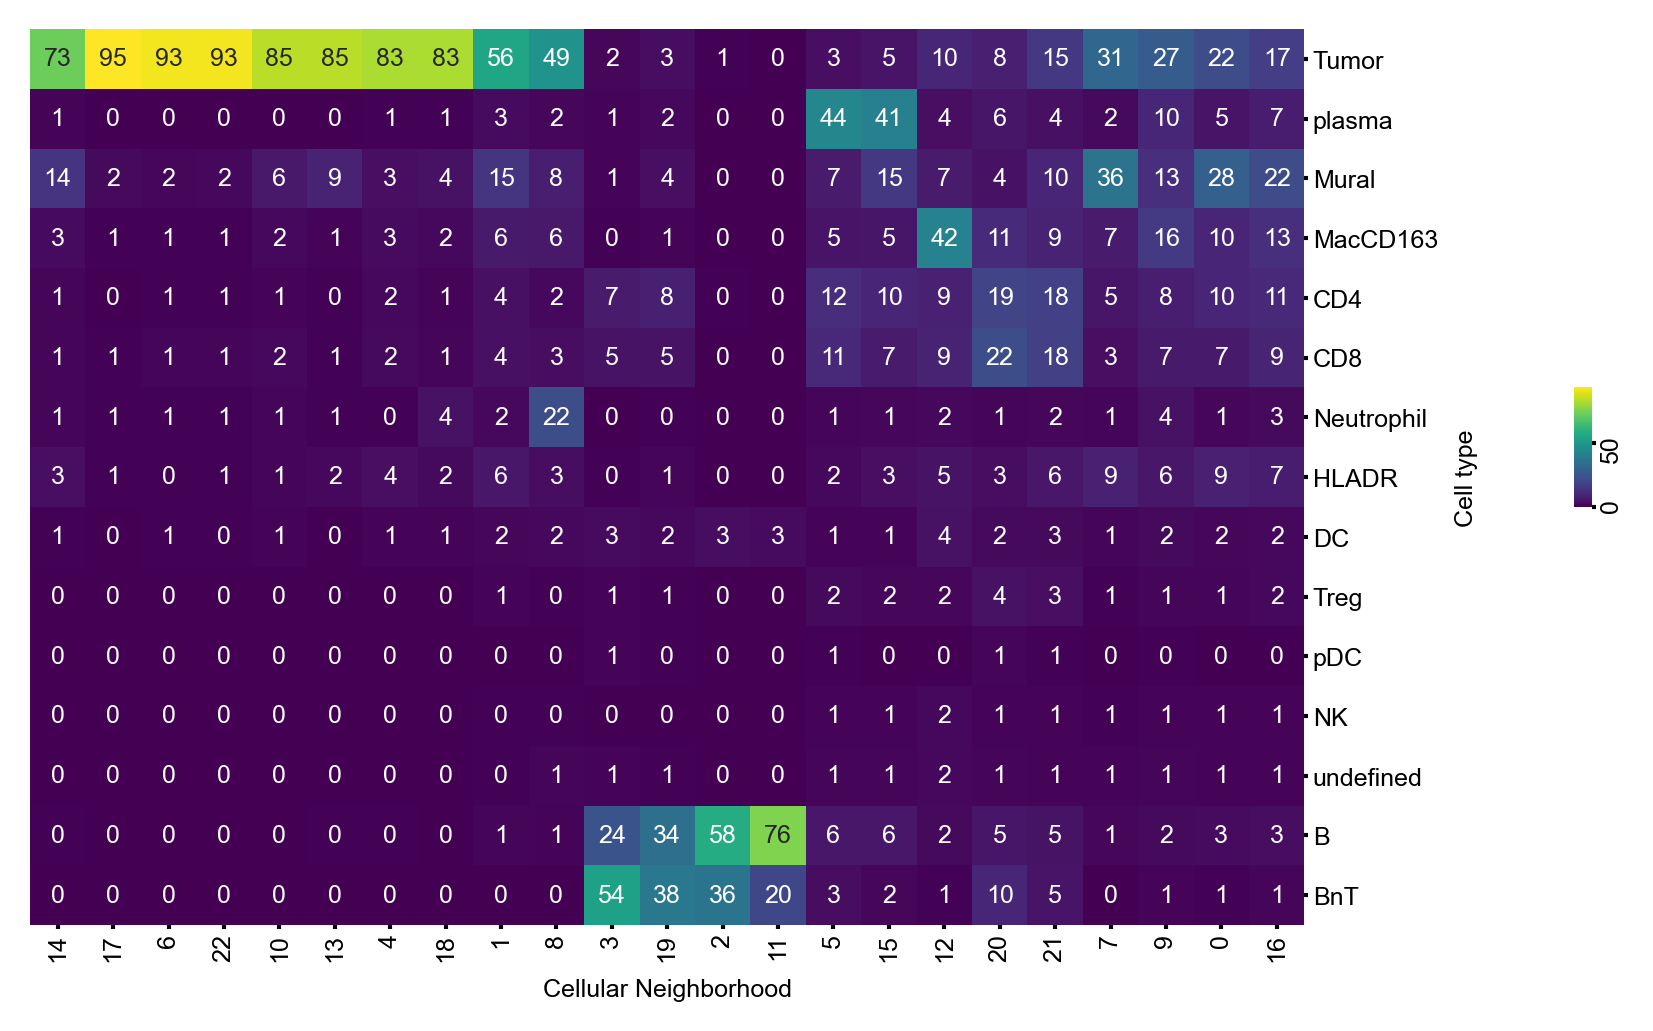

In [17]:
celltype_clustermap = sns.clustermap(
    celltype_percentages[celltypes].T * 100, 
    annot=True,
    #row_colors=celltypes_color_df,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.05, 0.4, 0.01, 0.1),
    annot_kws={"size": 6},
    cbar_kws={'label': ''}
)

#celltype_clustermap.ax_cbar.set_xlabel(f'{CELLTYPE_PLOT_NAME} percentage', labelpad=0, size=6)

celltype_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1, rotation=90)
celltype_clustermap.ax_row_dendrogram.set_visible(False)
celltype_clustermap.ax_col_dendrogram.set_visible(False)

celltype_clustermap.ax_heatmap.set_yticklabels(celltype_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
celltype_clustermap.ax_heatmap.set_xticklabels(celltype_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
#celltype_clustermap.ax_row_colors.set_xticklabels(celltype_clustermap.ax_row_colors.get_xticklabels(), size=6)
#celltype_clustermap.ax_row_colors.xaxis.set_tick_params(size=1, pad=1)

celltype_clustermap.fig.set_dpi(PLOTTING_DPI)
celltype_clustermap.fig.set_size_inches((6, 4))

## Marker analysis

### Cell type level:
For each marker compute the average marker expression for a given cell type:

In [18]:
marker_to_celltype_dfs = {}


for marker in MARKERS:
    marker_to_celltype_dfs[marker] = pandas.pivot_table(
    cell_df, 
    values=marker, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CELLTYPE_COLNAME],
    aggfunc='mean',
).fillna(0)

Now - let us transpose this dictionary to cell type to marker df:

In [19]:
marker_ct_ipc = numpy.stack([
    marker_df.values
    for marker_df in marker_to_celltype_dfs.values()
])

celltype_to_marker_dfs = {
    ct: pandas.DataFrame(
        marker_ct_ipc[:, :, ct_ind],
        index=MARKERS,
    )
    for ct_ind, ct in enumerate(celltypes)
}

Now - let's rename the markers to their clean names:

In [20]:
celltype_to_marker_dfs_clean = {}


for celltype, cdf in celltype_to_marker_dfs.items():
    cdf_clean = cdf.copy()
    cdf_clean[MARKER_PLOT_NAME] = MARKERS_CLEAN
    cdf_clean.set_index(MARKER_PLOT_NAME, inplace=True),
    celltype_to_marker_dfs_clean[celltype] = cdf_clean

## All marker analysis:

Now let's compute the overall marker distribution across all cells:

In [21]:
all_markers_distribution = cell_df.groupby([PREDICTION_CLUSTER_COLUMN]).mean()[MARKERS]
all_markers_distribution -= all_markers_distribution.mean()
all_markers_distribution /= all_markers_distribution.std()
all_markers_distribution.columns = MARKERS_CLEAN

celltype_to_marker_dfs_clean[ALL_PLOT_NAME] = all_markers_distribution.T

/tmp/ipykernel_69843/762203048.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  all_markers_distribution = cell_df.groupby([PREDICTION_CLUSTER_COLUMN]).mean()[MARKERS]


Now let's display the all marker distributions:

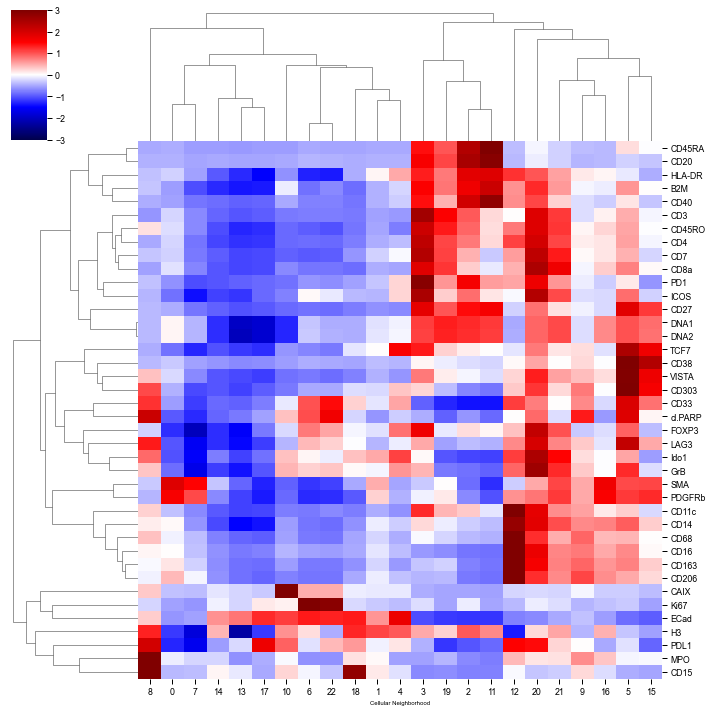

In [22]:
sns.clustermap(all_markers_distribution.T, center=0, cmap='seismic', vmin=-3, vmax=3)

Now - let's visualize the Cellohood Neighobrhoods with average markers.

Let's start with providing some handy tools:
- marker colormap:

In [23]:
marker_color_norm = matplotlib.colors.Normalize(vmin=-2, vmax=2)
marker_cmap = plt.get_cmap('coolwarm')

marker_sm = matplotlib.cm.ScalarMappable(norm=marker_color_norm, cmap=marker_cmap)

and a code to transform values to vectors:

In [24]:
def transform_vec_to_colors(
    vec,
    colors,
    standarize=True,
    display=None,
    permute=None,
    ignore_color=(160 / 255, 160 / 255, 160 / 255),
):
    if standarize:
        display = display if display is not None else numpy.arange(len(vec))
        vec = vec.copy()
        vec = vec - numpy.mean(vec[display])
        vec = vec / numpy.std(vec[display])
    result = [
        colors.to_rgba(x)
        for x in vec
    ]
    if display is not None:
        new_result = []
        for ind_, result_col in enumerate(result):
            current_color = list(result_col)
            if ind_ in display:
                pass 
            else:
                current_color = ignore_color
            new_result.append(current_color)
            
        result = new_result
    if permute:
        result = [
            result[i]
            for i in permute
        ]
    return result

Now let's transform average markers across all cells to colors:

In [25]:
all_colors_dict = {
    f'{marker}': transform_vec_to_colors( 
        vec=celltype_to_marker_dfs_clean[ALL_PLOT_NAME].loc[marker],
        colors=marker_sm,
    )
    for marker in MARKERS_CLEAN
}

all_colors_df = pandas.DataFrame(all_colors_dict)

and visualize CC clusters with average marker distributions:

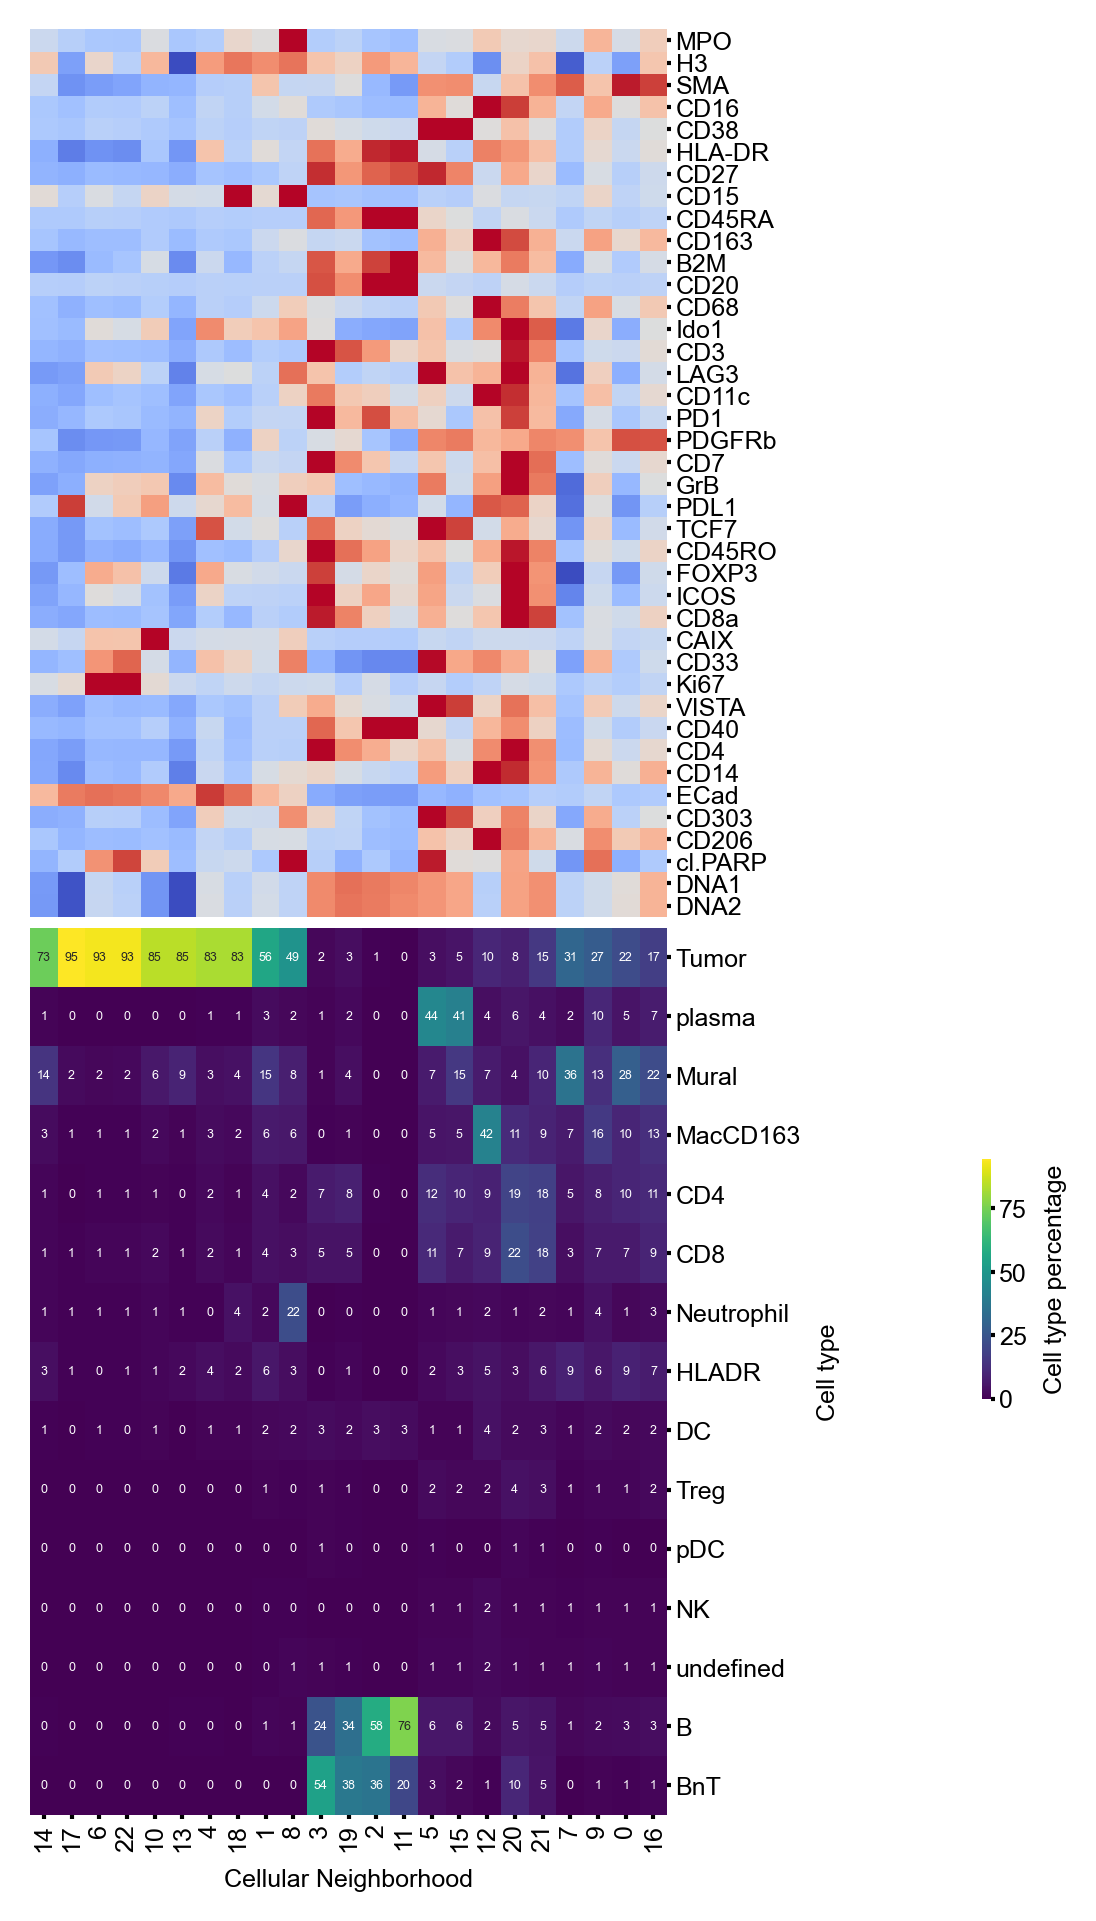

In [26]:
celltype_with_all_markers_clustermap = sns.clustermap(
    celltype_percentages[celltypes].T * 100, 
    annot=True,
    #row_colors=celltypes_color_df,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.25, 0.225, 0.01, 0.1),
    col_colors=all_colors_df,
    annot_kws={'size': 3},
    yticklabels=1,
    colors_ratio=(0.01, 0.01),
    cbar_kws={'label': f'{CELLTYPE_PLOT_NAME} percentage'}
)

celltype_with_all_markers_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_with_all_markers_clustermap.ax_row_dendrogram.set_visible(False)
celltype_with_all_markers_clustermap.ax_col_dendrogram.set_visible(False)

celltype_with_all_markers_clustermap.ax_heatmap.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_with_all_markers_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_with_all_markers_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
celltype_with_all_markers_clustermap.ax_heatmap.set_xticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)

#celltype_with_all_markers_clustermap.ax_row_colors.set_xticklabels(
#    celltype_with_all_markers_clustermap.ax_row_colors.get_xticklabels(), size=6
#)
celltype_with_all_markers_clustermap.ax_col_colors.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_col_colors.get_yticklabels(), size=6
)
celltype_with_all_markers_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

celltype_with_all_markers_clustermap.fig.set_dpi(PLOTTING_DPI)
celltype_with_all_markers_clustermap.fig.set_size_inches((3, 8))


## Density analysis

In [27]:
cc_densities = cell_df.groupby(
    [PREDICTION_CLUSTER_COLUMN, CC_CLUSTER_NAME]
).size().groupby(PREDICTION_CLUSTER_COLUMN).mean()

## Marker Cluster analysis for cell types

Now let's analyse the marker expression for cells within certain Cellohood Clusters:

In [28]:
celltypes_display_percentage = defaultdict(lambda: 0.1)
celltypes_display_percentage['Tumor'] = 0.15
celltypes_display_percentage['CD4'] = 0.05
celltypes_display_percentage['CD8'] = 0.05
#celltypes_display_percentage['Mural'] = 0.14

In [29]:
celltypes_to_marker_to_show = {
    'B': ['CD40', 'CD20', 'CD45RA', 'CD45RO'],
    'CD4': ['CD45RA', 'CD45RO'],
    'CD8': ['PD1', 'GrB', 'CD45RA', 'CD45RO'],
    'MacCD163': [
        'Ido1', 'PDL1', 'CD14', 'CD68', 'CD206', 'CD11c'],
    'Mural': ['SMA', 'PDGFRb'],
    'Tumor': ['DNA1', 'H3', 'ECad', 'cl.PARP', 'CD15', 'CAIX',
        'B2M', 'TCF7', 'PDL1', 'Ki67'],
    'All': ['VISTA', 'ICOS', 'LAG3']
}

In [30]:
celltypes_cc_display = {
    ct: [
        ind_ 
        for ind_, cc_ in enumerate(celltype_percentages[ct] > celltypes_display_percentage[ct])
        if cc_
    ]
    for ct in celltypes_to_marker_to_show
    if ct in celltype_percentages.columns
}

In [31]:
cc_colors_dict = {}
for ct, markers in celltypes_to_marker_to_show.items():
    for marker in markers:
        cc_colors_dict[f'{ct}: {marker}'] = transform_vec_to_colors( 
                vec=celltype_to_marker_dfs_clean[ct].loc[marker],
                colors=marker_sm,
                display=celltypes_cc_display[ct] if ct in celltypes_cc_display else None,
            )


cc_marker_ct_colors = pandas.DataFrame(cc_colors_dict)

cc_marker_ct_colors['All: Cell density'] = transform_vec_to_colors( 
        vec=cc_densities,
        colors=marker_sm,
)

In [32]:
meta_cluster_dict = {
    'PURE_TUMOR': [13, 6, 22, 17, 4, 10, 18],
    'NEUTROPHIL': [8],
    'MURAL': [14, 1, 7, 0, 16],
    'INFILTRATION': [21, 9, 20],
    'MAC': [12],
    'PLASMA': [5, 15],
    'TLS': [3, 19, 2, 11],
}

In [33]:
META_CLUSTER_PERM = []
meta_cluster_colors = []
meta_cluster_names = []


for mc, cls_ in meta_cluster_dict.items():
        for index_ in cls_:
            meta_cluster_colors.append(tau.META_CLUSTER_TO_COLOR[mc])
            META_CLUSTER_PERM.append(index_)
            meta_cluster_names.append(mc)

In [34]:
META_CLUSTER_PERM

[13,
 6,
 22,
 17,
 4,
 10,
 18,
 8,
 14,
 1,
 7,
 0,
 16,
 21,
 9,
 20,
 12,
 5,
 15,
 3,
 19,
 2,
 11]

In [35]:
IMMU_METAS_CLEAN = [
    'Pure Tumor',
    'Neutrophil-enriched',
    'Mural-enriched',
    'Plasma cell-enriched',
    'Infiltration',
    'Mac-enriched',
    'CD20+',
]

IMMU_METAS = [
    'PURE_TUMOR', 'NEUTROPHIL', 'MURAL', 'PLASMA', 'INFILTRATION', 'MAC', 'TLS'
]

In [36]:
IMMU_METAS

['PURE_TUMOR', 'NEUTROPHIL', 'MURAL', 'PLASMA', 'INFILTRATION', 'MAC', 'TLS']

In [37]:
cc_marker_ct_colors['CN Class'] = numpy.array(meta_cluster_colors)[numpy.argsort(META_CLUSTER_PERM)]

/tmp/ipykernel_69843/925969494.py:94: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/tmp/ipykernel_69843/925969494.py:94: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


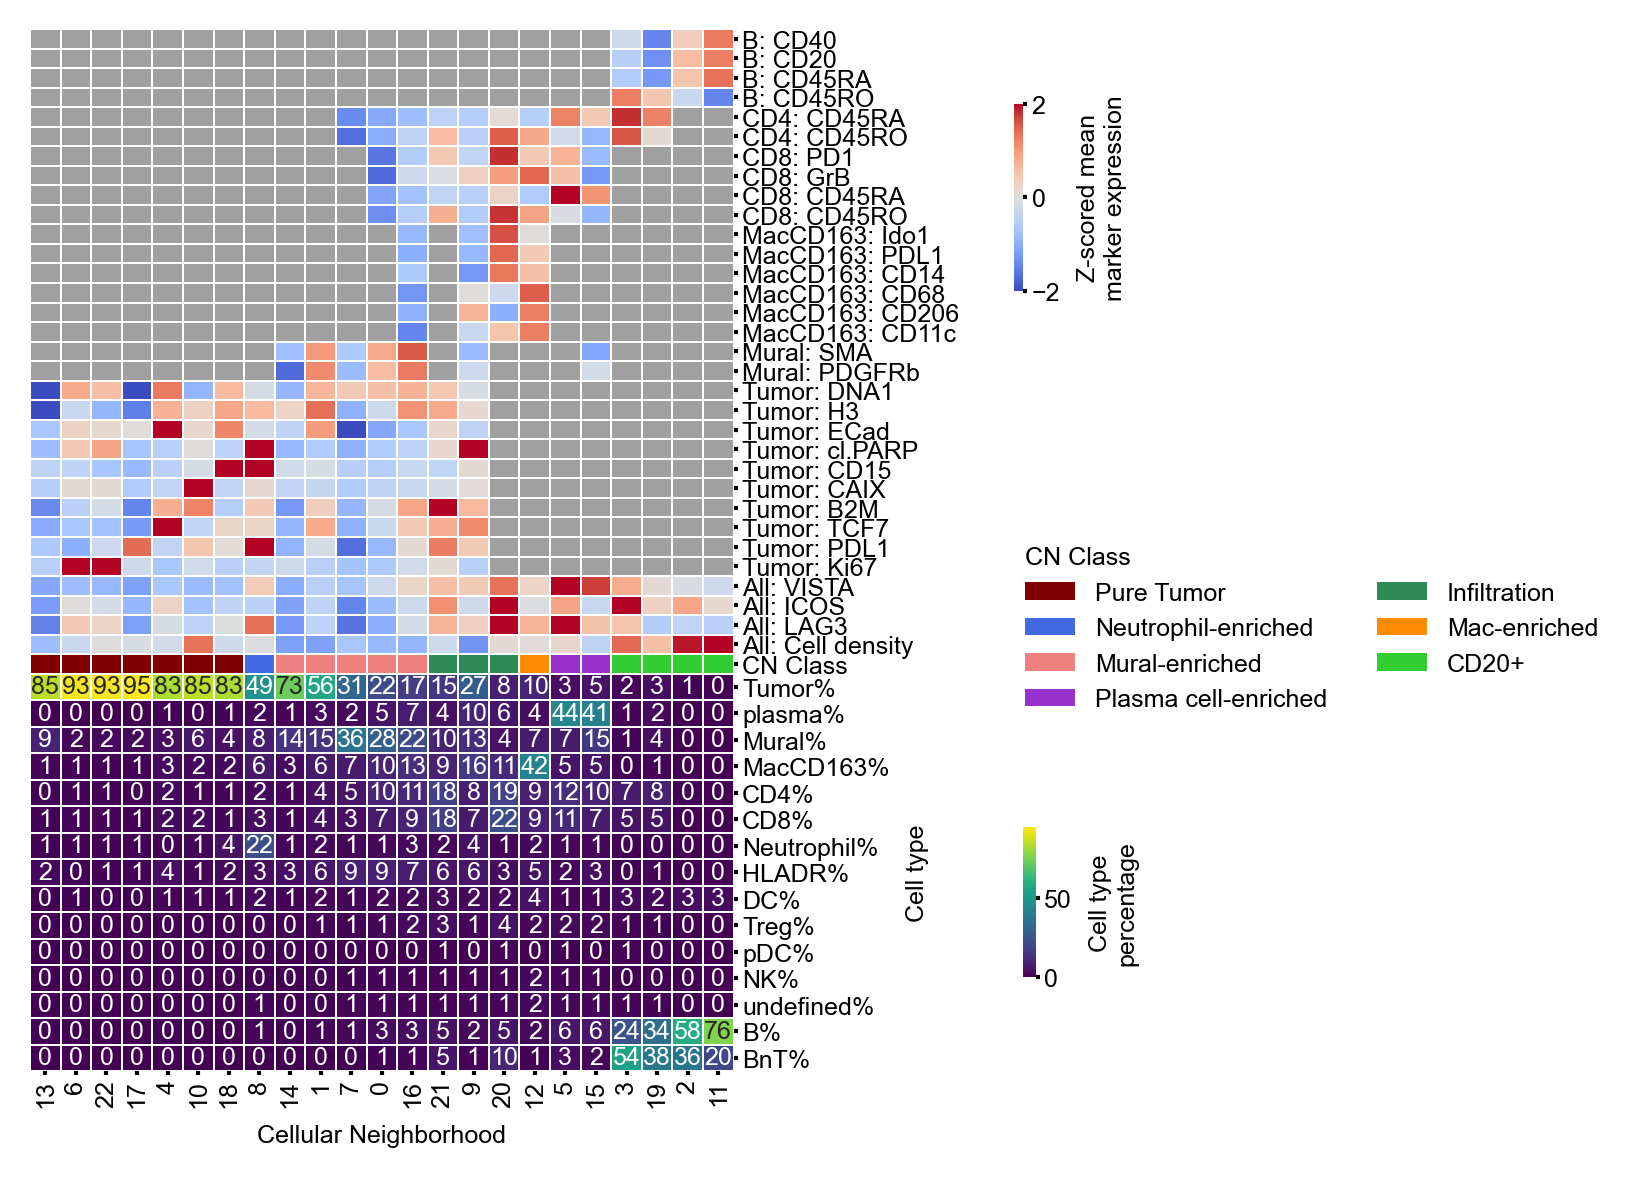

In [38]:
COLORBARS_SHIFT = 0.92

cc_abundance_std_argsort = (-celltype_percentages['Tumor'].values).argsort()

celltype_clustermap = sns.clustermap(
    (celltype_percentages[celltypes].T * 100)[META_CLUSTER_PERM], 
    annot=True,
    col_cluster=False,
    fmt='.0f',
    cmap='viridis',
    figsize=(5, 6),
    col_colors=cc_marker_ct_colors,
    #row_colors=[class_to_color[celltype_to_class[ct]] for ct in numpy.array(celltypes)],
    colors_ratio=0.015,
    yticklabels=True,
    xticklabels=META_CLUSTER_PERM,
    linewidth=0.003,
    annot_kws={"size": 6},
    cbar_pos=[COLORBARS_SHIFT + 0.05, 0.15, 0.01, .1],
    cbar_kws={'label': 'Cell type\npercentage'}
)


#handles = [Patch(facecolor=class_to_color[name]) for name in class_to_color]
#plt.legend(
#    handles, 
#    class_to_color, 
#    title=' Cell type Metatype',
#    bbox_to_anchor=(0.17, 0.53), 
#    bbox_transform=plt.gcf().transFigure,
#    frameon=False,
#    fontsize=6,
#)

celltype_clustermap.ax_col_dendrogram.set_visible(False)

cb_ax = celltype_clustermap.fig.add_axes([COLORBARS_SHIFT, .27, .05, .8])
cb_ax.imshow([[0, 1]])
cb_ax.set_visible(False)

cbar = celltype_clustermap.fig.colorbar(
    marker_sm, 
    drawedges=False,
    #bbox_to_anchor=(1, 0.5),
    label='Z-scored mean\nmarker expression',
    ax=cb_ax,
    #panchor=(1.5, 0.5),
    #anchor=(1.5, 0.5),
)

cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=6, size=1, pad=1)

meta_handles = [matplotlib.patches.Patch(facecolor=tau.META_CLUSTER_TO_COLOR[name]) for name in IMMU_METAS]

meta_legend = plt.legend(
    meta_handles, 
    IMMU_METAS_CLEAN, 
    title='CN Class',
    bbox_to_anchor=(1.45, .4525), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    ncols=2,
    fontsize=6,
    alignment='left',
    markerfirst=True,
)
plt.gcf().add_artist(meta_legend)

celltype_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_clustermap.ax_row_dendrogram.set_visible(False)
celltype_clustermap.ax_col_dendrogram.set_visible(False)

celltype_clustermap.ax_heatmap.set_yticklabels(
    [tick.get_text() + '%' 
     for tick in celltype_clustermap.ax_heatmap.get_yticklabels()
    ], size=6)
celltype_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1)
celltype_clustermap.ax_heatmap.set_xticklabels(celltype_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
celltype_clustermap.ax_col_colors.set_yticklabels(celltype_clustermap.ax_col_colors.get_yticklabels(), size=6)
celltype_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

ax_row_colors = celltype_clustermap.ax_row_colors
ax_col_colors = celltype_clustermap.ax_col_colors
col_box = ax_col_colors.get_position()

box_heatmap = celltype_clustermap.ax_heatmap.get_position()
ax_col_colors.set_position([col_box.x0, box_heatmap.y1, col_box.width, col_box.height])


celltype_clustermap.fig.set_dpi(300)
celltype_clustermap.fig.set_size_inches((4.15, 5))
plt.tight_layout()

In [39]:
ct_clean_names = [
    'B',
    'BnT',
    'CD4',
    'CD8',
    'DC',
    'HLADR',
    'MacCD163',
    'Mural',
    'NK',
    'Neutrophil',
    'T-reg',
    'Tumor',
    'pDC',
    'Plasma cell',
    'Undefined',
]

(0.0, 1.0, 0.0, 1.0)

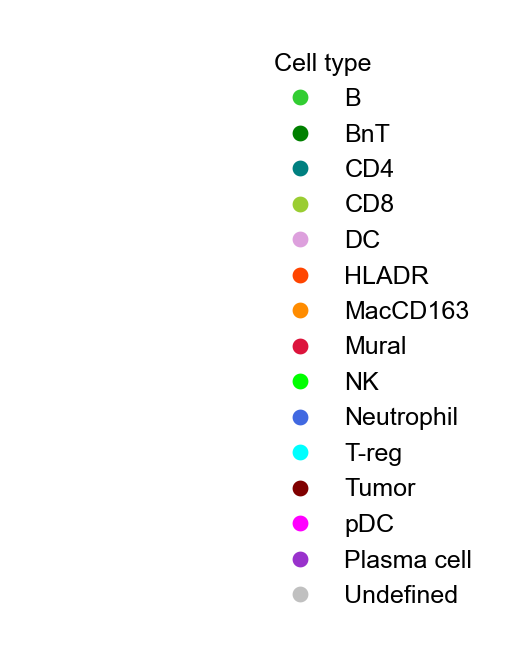

In [40]:
plt.figure(figsize=(2, 2), dpi=300)
ct_handles = [
    matplotlib.lines.Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor=color,
    ) for color in tau.PANEL_1_CELL_TYPE_TO_COLOR.values()]

meta_legend = plt.legend(
    ct_handles, 
    ct_clean_names, 
    title='Cell type',
    frameon=False,
    ncols=1,
    fontsize=6,
    alignment='left',
    markerfirst=True,
)

plt.axis('off')

(0.0, 1.0, 0.0, 1.0)

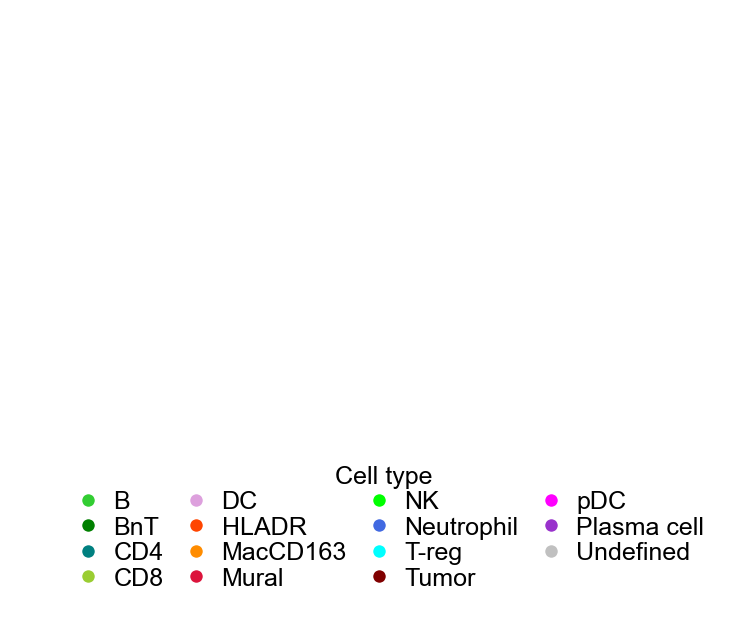

In [41]:
plt.figure(figsize=(2, 2), dpi=300)
ct_handles = [
    matplotlib.lines.Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor=color,
        markersize=4,
    ) for color in tau.PANEL_1_CELL_TYPE_TO_COLOR.values()]

meta_legend = plt.legend(
    ct_handles, 
    ct_clean_names, 
    title='Cell type',
    frameon=False,
    ncols=4,
    fontsize=6,
    #alignment='left',
    bbox_to_anchor=(0.05, -0.1),
    loc='center left',
    labelspacing=0.1,
    columnspacing=0.3,
    handletextpad=0.01,
    borderaxespad=0.,
    markerfirst=True,
)

plt.axis('off')

In [42]:
cell_df.groupby('image').size().shape

(741,)

(0.0, 1.0, 0.0, 1.0)

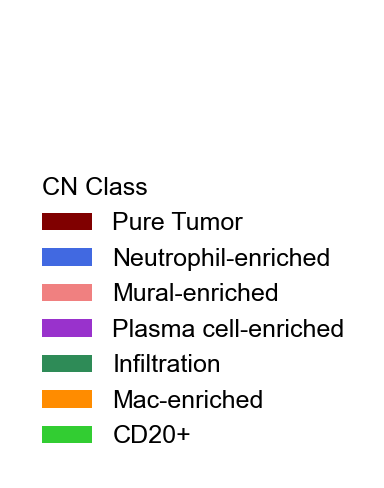

In [43]:
plt.figure(figsize=(1,1), dpi=300)
meta_legend = plt.legend(
    meta_handles, 
    IMMU_METAS_CLEAN, 
    title='CN Class',
    bbox_to_anchor=(1.45, .4525), 
    frameon=False,
    ncols=1,
    fontsize=6,
    alignment='left',
    markerfirst=True,
)
plt.axis('off')

Tumor


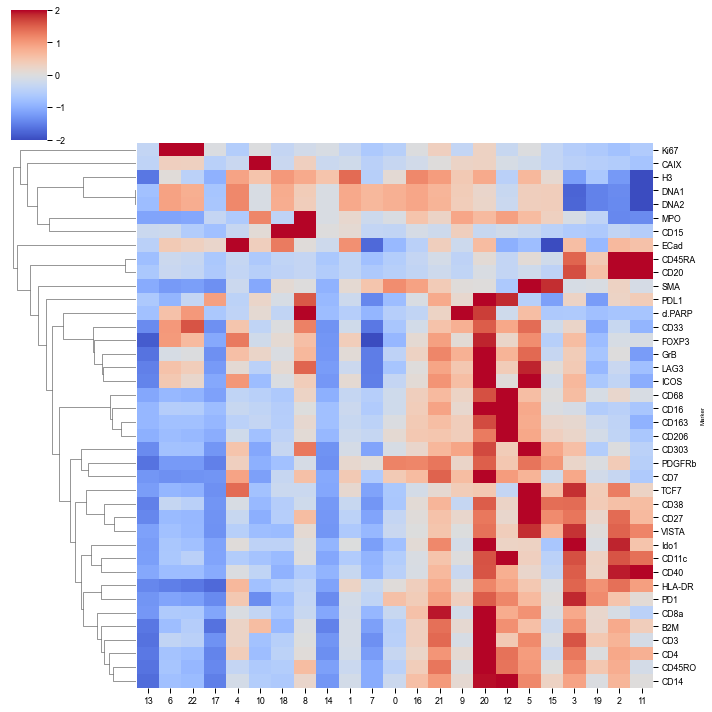

In [44]:
for ct in ['Tumor']:
    print(ct)
    sns.clustermap(
        celltype_to_marker_dfs_clean[ct].loc[MARKERS_CLEAN][META_CLUSTER_PERM], 
        yticklabels=MARKERS_CLEAN,
        z_score=0,
        center=0,
        cmap='coolwarm',
        col_cluster=False,
        vmin=-2,
        vmax=2,
    )
    plt.show()

In [45]:
cc_tls_counts = pandas.pivot_table(
    cell_df[TLS_CELL_SELECTOR], 
    values=DUMMY_COL_NAME, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=['image'],
    aggfunc="sum",
).fillna(0).T 

In [46]:
cc_tls_counts = pandas.melt(cc_tls_counts)

In [47]:
cc_tumor_counts = pandas.pivot_table(
    cell_df[NON_TLS_CELL_SELECTOR], 
    values=DUMMY_COL_NAME, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=['image'],
    aggfunc="sum",
).fillna(0).T 

In [48]:
cc_tumor_counts = pandas.melt(cc_tumor_counts)

In [49]:
cc_tumor_counts

,Cellular Neighborhood,value
0,0,188.0
1,0,226.0
2,0,182.0
3,0,267.0
4,0,377.0
...,...,...
13082,22,768.0
13083,22,431.0
13084,22,1534.0
13085,22,290.0


In [50]:
cc_tls_counts['Source'] = 'TLS'
cc_tumor_counts['Source'] = 'Tumor'

full_cc_counts = pandas.concat([cc_tls_counts, cc_tumor_counts])

In [51]:
import scipy

ttest_ps = []


for cl_ in range(CC_NB_OF_CLUSTERS):
    current_cc_counts = full_cc_counts[full_cc_counts[PREDICTION_CLUSTER_COLUMN] == cl_]
    current_tls_cc_counts = current_cc_counts[current_cc_counts['Source'] == 'TLS']
    current_tumor_cc_counts = current_cc_counts[current_cc_counts['Source'] == 'Tumor']
    current_test = scipy.stats.ttest_ind(
        current_tls_cc_counts['value'],
        current_tumor_cc_counts['value'],
        alternative='greater',
        equal_var=False,
    )
    ttest_ps.append(current_test.pvalue)

In [52]:
gb_avg_val = full_cc_counts.groupby(['Source', PREDICTION_CLUSTER_COLUMN])['value'].median()

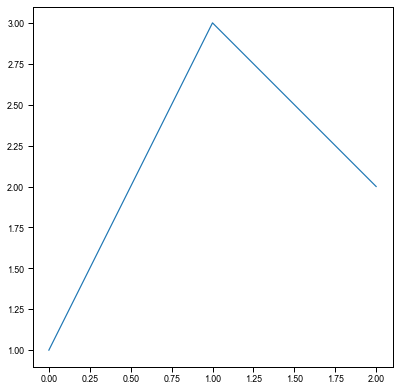

In [53]:
def set_size(w,h, ax=None):
    """ w, h: width, height in inches """
    if not ax: ax=plt.gca()
    l = ax.figure.subplotpars.left
    r = ax.figure.subplotpars.right
    t = ax.figure.subplotpars.top
    b = ax.figure.subplotpars.bottom
    figw = float(w)/(r-l)
    figh = float(h)/(t-b)
    ax.figure.set_size_inches(figw, figh)
          
fig, ax=plt.subplots()

ax.plot([1,3,2])

set_size(5,5)

plt.show()

/tmp/ipykernel_69843/1914999564.py:28: UserWarning: FixedFormatter should only be used together with FixedLocator
  _ = tls_tumor_box.yaxis.set_ticklabels(


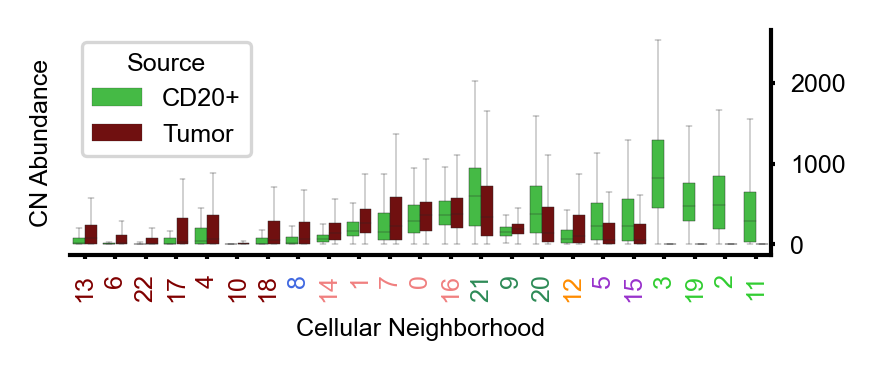

In [54]:
ps_argsort = numpy.argsort(ttest_ps)
ps_argsort = META_CLUSTER_PERM

n_ticks = len(ps_argsort)
width_per_tick = 2.3380539306104526 / 23  # width in inches per tick
total_width = n_ticks * width_per_tick

plt.figure(figsize=(total_width, 0.9), dpi=300)


tls_tumor_box = sns.boxplot(
    data=full_cc_counts, 
    x=PREDICTION_CLUSTER_COLUMN, 
    y='value', 
    hue='Source',
    linewidth=0.1,
    fliersize=0.1,
    order=ps_argsort,
    palette={'TLS': 'limegreen', 'Tumor': 'maroon'},
    #width=0.6,
    showfliers=False,
)
tls_tumor_box.xaxis.set_tick_params(size=1, rotation=90)
tls_tumor_box.yaxis.set_tick_params(size=1, rotation=0)
_ = tls_tumor_box.xaxis.set_ticklabels(
    tls_tumor_box.xaxis.get_ticklabels(), size=6,
)
_ = tls_tumor_box.yaxis.set_ticklabels(
    tls_tumor_box.yaxis.get_ticklabels(), size=6,
)

tls_tumor_box.get_children()[-2].get_texts()[0].set_text('CD20+')


for ind_, tick in enumerate(tls_tumor_box.get_xticklabels()):
    tick.set_color(meta_cluster_colors[numpy.array(META_CLUSTER_PERM).argsort()[ps_argsort[ind_]]])

tls_tumor_box.spines['top'].set_visible(False)
tls_tumor_box.spines['left'].set_visible(False)
tls_tumor_box.set_ylabel('CN Abundance')

tls_tumor_box.yaxis.tick_right()


set_size(2.3380539306104526, 0.75, tls_tumor_box)

/tmp/ipykernel_69843/1234660456.py:30: UserWarning: FixedFormatter should only be used together with FixedLocator
  _ = tls_tumor_box.yaxis.set_ticklabels(


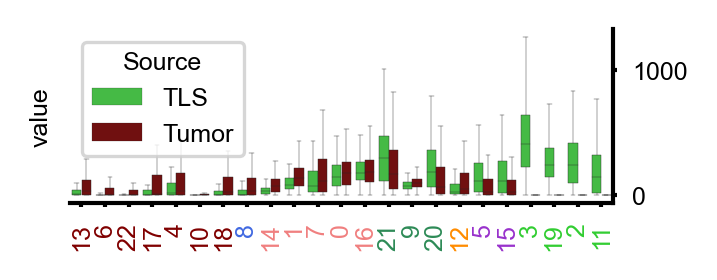

In [55]:
n_ticks = len(ps_argsort)
width_per_tick = 2.3380539306104526 / 23  # width in inches per tick
total_width = n_ticks * width_per_tick

# Create figure with calculated width
fig = plt.figure(dpi=300)
fig.set_size_inches(total_width, 1)  # 1 inch height, width based on ticks

# Your existing code here
tls_tumor_box = sns.boxplot(
    data=full_cc_counts, 
    x=PREDICTION_CLUSTER_COLUMN, 
    y='value', 
    hue='Source',
    linewidth=0.1,
    fliersize=0.1,
    order=ps_argsort,
    palette={'TLS': 'limegreen', 'Tumor': 'maroon'},
    showfliers=False,
)

# Adjust the bottom margin to make sure labels fit
plt.subplots_adjust(bottom=0.3)

tls_tumor_box.xaxis.set_tick_params(size=1, rotation=90)
tls_tumor_box.yaxis.set_tick_params(size=1, rotation=0)
_ = tls_tumor_box.xaxis.set_ticklabels(
    tls_tumor_box.xaxis.get_ticklabels(), size=6,
)
_ = tls_tumor_box.yaxis.set_ticklabels(
    tls_tumor_box.yaxis.get_ticklabels(), size=6,
)
tls_tumor_box.yaxis.tick_right()
tls_tumor_box.set_xlabel('')


for ind_, tick in enumerate(tls_tumor_box.get_xticklabels()):
    tick.set_color(meta_cluster_colors[numpy.array(META_CLUSTER_PERM).argsort()[ps_argsort[ind_]]])

tls_tumor_box.spines['top'].set_visible(False)
tls_tumor_box.spines['left'].set_visible(False)

In [56]:
ct_norm = matplotlib.colors.Normalize(vmin=0, vmax=celltype_percentages.values.max())
ct_cmap = plt.get_cmap('viridis')

ct_sm = matplotlib.cm.ScalarMappable(norm=ct_norm, cmap=ct_cmap)

full_cc_colors_with_ct = cc_marker_ct_colors.copy()

for celltype in celltype_clustermap.data2d.index:
    full_cc_colors_with_ct[f'{celltype}%'] = [
        ct_sm.to_rgba(x) for x in celltype_percentages[celltype]
    ]
    
full_cc_colors_with_ct.to_csv('NSCLC-Panel1-SD.75-23.csv')

## ROI Based Analysis:

Let us start from collection of the roi counts:

In [57]:
roi_counts = pandas.pivot_table(
    cell_df, 
    values=DUMMY_COL_NAME, 
    index=[ROI_COLUMN],
    columns=[PREDICTION_CLUSTER_COLUMN],
    aggfunc="sum",
).fillna(0)

In [58]:
roi_counts

Cellular Neighborhood,0,1,2,3,4,5,6,7,8,9,...,13,14,15,16,17,18,19,20,21,22
image,,,,,,,,,,,,,,,,,,,,,
IMMUcan_Batch20210701_LUNG_10018881-LUNG-VAR-TIS-01-IMC-01_001.tiff,188.0,56.0,0.0,0.0,10.0,30.0,7.0,326.0,0.0,43.0,...,488.0,344.0,52.0,39.0,1458.0,0.0,0.0,0.0,4.0,0.0
IMMUcan_Batch20210701_LUNG_10018881-LUNG-VAR-TIS-01-IMC-01_002.tiff,226.0,37.0,0.0,0.0,12.0,102.0,225.0,133.0,3.0,44.0,...,368.0,128.0,44.0,100.0,1106.0,0.0,0.0,8.0,17.0,212.0
IMMUcan_Batch20210701_LUNG_10018881-LUNG-VAR-TIS-01-IMC-01_003.tiff,182.0,43.0,0.0,0.0,0.0,58.0,109.0,112.0,0.0,46.0,...,265.0,208.0,47.0,187.0,834.0,0.0,0.0,69.0,96.0,74.0
IMMUcan_Batch20210701_LUNG_10018881-LUNG-VAR-TIS-01-IMC-01_004.tiff,208.0,84.0,0.0,429.0,1.0,196.0,56.0,96.0,2.0,91.0,...,31.0,80.0,298.0,267.0,225.0,0.0,220.0,204.0,240.0,46.0
IMMUcan_Batch20210701_LUNG_10018882-LUNG-VAR-TIS-01-IMC-01_001.tiff,267.0,221.0,0.0,0.0,570.0,10.0,0.0,25.0,0.0,140.0,...,5.0,33.0,4.0,335.0,7.0,0.0,0.0,155.0,408.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
IMMUcan_Batch20210921_LUNG_10041591-LUNG-VAR-TIS-01-IMC-01_004.tiff,148.0,74.0,57.0,529.0,9.0,538.0,14.0,29.0,279.0,142.0,...,0.0,16.0,559.0,289.0,0.0,10.0,194.0,163.0,257.0,19.0
IMMUcan_Batch20210921_LUNG_10041592-LUNG-VAR-TIS-01-IMC-01_001.tiff,25.0,4.0,0.0,0.0,4.0,17.0,1312.0,1.0,53.0,172.0,...,4.0,6.0,0.0,51.0,0.0,0.0,0.0,133.0,162.0,1534.0
IMMUcan_Batch20210921_LUNG_10041592-LUNG-VAR-TIS-01-IMC-01_002.tiff,414.0,65.0,0.0,0.0,1.0,118.0,170.0,424.0,2.0,172.0,...,104.0,74.0,283.0,102.0,49.0,0.0,0.0,6.0,12.0,290.0


Now, let's clinical data:

In [59]:
clinical_data_df = pandas.read_csv(CLINICAL_DATA_DF)
clinical_data_df['is_squamous'] = clinical_data_df['simple_histology'].apply(lambda x: 'squamous' in x.lower())

In [60]:
image_to_sample = cell_df.groupby(ROI_COLUMN)[SAMPLE_COLUMN].first()

In [61]:
roi_counts[ROI_COLUMN] = roi_counts.index

In [62]:
roi_counts['immucan_id'] = roi_counts['image'].apply(lambda x: image_to_sample[x])
roi_counts['immucan_id'] = roi_counts['immucan_id'].apply(
    lambda x: '-'.join(x.split('-')[:3])
)

In [63]:
roi_counts = pandas.merge(clinical_data_df, roi_counts, on='immucan_id')

In [64]:
roi_counts['patient'] = roi_counts['immucan_id']

In [65]:
roi_counts['environmental_exposure'] = roi_counts['environmental_exposure'].fillna('None')

## Core correlations analysis:

Let us start with obtaining general Cellohood cluster counts:

In [66]:
cluster_counts = cell_df.groupby(PREDICTION_CLUSTER_COLUMN).size()

Now - let's visualize Clusters correlations and counts:

/tmp/ipykernel_69843/1186187457.py:47: UserWarning: FixedFormatter should only be used together with FixedLocator
  barplot_ax.set_xticklabels(


array([2.4, 2.4])

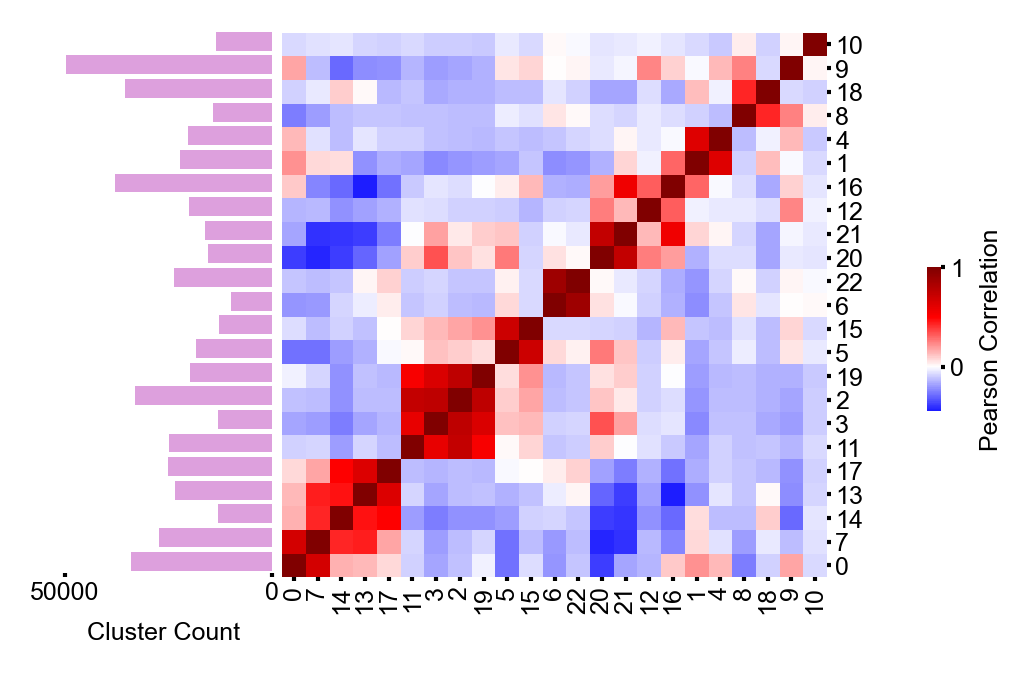

In [67]:
corr_df = roi_counts[list(range(CC_NB_OF_CLUSTERS))].corr()
#corr_df.index.name = 'Cellohood Neighborhood Cluster'
#corr_df.columns.name = 'Cellohood Neighborhood Cluster'

#matplotlib.rcParams.update(matplotlib.rcParamsDefault)

#sns.set_context("paper", rc={"font.size": 6, "axes.titlesize":6,"axes.labelsize":6})  
#plt.rcParams['legend.title_fontsize'] = 6
#plt.rcParams['legend.fontsize'] = 6
#matplotlib.rcParams['font.family'] = 'Arial'


corr_cmap = sns.clustermap(
    corr_df,
    center=0,
    cmap='seismic',
    xticklabels=True,
    yticklabels=True,
    #annot=True,
    #fmt='.2f',
    #annot_kws={'size': 3},
    cbar_pos=[1.1, 0.27, 0.02, 0.2],
    cbar_kws={'label': 'Pearson Correlation'}
)

corr_cmap.ax_row_dendrogram.set_visible(False)
corr_cmap.ax_col_dendrogram.set_visible(False)
#corr_cmap.ax_cbar.set_visible(False)

barplot_ax = corr_cmap.fig.add_axes([-.11, 0.045, .3, .755], sharey=corr_cmap.ax_heatmap)
barplot_ax.barh(
    corr_cmap.data2d.columns + 0.5,
    cluster_counts[corr_cmap.data2d.columns],
    align='center',
    height=0.8,
    color='plum',
)
barplot_ax.invert_yaxis()
barplot_ax.invert_xaxis()
barplot_ax.spines['left'].set_visible(False)
barplot_ax.spines['top'].set_visible(False)
barplot_ax.spines['right'].set_visible(False)
barplot_ax.spines['bottom'].set_visible(False)
barplot_ax.yaxis.set_visible(False)
barplot_ax.set_xlabel('Cluster Count', size=6)
barplot_ax.xaxis.set_tick_params(size=1, left=True, pad=1)
barplot_ax.set_xticklabels(
    barplot_ax.get_xticklabels(), size=6, rotation=0
)

corr_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
corr_cmap.ax_row_dendrogram.set_visible(False)
corr_cmap.ax_col_dendrogram.set_visible(False)

corr_cmap.ax_heatmap.set_yticklabels(
    corr_cmap.ax_heatmap.get_yticklabels(), size=6)
corr_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
corr_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
corr_cmap.ax_heatmap.set_xticklabels(
    corr_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90)

corr_cmap.fig.set_dpi(PLOTTING_DPI)
corr_cmap.fig.set_size_inches((2.4, 2.4))
plt.gcf().get_size_inches()

## SD-1 - TLS - SD.75%

In [68]:
sd1_counts = pandas.read_csv('sd1_roi_counts.csv')
tls_counts = pandas.read_csv('TLS_roi_counts.csv')
sd75_counts = pandas.read_csv('SD75_roi_counts.csv')
p2_roi_counts = pandas.read_csv('panel_2_roi_counts.csv')

In [69]:
p2_patient_level = p2_roi_counts.groupby('immucan_id').first()
p1_patient_level = sd1_counts.groupby('immucan_id').first()

In [70]:
full_clinical = pandas.merge(p1_patient_level, p2_patient_level, how='outer', on='immucan_id')

In [71]:
p1_patient_level.shape, p2_patient_level.shape

((191, 86), (189, 113))

In [72]:
from collections import Counter

Counter(full_clinical['smoking_status_x'])

Counter({'Ex-smoker': 69, 'Non-smoker': 65, 'Current smoker': 57, nan: 1})

In [73]:
FEATURE = 'simple_stage'
VALUE = 3
fun = 'sum'

(
    (full_clinical[f'{FEATURE}_x'] == VALUE).__getattr__(fun)(),
    (p1_patient_level[FEATURE] == VALUE).__getattr__(fun)(),
    (p2_patient_level[FEATURE] == VALUE).__getattr__(fun)(),
)

(55, 55, 56)

In [74]:
FEATURE = tau.SURVIVAL_COLNAME
fun = 'quantile'
param = 0.75

(
    (full_clinical[f'{FEATURE}_x']).__getattr__(fun)(param),
    (p1_patient_level[FEATURE]).__getattr__(fun)(param),
    (p2_patient_level[FEATURE]).__getattr__(fun)(param),
)

(1435.0, 1435.0, 1449.0)

In [75]:
list(full_clinical.columns)

['Unnamed: 0.1_x',
 'Unnamed: 0_x',
 'patient_id_x',
 'age_at_registration_x',
 'disease_x',
 'date_of_diagnosis_x',
 'age_at_diagnosis_x',
 'gender_x',
 'stage_x',
 'side_localization_x',
 'environmental_exposure_x',
 'average_number_of_cigarettes_x',
 'number_of_years_x',
 'smoking_status_x',
 'death_x',
 'time_to_event_x',
 'last_FU_x',
 'driver_mutation_x',
 'neo_adjuvant_treatment_x',
 'type_of_neo_adj_trt_x',
 'curative_surgery_x',
 'adjuvant_treatment_x',
 'type_of_adj_trt_x',
 'metastatic_treatment_x',
 'first_line_x',
 'second_line_x',
 'Column1_x',
 'censoring_x',
 'simple_histology_x',
 'primary_localization_x',
 'simple_stage_x',
 'detailed_histology_x',
 'roman_simple_stage_x',
 'stage_1_x',
 'stage_2_x',
 'stage_2-_x',
 'stage_3_x',
 'stage_3-_x',
 'stage_4_x',
 'binary_stage_x',
 'is_adeno_x',
 'days_to_death_x',
 'Gender_male_x',
 'Smoking_x',
 'Smoking-Ex_x',
 'Smoking-Non_x',
 'blood_sample_id_x',
 'tumor_sample_id_x',
 'tmb_x',
 'msi_percent_x',
 'tmb_class_x',
 'IF_

In [76]:
print(
    '\n'.join(list(tls_counts[[str(x) for x in range(23)]].sum().apply(lambda x: str(int(x)))))
)

28496
17562
51010
85915
13675
31155
3639
22537
8381
14115
2637
38706
15247
8626
8331
29689
34324
11074
7542
50841
48273
58098
3179


In [77]:
g_zero = list((tls_counts[[str(x) for x in range(23)]] > 0).sum())
g_ten = list((tls_counts[[str(x) for x in range(23)]] > 10).sum())
g_hun = list((tls_counts[[str(x) for x in range(23)]] > 100).sum())

In [78]:
print(
    '\n'.join(
        [
            '/'.join([str(el) for el in tup_])
            for tup_ in zip(g_zero, g_ten, g_hun)
        ]
    )
)

171/166/113
171/165/73
156/154/127
171/171/159
134/98/43
163/142/87
75/35/12
164/148/76
120/76/26
172/170/49
27/16/9
142/134/100
152/127/40
139/78/24
167/141/22
166/144/89
170/170/139
91/59/30
96/62/20
171/169/143
168/158/114
170/166/136
65/35/7


In [79]:
p2_roi_cluster_counts = pandas.pivot_table(
    p2_roi_counts, 
    values=DUMMY_COL_NAME, 
    index=['immucan_id'],
    columns=['ROI'],
    aggfunc="sum",
) > 0

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
tls_roi_cluster_counts = pandas.pivot_table(
    tls_counts, 
    values=DUMMY_COL_NAME, 
    index=['immucan_id'],
    columns=['ROI'],
    aggfunc="sum",
) > 0
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
sd75_roi_cluster_counts = pandas.pivot_table(
    sd75_counts, 
    values=DUMMY_COL_NAME, 
    index=['immucan_id'],
    columns=['ROI'],
    aggfunc="sum",
) > 0
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
p1_p2 = pandas.merge(
    p2_roi_cluster_counts, 
    sd75_roi_cluster_counts, 
    on='immucan_id', 
    suffixes=('_p2', '_p1'),
)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
tls_p2 = pandas.merge(
    p2_roi_cluster_counts, 
    tls_roi_cluster_counts, 
    on='immucan_id', 
    suffixes=('_p2', '_tls'),
)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
corr_p1_p2 = p1_p2.corr()
sns.clustermap(
    p1_p2.corr().iloc[
        numpy.array([ind for ind, el in enumerate(corr_p1_p2.index) if el.endswith('p1')]),
        numpy.array([ind for ind, el in enumerate(corr_p1_p2.index) if el.endswith('p2')])
    ],
    annot=True,
    center=0, cmap='seismic')
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
tls_p2 = tls_p2.corr()
sns.clustermap(
    tls_p2.corr().iloc[
        numpy.array([ind for ind, el in enumerate(tls_p2.index) if str(el).endswith('tls')]),
        numpy.array([ind for ind, el in enumerate(tls_p2.index) if not str(el).endswith('tls')])
    ],
    annot=True,
    center=0, cmap='seismic')
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
corr_p1_p2.iloc[
        numpy.array([ind for ind, el in enumerate(corr_p1_p2.index) if el.endswith('p1')])
    ]
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
imm_id_to_tls_row = {
    row_['immucan_id']: row_['ROI']
    for _, row_ in tls_counts.iterrows()
}
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
sd1_counts['ROI'] = sd1_counts[ROI_CLUSTER_NAME]
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
NB_OF_SD1_CLUSTERS = max(sd1_counts['ROI']) + 1
NB_OF_TLS_CLUSTERS = max(tls_counts['ROI']) + 1
NB_OF_SD75_CLUSTERS = max(sd75_counts['ROI']) + 1
NB_OF_P2_CLUSTERS = max(p2_roi_counts['ROI']) + 1
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
p1_p2_cross_count = numpy.zeros((NB_OF_SD75_CLUSTERS, NB_OF_P2_CLUSTERS))


for i in range(NB_OF_SD75_CLUSTERS):
    for j in range(NB_OF_P2_CLUSTERS):
        current_count = (p1_p2[f'{i}_p1'] * p1_p2[f'{j}_p2']).sum()
        p1_p2_cross_count[i, j] = current_count
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
sns.clustermap(p1_p2_cross_count)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
from scipy.stats import hypergeom

p1_p2_pvals = numpy.ones((NB_OF_SD75_CLUSTERS, NB_OF_P2_CLUSTERS))

p1_p2_all_ = p1_p2_cross_count.sum()


for i in range(p1_p2_cross_count.shape[1]):
    p2_cluster_all = p1_p2_cross_count[:, i].sum()
    for j in range(p1_p2_cross_count.shape[0]):
        p1_cluster_all = p1_p2_cross_count[j, :].sum()
        current_cdf = hypergeom.cdf(k=p1_p2_cross_count[j, i], M=p1_p2_all_, n=p2_cluster_all, N=p1_cluster_all)
        current_pval = current_cdf # 1 -  2 * numpy.abs(current_cdf - 0.5)
        p1_p2_pvals[j, i] = current_pval
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
p1_p2_pvals_df = pandas.DataFrame(p1_p2_pvals)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
p1_p2_qvals_df = tau.apply_fdr_to_df(p1_p2_pvals_df.applymap(lambda x: 1 - 2 * numpy.abs(x - 0.5)))
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
FDR_ALPHA = 0.2

valid_p1_clusters = p1_p2_qvals_df.min(axis=1) < FDR_ALPHA
valid_p2_clusters = p1_p2_qvals_df.min(axis=0) < FDR_ALPHA
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
def get_stars_from_q_value(q_val):
    result = ''
    if q_val < 0.2:
        result += '*'
    if q_val < 0.05:
        result += '*'
    if q_val < 0.01:
        result += '*'
    return result
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
p1_p2_annots = numpy.empty(p1_p2_qvals_df.shape, dtype=object)


for i in range(p1_p2_annots.shape[0]):
    for j in range(p1_p2_annots.shape[1]):
        current_stars = str(get_stars_from_q_value(p1_p2_qvals_df.values[i, j]))
        if len(current_stars):
            current_annot = f'{current_stars}'
        p1_p2_annots[i, j] = current_stars
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
p1_p2_enrichement = sns.clustermap(
    p1_p2_cross_count[valid_p1_clusters], 
    #vmin=0, 
    #vmax=1, 
    cmap='cividis', 
    annot=p1_p2_annots[valid_p1_clusters],
    fmt='',
)
p1_p2_enrichement.fig.set_dpi(300)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python

```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
p1_p2_annots = numpy.empty(p1_p2_pvals.shape, dtype=object)


for i in range(p1_p2_annots.shape[0]):
    for j in range(p1_p2_annots.shape[1]):
        current_stars = str(get_stars_from_q_value(p1_p2_qvals_df.values[i, j]))
        if len(current_stars):
            current_annot = f'{current_stars}'
        p1_p2_annots[i, j] = current_stars
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
p1_p2_cmap = sns.clustermap(
    p1_p2_pvals_df.T, 
    annot=p1_p2_annots.T, 
    fmt='', 
    cmap='bwr',
    figsize=(4, 4),
)

p1_p2_cmap.ax_col_dendrogram.set_visible(False)
p1_p2_cmap.ax_row_dendrogram.set_visible(False)

p1_p2_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
p1_p2_cmap.ax_row_dendrogram.set_visible(False)
p1_p2_cmap.ax_col_dendrogram.set_visible(False)

p1_p2_cmap.ax_heatmap.set_yticklabels(
    p1_p2_cmap.ax_heatmap.get_yticklabels(), size=6)
p1_p2_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
p1_p2_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
p1_p2_cmap.ax_heatmap.set_xticklabels(
    p1_p2_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90)

p1_p2_cmap.fig.set_dpi(PLOTTING_DPI)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
sd_75_to_tls = numpy.zeros((NB_OF_SD75_CLUSTERS, NB_OF_TLS_CLUSTERS))

for _, row_ in sd75_counts.iterrows():
    if row_['immucan_id'] not in imm_id_to_tls_row:
        continue
    sd_75_to_tls[row_['ROI'], imm_id_to_tls_row[row_['immucan_id']]] += 1
    

sd_75_to_tls_df = pandas.DataFrame(
    sd_75_to_tls,
    columns=[f'TLS ROI: {i}' for i in range(NB_OF_TLS_CLUSTERS)]
)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
NB_OF_SD75_CLUSTERS, NB_OF_TLS_CLUSTERS
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
p2_to_tls = numpy.zeros((NB_OF_P2_CLUSTERS, NB_OF_TLS_CLUSTERS))

for _, row_ in p2_roi_counts.iterrows():
    if row_['immucan_id'] not in imm_id_to_tls_row:
        continue
    p2_to_tls[row_['ROI'], imm_id_to_tls_row[row_['immucan_id']]] += 1
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
sd_75_to_tls_df = pandas.DataFrame(
    sd_75_to_tls,
    columns=[f'TLS ROI: {i}' for i in range(NB_OF_TLS_CLUSTERS)]
)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
p2_to_tls_df = pandas.DataFrame(
    p2_to_tls,
    columns=[f'TLS ROI: {i}' for i in range(NB_OF_TLS_CLUSTERS)],
)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
from scipy.stats import hypergeom

tls_pvals = numpy.ones((NB_OF_SD75_CLUSTERS, NB_OF_TLS_CLUSTERS))

all_ = sd_75_to_tls.sum()


for i in range(sd_75_to_tls.shape[1]):
    tls_cluster_all = sd_75_to_tls[:, i].sum()
    for j in range(sd_75_to_tls.shape[0]):
        sd_75_cluster_all = sd_75_to_tls[j, :].sum()
        current_cdf = hypergeom.cdf(k=sd_75_to_tls[j, i], M=all_, n=tls_cluster_all, N=sd_75_cluster_all)
        current_pval = current_cdf # 1 -  2 * numpy.abs(current_cdf - 0.5)
        tls_pvals[j, i] = current_pval
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
tls_pvals_s = tls_pvals.copy()
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
p2_tls_pvals = numpy.ones((NB_OF_P2_CLUSTERS, NB_OF_TLS_CLUSTERS))

all_ = p2_to_tls.sum()


for i in range(p2_to_tls.shape[1]):
    tls_cluster_all = p2_to_tls[:, i].sum()
    for j in range(p2_to_tls.shape[0]):
        p2_cluster_all = p2_to_tls[j, :].sum()
        current_cdf = hypergeom.cdf(k=p2_to_tls[j, i], M=all_, n=tls_cluster_all, N=p2_cluster_all)
        current_pval = current_cdf # 1 -  2 * numpy.abs(current_cdf - 0.5)
        p2_tls_pvals[j, i] = current_pval
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
tls_pvals_df = pandas.DataFrame(tls_pvals)
p2_tls_pvals_df = pandas.DataFrame(p2_tls_pvals)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
tls_qvals = tau.apply_fdr_to_df(tls_pvals_df.apply(lambda x: 1 - 2 * abs(x - 0.5)))
p2_tls_qvals = tau.apply_fdr_to_df(p2_tls_pvals_df.apply(lambda x: 1 - 2 * abs(x - 0.5)))

#tls_qvals = tau.apply_fdr_to_df(tls_pvals_df)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python

```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
tls_annots = numpy.empty(sd_75_to_tls.shape, dtype=object)


for i in range(tls_annots.shape[0]):
    for j in range(tls_annots.shape[1]):
        current_stars = str(get_stars_from_q_value(tls_qvals.values[i, j]))
        current_annot = str(int(sd_75_to_tls[i, j]))
        if len(current_stars):
            current_annot = f'{current_stars}'
        tls_annots[i, j] = current_stars
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
p2_tls_annots = numpy.empty(p2_to_tls.shape, dtype=object)


for i in range(p2_tls_annots.shape[0]):
    for j in range(p2_tls_annots.shape[1]):
        current_stars = str(get_stars_from_q_value(p2_tls_qvals.values[i, j]))
        current_annot = str(int(p2_to_tls[i, j]))
        if len(current_stars):
            current_annot = f'{current_stars}'
        p2_tls_annots[i, j] = current_stars
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
sd75_to_tls = sns.clustermap(
    tls_pvals_df.T, 
    annot=tls_annots.T, 
    fmt='', 
    cmap='bwr',
    figsize=(4, 2),
)

sd75_to_tls.ax_col_dendrogram.set_visible(False)
sd75_to_tls.ax_row_dendrogram.set_visible(False)

sd75_to_tls.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
sd75_to_tls.ax_row_dendrogram.set_visible(False)
sd75_to_tls.ax_col_dendrogram.set_visible(False)

sd75_to_tls.ax_heatmap.set_yticklabels(
    sd75_to_tls.ax_heatmap.get_yticklabels(), size=6)
sd75_to_tls.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
sd75_to_tls.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
sd75_to_tls.ax_heatmap.set_xticklabels(
    sd75_to_tls.ax_heatmap.get_xticklabels(), size=6, rotation=90)

sd75_to_tls.fig.set_dpi(PLOTTING_DPI)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
p2_to_tls = sns.clustermap(
    p2_tls_pvals_df.T, 
    annot=p2_tls_annots.T, 
    fmt='', 
    cmap='bwr',
    center=0.5,
    figsize=(4, 2),
)

p2_to_tls.ax_col_dendrogram.set_visible(False)
p2_to_tls.ax_row_dendrogram.set_visible(False)

p2_to_tls.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
p2_to_tls.ax_row_dendrogram.set_visible(False)
p2_to_tls.ax_col_dendrogram.set_visible(False)

p2_to_tls.ax_heatmap.set_yticklabels(
    p2_to_tls.ax_heatmap.get_yticklabels(), size=6)
p2_to_tls.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
p2_to_tls.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
p2_to_tls.ax_heatmap.set_xticklabels(
    p2_to_tls.ax_heatmap.get_xticklabels(), size=6, rotation=90)

p2_to_tls.fig.set_dpi(PLOTTING_DPI)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
p2_to_tls_cm = sns.clustermap(
    p2_to_tls_df.T, 
    annot=p2_tls_annots.T, 
    fmt='', 
    cmap='cividis',
    figsize=(4, 2),
)

p2_to_tls_cm.ax_col_dendrogram.set_visible(False)
p2_to_tls_cm.ax_row_dendrogram.set_visible(False)
p2_to_tls_cm.fig.set_dpi(PLOTTING_DPI)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
sd_1_to_sd_75 = numpy.zeros((NB_OF_SD75_CLUSTERS, NB_OF_SD1_CLUSTERS))


for sd_1_, sd_75_ in zip(sd1_counts['ROI'], sd75_counts['ROI']):
    sd_1_to_sd_75[sd_75_,sd_1_] += 1
    
    
sd_1_to_sd_75_df = pandas.DataFrame(sd_1_to_sd_75, columns=[f'SD.1 ROI: {i}' for i in range(NB_OF_SD1_CLUSTERS)])
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
sd1_pvals = numpy.ones(sd_1_to_sd_75.shape)
sd_1_pvals_s = numpy.ones(sd_1_to_sd_75.shape)

all_ = sd_1_to_sd_75.sum()


for i in range(sd_1_to_sd_75.shape[1]):
    sd1_cluster_all = sd_1_to_sd_75[:, i].sum()
    for j in range(sd_1_to_sd_75.shape[0]):
        sd_75_cluster_all = sd_1_to_sd_75[j, :].sum()
        current_cdf = hypergeom.cdf(k=sd_1_to_sd_75[j, i], M=all_, n=sd1_cluster_all, N=sd_75_cluster_all)
        sd_1_pvals_s[j, i] = current_cdf
        current_pval = 1 -  2 * numpy.abs(current_cdf - 0.5)
        sd1_pvals[j, i] = current_pval
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
sd1_pvals_df = pandas.DataFrame(sd1_pvals)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
sd1_qvals = tau.apply_fdr_to_df(sd1_pvals_df)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
sd1_annots = numpy.empty(sd_1_to_sd_75.shape, dtype=object)


for i in range(sd1_annots.shape[0]):
    for j in range(sd1_annots.shape[1]):
        current_stars = str(get_stars_from_q_value(sd1_qvals.values[i, j]))
        current_annot = str(int(sd_1_to_sd_75[i, j]))
        if len(current_stars):
            current_annot = f'{current_stars}'
            if sd_1_pvals_s[i, j] > 0.5:
                current_stars += '\n+'
            else:
                current_stars += '\n-'
        sd1_annots[i, j] = current_stars
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
sd1_to_tls_cm = sns.clustermap(
    sd_1_to_sd_75_df.T, 
    annot=sd1_annots.T, 
    fmt='', 
    cmap='cividis',
    figsize=(4, 2),
)

sd1_to_tls_cm.ax_col_dendrogram.set_visible(False)
sd1_to_tls_cm.ax_row_dendrogram.set_visible(False)
sd1_to_tls_cm.fig.set_dpi(PLOTTING_DPI)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
pvals_df = pandas.DataFrame(numpy.concatenate([sd1_pvals.T, tls_pvals.T]))
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
pvals_s_df = pandas.DataFrame(numpy.concatenate([sd_1_pvals_s.T, tls_pvals_s.T]))
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
qvals_df = tau.apply_fdr_to_df(pvals_df)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
all_annots = numpy.empty(qvals_df.shape, dtype=object)

for i in range(all_annots.shape[0]):
    for j in range(all_annots.shape[1]):
        current_stars = str(get_stars_from_q_value(qvals_df.values[i, j]))
        if len(current_stars):
            if pvals_s_df.values[i, j] < 0.5:
                current_stars += '\n-'
            else:
                current_stars += '\n+'
        all_annots[i, j] = current_stars
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
full_sd1_df = pandas.concat([sd_1_to_sd_75_df.T, sd_75_to_tls_df.T])
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
all_annots_df = pandas.DataFrame(all_annots, index=full_sd1_df.index, columns=full_sd1_df.columns)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python

```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
full_sd1_df.index = [
    col.replace('SD', 'PLDA')
    for col in full_sd1_df.index
]
full_sd1_df.index = [
    col.replace('TLS', 'CD20+')
    for col in full_sd1_df.index
]
full_sd1_df.index = [
    col.replace('ROI', 'SG')
    for col in full_sd1_df.index
]


all_annots_df.index = [
    col.replace('SD', 'PLDA')
    for col in all_annots_df.index
]
all_annots_df.index = [
    col.replace('TLS', 'CD20+')
    for col in all_annots_df.index
]
all_annots_df.index = [
    col.replace('ROI', 'SG')
    for col in all_annots_df.index
]
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
full_sd1_df.columns.name = 'PLDA.75 Tumor Slide Group'
full_sd1_df.index.name = 'CD20+ & PLDA.1 Tumor\nSlide Group'
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
COL_ORDER = ['PLDA.1 SG: 0', 'PLDA.1 SG: 2', 'PLDA.1 SG: 1', 'CD20+ SG: 1', 'CD20+ SG: 3',
       'CD20+ SG: 0', 'CD20+ SG: 2']
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
sd75_to_sd1_tls_cm = sns.clustermap(
    full_sd1_df.loc[COL_ORDER], 
    annot=all_annots_df.loc[COL_ORDER], 
    row_cluster=False,
    fmt='', 
    cmap='cividis',
    figsize=(4, 1.8),
    cbar_pos=(.92, 0.47, 0.008, 0.15),
    yticklabels=True,
    #linewidth=0.001,
    annot_kws={'va': 'center', 'size': 6, 'linespacing': 0.1},
    cbar_kws={'label': 'Slide Count'}
)

sd75_to_sd1_tls_cm.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
sd75_to_sd1_tls_cm.ax_row_dendrogram.set_visible(False)
sd75_to_sd1_tls_cm.ax_col_dendrogram.set_visible(False)

sd75_to_sd1_tls_cm.ax_heatmap.set_yticklabels(
    sd75_to_sd1_tls_cm.ax_heatmap.get_yticklabels(), size=6)
sd75_to_sd1_tls_cm.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
sd75_to_sd1_tls_cm.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
sd75_to_sd1_tls_cm.ax_heatmap.set_xticklabels(
    sd75_to_sd1_tls_cm.ax_heatmap.get_xticklabels(), size=6, rotation=0)
#sd75_to_sd1_tls_cm.ax_heatmap.set_xlabel('SD.75 ROI Cluster', labelpad=0.1)

sd75_to_sd1_tls_cm.ax_col_dendrogram.set_visible(False)
sd75_to_sd1_tls_cm.ax_row_dendrogram.set_visible(False)
sd75_to_sd1_tls_cm.fig.set_dpi(PLOTTING_DPI)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
all_p2_pvals = pandas.DataFrame(numpy.concatenate([p1_p2_pvals, p2_tls_pvals.T]))
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
all_p2_qvals_df = tau.apply_fdr_to_df(all_p2_pvals.applymap(lambda x: 1 -  2 * numpy.abs(x - 0.5)))
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
all_p2_annots = numpy.empty(all_p2_qvals_df.shape, dtype=object)

for i in range(all_p2_annots.shape[0]):
    for j in range(all_p2_annots.shape[1]):
        current_stars = str(get_stars_from_q_value(all_p2_qvals_df.values[i, j]))
        if len(current_stars) > 0:
            if all_p2_pvals.iloc[i, j] > 0.5:
                current_stars += '\n+'
            else:
                current_stars += '\n-'
        all_p2_annots[i, j] = current_stars
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
p1_p2_cross_count_df = pandas.DataFrame(p1_p2_cross_count)
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
full_p2_df = pandas.concat([p1_p2_cross_count_df, p2_to_tls_df.T])
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
full_p2_df.index = [
    f'Tumor PLDA.75 SG: {cl}' if not str(cl).startswith('TLS') else cl
    for cl in full_p2_df.index
]

full_p2_df.index = [
    f'CD20+ PLDA.75 SG: {cl[-1]}' if str(cl).startswith('TLS') else cl
    for cl in full_p2_df.index
]
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
full_p2_df.index.name = 'Panel 1 Slide Groups'
full_p2_df.columns.name = 'Panel 2 Slide Groups'
```

**[Excluded from execution]** This cell was part of a cross-comparison block (SD1 vs SD75 vs Panel-2 vs TLS clustering) whose root cause is a KeyError: 'ROI' in the first cell of the block (tls_counts is missing a 'ROI' column on a fresh run), which cascades into 55 downstream NameErrors for the rest of this block. It is a cross-notebook comparison, not used by any clinical or per-notebook statistical analysis, so it was excluded rather than debugged cell by cell. Original source preserved below for reference.

```python
p2_all_cm = sns.clustermap(
    full_p2_df, 
    annot=all_p2_annots, 
    row_cluster=False,
    fmt='', 
    cmap='cividis',
    figsize=(4, 3),
    cbar_pos=(.87, 0.41, 0.008, 0.15),
    yticklabels=True,
    #linewidth=0.001,
    annot_kws={'va': 'center', 'size': 6, 'linespacing': 0.1},
    cbar_kws={'label': 'Slide Count'}
)

p2_all_cm.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
p2_all_cm.ax_row_dendrogram.set_visible(False)
p2_all_cm.ax_col_dendrogram.set_visible(False)

p2_all_cm.ax_heatmap.set_yticklabels(
    p2_all_cm.ax_heatmap.get_yticklabels(), size=6)
p2_all_cm.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
p2_all_cm.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
p2_all_cm.ax_heatmap.set_xticklabels(
    p2_all_cm.ax_heatmap.get_xticklabels(), size=6, rotation=0)
#sd75_to_sd1_tls_cm.ax_heatmap.set_xlabel('SD.75 ROI Cluster', labelpad=0.1)

p2_all_cm.ax_col_dendrogram.set_visible(False)
p2_all_cm.ax_row_dendrogram.set_visible(False)
p2_all_cm.fig.set_dpi(PLOTTING_DPI)
```

# Joint Table

In [80]:
tls_clustering_df = pandas.read_csv('tls_plda_75_clustering_df.csv')
tumor_clustering_df = pandas.read_csv('tumor_plda_75_clustering_df.csv')

In [81]:
tls_clustering_df.set_index('Unnamed: 0', inplace=True)
tumor_clustering_df.set_index('Unnamed: 0', inplace=True)

In [82]:
tls_clustering_df.index = [
    'CD20+ ' + ind_
    for ind_ in tls_clustering_df.index
]

tumor_clustering_df.index = [
    'Tumor ' + ind_
    for ind_ in tumor_clustering_df.index
]

In [83]:
full_clustering_df = pandas.concat([tumor_clustering_df, tls_clustering_df])

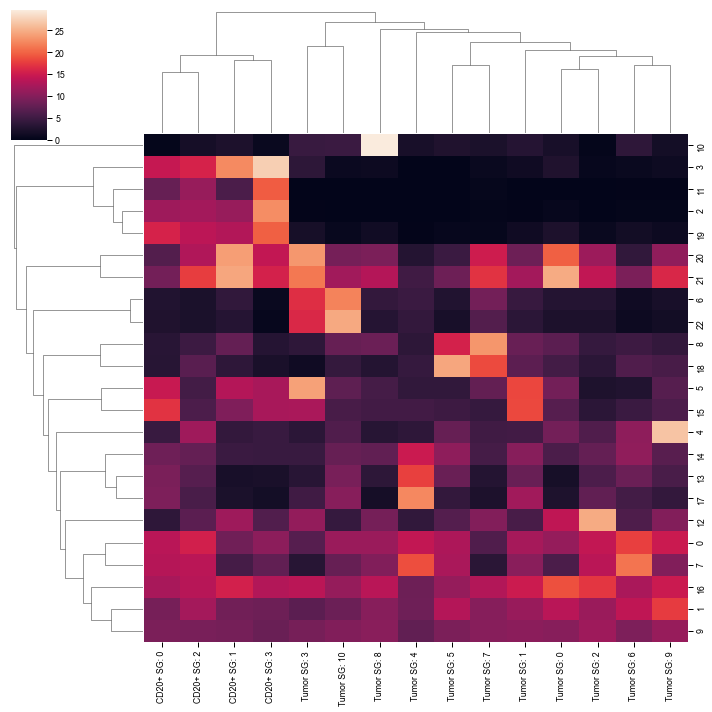

In [84]:
sns.clustermap(full_clustering_df.T)

In [85]:
tls_clinical_q = pandas.read_csv('plda_75_tls_q.csv')
tumor_clinical_q = pandas.read_csv('plda_75_tumor_q.csv')

In [86]:
tls_clinical_q.set_index('Unnamed: 0', inplace=True)
tumor_clinical_q.set_index('Unnamed: 0', inplace=True)

In [87]:
tumor_clinical_q.index = [
    ind_.replace('Histology', 'Hist')
    for ind_ in tumor_clinical_q.index
]

In [88]:
tumor_clinical_q.index.name = 'Unnamed: 0'

In [89]:
tls_clinical_q.columns = [
    'CD20+ ' + ind_
    for ind_ in tls_clinical_q.columns
]

tumor_clinical_q.columns = [
    'Tumor ' + ind_
    for ind_ in tumor_clinical_q.columns
]

In [90]:
tls_clinical_q.index = [
    ind.replace('TNB Stage', 'TNM').replace('0.16', '16').replace('0.1', '10')
    for ind in tls_clinical_q.index
]

tls_clinical_q.index.name = 'Clinical Index'

tumor_clinical_q.index = [
    ind.replace('TMB Stage', 'TNM').replace('0.16', '16').replace('0.1', '10')
    for ind in tumor_clinical_q.index
]

tumor_clinical_q.index.name = 'Clinical Index'

In [91]:
tls_clinical_q

,CD20+ SG: 1,CD20+ SG: 3,CD20+ SG: 0,CD20+ SG: 2
Clinical Index,,,,
TPS: Negative,0.999485,0.999485,0.006315,0.279577
CPS: Negative,0.999485,0.999485,0.034560,0.114016
TNM: IV,0.306852,0.999485,0.900821,0.145695
"TNM: III, IV",0.999485,0.720565,0.999485,0.145695
Female,0.999485,0.579703,0.999485,0.114016
Hist: Adenocarcinoma,0.999485,0.999485,0.999485,0.002330
Non-smoker,0.999485,0.999485,0.716670,0.145695
TMB: <10,0.921942,0.999485,0.745024,0.180393
Hist: Adeno-sq.,0.114016,0.900821,0.661483,0.999485


In [92]:
tumor_clinical_q

,Tumor SG: 1,Tumor SG: 8,Tumor SG: 3,Tumor SG: 10,Tumor SG: 2,Tumor SG: 0,Tumor SG: 7,Tumor SG: 6,Tumor SG: 9,Tumor SG: 4,Tumor SG: 5
Clinical Index,,,,,,,,,,,
Ex-smoker,0.332795,0.999997,0.131019,0.905428,0.959977,0.149099,0.368724,0.999997,0.695102,0.999997,0.999997
TPS: Positive,0.929334,0.799485,0.003761,0.439549,0.499983,0.131019,0.295672,0.999997,0.999997,0.999997,0.999997
CPS: Positive,0.131019,0.789039,0.020517,0.158025,0.638495,0.001485,0.112810,0.999997,0.999997,0.999997,0.999997
Hist: Other,0.999997,0.167277,0.017760,0.022583,0.706097,0.999997,0.999997,0.999997,0.999997,0.611485,0.999997
Male,0.194195,0.301992,0.590780,0.445419,0.999997,0.999997,0.999997,0.999997,0.492663,0.695102,0.544256
TNM: II,0.129855,0.131019,0.329886,0.590780,0.999997,0.773620,0.590780,0.999997,0.999997,0.782645,0.999997
Hist: Squamous cell carcinoma,0.131019,0.253039,0.062742,0.131019,0.999997,0.999997,0.388807,0.999997,0.999997,0.435146,0.999997
"TMB: [10, 16)",0.324815,0.324815,0.131019,0.124087,0.999997,0.999997,0.965528,0.999997,0.999997,0.602237,0.700386
TPS: Negative,0.647035,0.799485,0.999997,0.965528,0.999997,0.999997,0.999997,0.067906,0.003761,0.182945,0.347898


In [93]:
full_clinical_q = pandas.merge(tls_clinical_q, tumor_clinical_q, on='Clinical Index', how='outer').fillna(1.)

In [94]:
clinical_norm = matplotlib.colors.Normalize(vmin=0, vmax=1)
clinical_cmap = plt.get_cmap('Blues_r')

clinical_sm = matplotlib.cm.ScalarMappable(norm=clinical_norm, cmap=clinical_cmap)

full_clinical_colors = full_clinical_q.applymap(lambda x: clinical_sm.to_rgba(x))

In [95]:
full_cc_colors_with_ct = cc_marker_ct_colors.copy()

for celltype in celltype_clustermap.data2d.index:
    full_cc_colors_with_ct[f'{celltype}%'] = [
        ct_sm.to_rgba(x ** 0.5) for x in celltype_percentages[celltype]
    ]

In [96]:
full_cc_colors_with_ct

,B: CD40,B: CD20,B: CD45RA,B: CD45RO,CD4: CD45RA,CD4: CD45RO,CD8: PD1,CD8: GrB,CD8: CD45RA,CD8: CD45RO,...,CD8%,Neutrophil%,HLADR%,DC%,Treg%,pDC%,NK%,undefined%,B%,BnT%
0,"(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","[0.5271322591215686, 0.664699602117647, 0.9890...","[0.5380042157019607, 0.6749015936470587, 0.991...","[0.34327752343529416, 0.45935363472941176, 0.8...","[0.30906031906666664, 0.41349827226666663, 0.8...","[0.5054226428235293, 0.6439946735686275, 0.983...","[0.42519897019607844, 0.559058179764706, 0.946...",...,"(0.220057, 0.343307, 0.549413, 1.0)","(0.278012, 0.180367, 0.486697, 1.0)","(0.19943, 0.387607, 0.554642, 1.0)","(0.277134, 0.185228, 0.489898, 1.0)","(0.280868, 0.160771, 0.472899, 1.0)","(0.280894, 0.078907, 0.402329, 1.0)","(0.28229, 0.145912, 0.46151, 1.0)","(0.28229, 0.145912, 0.46151, 1.0)","(0.263663, 0.237631, 0.518762, 1.0)","(0.283187, 0.125848, 0.44496, 1.0)"
1,"(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...",...,"(0.252194, 0.269783, 0.531579, 1.0)","(0.271828, 0.209303, 0.504434, 1.0)","(0.227802, 0.326594, 0.546532, 1.0)","(0.278012, 0.180367, 0.486697, 1.0)","(0.283072, 0.130895, 0.449241, 1.0)","(0.277018, 0.050344, 0.375715, 1.0)","(0.282656, 0.100196, 0.42216, 1.0)","(0.282656, 0.100196, 0.42216, 1.0)","(0.280868, 0.160771, 0.472899, 1.0)","(0.280894, 0.078907, 0.402329, 1.0)"
2,"[0.945540298909804, 0.7986057405333333, 0.7231...","[0.9669624381411764, 0.7356700026196078, 0.630...","[0.9581760317411765, 0.7712340904, 0.680301036...","[0.7913922856078431, 0.8467502080784314, 0.936...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...",...,"(0.279566, 0.067836, 0.391917, 1.0)","(0.276022, 0.044167, 0.370164, 1.0)","(0.274952, 0.037752, 0.364543, 1.0)","(0.258965, 0.251537, 0.524736, 1.0)","(0.272594, 0.025563, 0.353093, 1.0)","(0.276022, 0.044167, 0.370164, 1.0)","(0.269944, 0.014625, 0.341379, 1.0)","(0.281924, 0.089666, 0.412415, 1.0)","(0.496615, 0.826376, 0.306377, 1.0)","(0.170948, 0.694384, 0.493803, 1.0)"
3,"[0.8093286703529411, 0.8529739995529412, 0.922...","[0.7189852929803922, 0.811992893745098, 0.9776...","[0.6933212848235294, 0.7963141317058823, 0.986...","[0.9244088216823529, 0.49858955783529413, 0.38...","[0.7689286228901963, 0.18921335770980421, 0.19...","[0.848040402364706, 0.3382800379764708, 0.2752...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...",...,"(0.241237, 0.296485, 0.539709, 1.0)","(0.280267, 0.073417, 0.397163, 1.0)","(0.28291, 0.105393, 0.426902, 1.0)","(0.263663, 0.237631, 0.518762, 1.0)","(0.283072, 0.130895, 0.449241, 1.0)","(0.281887, 0.150881, 0.465405, 1.0)","(0.276022, 0.044167, 0.370164, 1.0)","(0.283072, 0.130895, 0.449241, 1.0)","(0.123463, 0.581687, 0.547445, 1.0)","(0.421908, 0.805774, 0.35191, 1.0)"
4,"(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.627

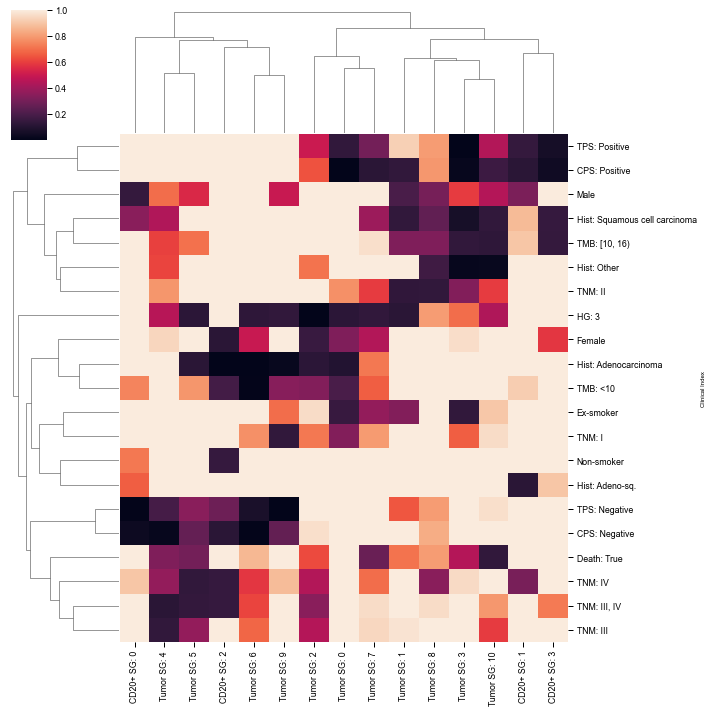

In [97]:
clinical_d_cmap = sns.clustermap(full_clinical_q)

In [98]:
full_clinical_colors.shape

(21, 15)

In [99]:
full_clustering_df.T.index

Index(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12',
       '13', '14', '15', '16', '17', '18', '19', '20', '21', '22'],
      dtype='object')

In [100]:
full_cc_colors_with_ct.index = [str(i) for i in range(full_cc_colors_with_ct.shape[0])]

In [101]:
def clean_up_big_l_clinical_tick(tick):
    tick_text = tick.get_text()
    return tick_text

In [102]:
SG_ORDER = [
    'CD20+ SG: 1', 
    'CD20+ SG: 3', 
    'CD20+ SG: 0', 
    'CD20+ SG: 2',
    '',
    'Tumor SG: 1',
    'Tumor SG: 8',
    'Tumor SG: 3',
    'Tumor SG: 10',
    'Tumor SG: 2',
    'Tumor SG: 0',
    'Tumor SG: 7',
    'Tumor SG: 6',
    'Tumor SG: 9',
    'Tumor SG: 4',
    'Tumor SG: 5',
]

In [103]:
empty = pandas.DataFrame({col: 0 for col in full_clustering_df.columns}, index=[''])
full_clustering_df = full_clustering_df.append(empty)

/tmp/ipykernel_69843/2648413226.py:2: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  full_clustering_df = full_clustering_df.append(empty)


In [104]:
full_cc_colors_with_ct.insert(
   32, '', [(1, 1, 1, 1) for _ in range(full_cc_colors_with_ct.shape[0])]
)

In [105]:
full_clinical_q

full_clinical_q.insert(
   0, '', [1 for _ in range(full_clinical_q.shape[0])]
)

full_clinical_q[''] = 1

In [106]:
full_clinical_q


,,CD20+ SG: 1,CD20+ SG: 3,CD20+ SG: 0,CD20+ SG: 2,Tumor SG: 1,Tumor SG: 8,Tumor SG: 3,Tumor SG: 10,Tumor SG: 2,Tumor SG: 0,Tumor SG: 7,Tumor SG: 6,Tumor SG: 9,Tumor SG: 4,Tumor SG: 5
Clinical Index,,,,,,,,,,,,,,,,
TPS: Negative,1,0.999485,0.999485,0.006315,0.279577,0.647035,0.799485,0.999997,0.965528,0.999997,0.999997,0.999997,0.067906,0.003761,0.182945,0.347898
CPS: Negative,1,0.999485,0.999485,0.034560,0.114016,0.999997,0.837949,0.999997,0.999997,0.965528,0.999997,0.999997,0.006666,0.255525,0.018170,0.259333
TNM: IV,1,0.306852,0.999485,0.900821,0.145695,0.997996,0.347898,0.955674,0.999997,0.439549,0.999997,0.695102,0.579972,0.876025,0.368724,0.131019
"TNM: III, IV",1,0.999485,0.720565,0.999485,0.145695,0.999997,0.959977,0.999997,0.789039,0.347898,0.999997,0.959977,0.611485,0.999997,0.112810,0.136694
Female,1,0.999485,0.579703,0.999485,0.114016,0.999997,0.999997,0.962993,0.999997,0.153146,0.324815,0.439549,0.492663,0.999997,0.944246,0.999997
Hist: Adenocarcinoma,1,0.999485,0.999485,0.999485,0.002330,0.999997,0.999997,0.999997,0.999997,0.115560,0.093027,0.717071,0.003761,0.022583,0.999997,0.112810
Non-smoker,1,0.999485,0.999485,0.716670,0.145695,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
TMB: <10,1,0.921942,0.999485,0.745024,0.180393,0.999997,0.999997,0.999997,0.999997,0.332795,0.194195,0.664123,0.005479,0.341693,0.999997,0.782645
Hist: Adeno-sq.,1,0.114016,0.900821,0.661483,0.999485,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [107]:
full_clinical_colors.insert(
   0, '', [(1, 1, 1, 1) for _ in range(full_clinical_colors.shape[0])]
)

In [108]:
full_clustering_df.columns.name = 'Cellular Neighborhood'
full_clustering_df.index.name = 'Slide Group'

In [109]:
def clean_up_tick(x):
    x = x.replace('%', '')
    x = x.replace('plasma', 'Plasma cells')
    return x

In [110]:
full_cc_colors_with_ct.columns = [
    clean_up_tick(col)
    for col in full_cc_colors_with_ct.columns
]

In [111]:
sd75_counts_final = sd75_counts.groupby('ROI').size()
tls_counts_final = tls_counts.groupby('SG').size()

In [112]:
TUMOR_SG_ORDER = [1, 8, 3, 10, 2, 0, 7, 6, 9, 4, 5]
TLS_SG_ORDER = [1, 3, 0, 2]

In [113]:
sg_counts = [
    tls_counts_final.values[ind_]
    for ind_ in TLS_SG_ORDER
] + [0] + [
    sd75_counts_final.values[ind_]
    for ind_ in TUMOR_SG_ORDER
]

In [114]:
sg_counts

[38, 56, 35, 43, 0, 59, 35, 26, 44, 36, 76, 36, 76, 56, 69, 56]

In [115]:
full_clinical_colors.index = [
    col.replace('TNM: IV', 'TNM: 4').replace('TNM: III, IV', 'TNM: 3, 4').replace('TNM: III', 'TNM: 3').replace(
        'TNM: II', 'TNM: 2').replace('TNM: I', 'TNM: 1')
    for col in full_clinical_colors.index
]

In [116]:
roi_cluster_with_clinical = roi_counts.groupby('immucan_id').first()

In [117]:
roi_cluster_with_clinical['simple_histology'].unique()

array(['Adenocarcinoma', 'Squamous cell carcinoma', 'Other',
       'Adenosquamous carcinoma'], dtype=object)

In [118]:
# NOTE: minimal fix. The original 4th value here, `stage_2-` (stage <= 2),
# didn't match the label full_clinical_colors.index[3] == 'TNM: 3, 4' (a
# high-stage pair) -- everything else in this list lines up perfectly
# position-by-position with the index (verified below), so this was an
# isolated one-off error, not a broken figure. Swapped for the matching
# high-stage-pair expression, consistent with how 'TNM: 4' and 'TNM: 3'
# alone are computed just above/below it.
assert len(full_clinical_colors.index) == 21, (
    f'expected 21 clinical categories, got {len(full_clinical_colors.index)} -- '
    'index changed, mapping below may no longer be positionally valid')

clinical_counts_for_big_l = pandas.DataFrame(
    [
        (roi_cluster_with_clinical['TPS_score'] == 'negative').sum(),
        (roi_cluster_with_clinical['CPS_score'] == 'negative').sum(),
        (roi_cluster_with_clinical['simple_stage'] == 4).sum(),
        (roi_cluster_with_clinical['simple_stage'] >= 3).sum(),  # was `stage_2-` -- see note above
        (roi_cluster_with_clinical['Gender_male'] == False).sum(),
        (roi_cluster_with_clinical['simple_histology'] == 'Adenocarcinoma').sum(),
        (roi_cluster_with_clinical['smoking_status'] == 'Non-smoker').sum(),
        (roi_cluster_with_clinical['tmb_class'] == '<0.1').sum(),
        (roi_cluster_with_clinical['simple_histology'] == 'Adenosquamous carcinoma').sum(),
        (roi_cluster_with_clinical['Gender_male'] == True).sum(),
        (roi_cluster_with_clinical['TPS_score'] == 'positive').sum(),
        (roi_cluster_with_clinical['CPS_score'] == 'positive').sum(),
        (roi_cluster_with_clinical['simple_histology'] == 'Squamous cell carcinoma').sum(),
        (roi_cluster_with_clinical['tmb_class'] == '[0.1, 0.16)').sum(),
        (roi_cluster_with_clinical['smoking_status'] == 'Ex-smoker').sum(),
        (roi_cluster_with_clinical['simple_histology'] == 'Other').sum(),
        (roi_cluster_with_clinical['simple_stage'] == 2).sum(),
        (roi_cluster_with_clinical['death']).sum(),
        (roi_cluster_with_clinical['simple_stage'] == 3).sum(),
        42, #HG:3
        (roi_cluster_with_clinical['simple_stage'] == 1).sum(),
    ],
    index=full_clinical_colors.index
)

# sanity checks
_n = len(roi_cluster_with_clinical)
assert clinical_counts_for_big_l.loc['Male'].item() + clinical_counts_for_big_l.loc['Female'].item() == _n
assert (clinical_counts_for_big_l.loc['TNM: 1'].item() + clinical_counts_for_big_l.loc['TNM: 2'].item()
        + clinical_counts_for_big_l.loc['TNM: 3'].item() + clinical_counts_for_big_l.loc['TNM: 4'].item() == _n)
assert (clinical_counts_for_big_l.loc['TNM: 3, 4'].item()
        == clinical_counts_for_big_l.loc['TNM: 3'].item() + clinical_counts_for_big_l.loc['TNM: 4'].item())
print('sanity checks passed, n =', _n)
clinical_counts_for_big_l

sanity checks passed, n = 191


,0
TPS: Negative,128
CPS: Negative,90
TNM: 4,10
"TNM: 3, 4",54
Female,79
Hist: Adenocarcinoma,124
Non-smoker,32
TMB: <10,89
Hist: Adeno-sq.,6
Male,112


In [119]:
full_clinical_colors.index = [
    ind_.replace('TMB Stage', 'TNM')
    for ind_ in full_clinical_colors.index
]

In [120]:
full_cc_colors_with_ct.columns = [
    col.replace('%', '')
    for col in full_cc_colors_with_ct.columns
]

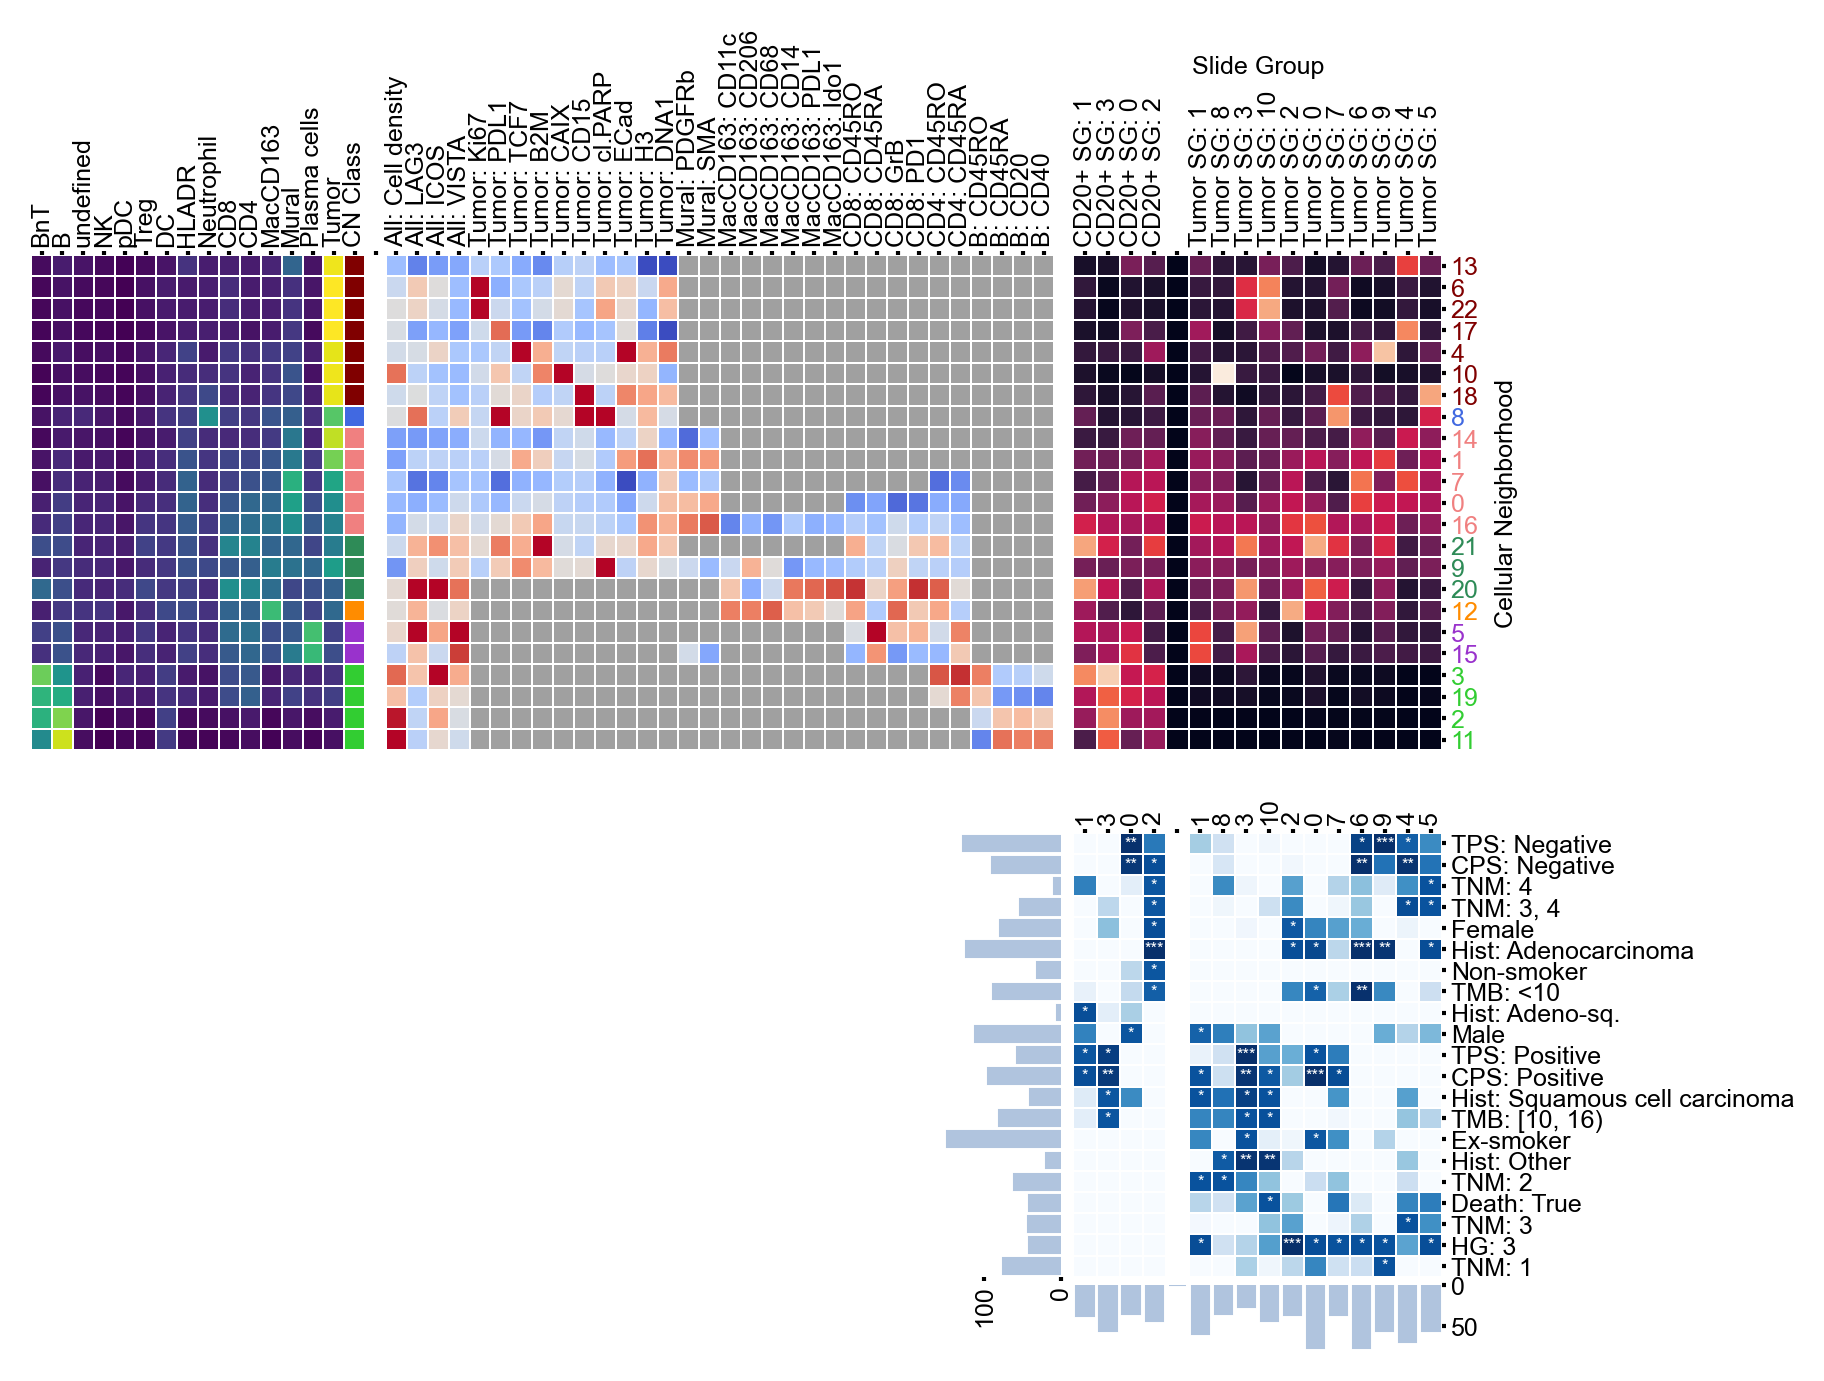

In [121]:
# FINAL-BIGL

matplotlib.rcParams['font.family'] = 'Arial'

#table = big_l_clustering_df[CLUSTERS_TO_KEEP].T ** 2

big_l_figure = sns.clustermap(
    full_clustering_df[
        [str(i) for i in META_CLUSTER_PERM]
    ].T[SG_ORDER],
    col_cluster=False,
    row_cluster=False,
    figsize=(8, 5.5),
    linewidth=0.0035,
    row_colors=full_cc_colors_with_ct.iloc[:, ::-1],
    col_colors=full_clinical_colors.T,#[clinical_d_cmap.data2d.index],
    colors_ratio=(0.012, 0.018),
    xticklabels=True,
    yticklabels=True,
    #vmax=numpy.quantile(full_clustering_df.values.flatten(), 0.95),
    cbar_pos=[0.8, 0.55, 0.05, 0.008],
    cbar_kws={'label': 'CN abundance', 'aspect': 10, 'orientation': 'horizontal'}
)

big_l_figure.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
big_l_figure.ax_heatmap.set_yticklabels(
    big_l_figure.ax_heatmap.get_yticklabels(), size=6,
)
big_l_figure.ax_heatmap.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_heatmap.set_xticklabels(
    big_l_figure.ax_heatmap.get_xticklabels(), size=6,
)
big_l_figure.ax_heatmap.xaxis.tick_top()

big_l_figure.ax_col_colors.yaxis.set_tick_params(size=1, pad=1, rotation=0)
big_l_figure.ax_col_colors.set_yticklabels(
    [clean_up_big_l_clinical_tick(tick) for tick in big_l_figure.ax_col_colors.get_yticklabels()],
    size=6,
)
big_l_figure.ax_row_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_row_colors.set_xticklabels(
    big_l_figure.ax_row_colors.get_xticklabels(), size=6,
)
big_l_figure.ax_row_colors.xaxis.tick_top()
big_l_figure.ax_col_colors.yaxis.tick_right()

ax_row_colors = big_l_figure.ax_row_colors
ax_col_colors = big_l_figure.ax_col_colors
row_box = ax_row_colors.get_position()
col_box = ax_col_colors.get_position()

box_heatmap = big_l_figure.ax_heatmap.get_position()
ax_col_colors.set_position([col_box.x0, box_heatmap.min[1] - col_box.height - 0.05, col_box.width, col_box.height])
ax_row_colors.set_position([box_heatmap.min[0] - row_box.width - 0.008, row_box.y0, row_box.width, row_box.height])

big_l_figure.ax_col_dendrogram.set_visible(False)
big_l_figure.ax_row_dendrogram.set_visible(False)
#big_l_figure.ax_cbar.set_visible(False)
big_l_figure.fig.set_dpi(PLOTTING_DPI)
#big_l_figure.fig.set_size_inches((9, 6.5))

#big_l_figure.ax_cbar.outline.set_visible(False)
big_l_figure.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
big_l_figure.ax_cbar.set_xlabel('Avg. sqrt.\nabundance', size=6)
big_l_figure.ax_cbar.set_xticks(
    [0, 15, 30],
    [0, 15, 30],
)
#big_l_figure.ax_cbar.set_visible(False)

ordered_counts = sg_counts
ordered_counts_cl = clinical_counts_for_big_l.values[::-1, 0]

bar_height = 0.04  # Adjust this to change the height of the barplot
bar_height_cl = 0.05
bar_ax = big_l_figure.fig.add_axes([
    col_box.x0, 
    ax_col_colors.get_position().min[1] - bar_height - 0.005,  # Position above col_colors
    col_box.width, 
    bar_height
])

bar_ax_cl = big_l_figure.fig.add_axes([
    col_box.x0 - bar_height_cl - 0.005, 
    ax_col_colors.get_position().max[1] - col_box.height,  # Position above col_colors
    bar_height_cl,
    col_box.height
])


# Create the barplot
x_positions = list(range(len(sg_counts)))
bars = bar_ax.bar(x_positions, sg_counts, width=0.75, 
                  color='lightsteelblue', edgecolor='lightsteelblue', linewidth=0.5)
bar_ax.invert_yaxis()
bar_ax.set_facecolor('white')

x_positions_cl = list(range(len(ordered_counts_cl)))
bars_cl = bar_ax_cl.barh(x_positions_cl, ordered_counts_cl, height=0.75, 
                  color='lightsteelblue', edgecolor='lightsteelblue', linewidth=0.5)
bar_ax_cl.invert_xaxis()
bar_ax_cl.set_facecolor('white')


# Style the barplot
bar_ax.set_xlim(-0.5, len(ordered_counts) - 0.5)
bar_ax.set_xticks([])  # Remove x-axis ticks since they're shown below
bar_ax.spines['bottom'].set_visible(False)
bar_ax.spines['top'].set_visible(False)
bar_ax.spines['right'].set_visible(False)
bar_ax.spines['left'].set_linewidth(0.0)

# Style y-axis
bar_ax.tick_params(axis='y', labelsize=6, size=1, pad=1)
#bar_ax.set_ylabel('Counts', size=6, labelpad=2)
bar_ax.yaxis.tick_right()

bar_ax_cl.set_ylim(-0.5, len(ordered_counts_cl) - 0.5)
bar_ax_cl.set_yticks([])  # Remove x-axis ticks since they're shown below
bar_ax_cl.spines['bottom'].set_visible(False)
bar_ax_cl.spines['top'].set_visible(False)
bar_ax_cl.spines['right'].set_visible(False)
bar_ax_cl.spines['left'].set_linewidth(0.0)

# Style y-axis
bar_ax_cl.tick_params(axis='x', labelsize=6, size=1, pad=1., rotation=90)

annot_shape = full_clinical_colors.values.shape
permuted_rois = list(big_l_figure.data2d.columns)
permuted_features = list(full_clinical_q.index)

for i in range(annot_shape[1]):
    for j in range(annot_shape[0]):
        current_text = full_clinical_q.T.loc[permuted_rois[i]].loc[permuted_features[j]]
        current_text = round(current_text, 2)
        stars = ''
        if current_text < 0.2:
            stars += '*'
        if current_text < 0.05:
            stars += '*'
        if current_text < 0.01:
            stars += '*'
        big_l_figure.ax_col_colors.text(
            i + 0.5, j + 0.5, 
            stars, 
            horizontalalignment='center', 
            verticalalignment='center',
            c='w', size=4)
        
        
#big_l_figure.ax_col_colors.set_xlabel('Slide Group', labelpad=7.2)
#big_l_figure.ax_col_colors.xaxis.set_label_position('bottom')
big_l_figure.ax_cbar.set_visible(False)

for ind_, tick in enumerate(big_l_figure.ax_heatmap.get_yticklabels()):
    tick.set_color(meta_cluster_colors[numpy.array(META_CLUSTER_PERM).argsort()[ps_argsort[ind_]]])

big_l_figure.ax_col_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_col_colors.xaxis.tick_top()
_ = big_l_figure.ax_col_colors.set_xticks(
    ticks=[i + 0.5 for i in range(len(big_l_figure.data2d.columns))],
    labels=[int(x.split(':')[1]) if len(x) else '' for x in big_l_figure.data2d.columns],
    size=6,
)

big_l_figure.ax_heatmap.xaxis.set_label_position('top')

In [122]:
TUMOR_SG_ORDER = [1, 8, 3, 10, 2, 0, 7, 6, 9, 4, 5]
TUMOR_TLS_ORDER = [1, 3, 0, 2]

## Cluster number selection:

Let us run the algorithm for the cluster number selection:

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
start_time = time.time()


if os.path.exists(PANEL_1_CLUSTER_SELECTION_PATH):
    with open(PANEL_1_CLUSTER_SELECTION_PATH, 'rb') as handle:
        cs_result = pickle.load(handle)
        cs_best_clusterers = cimu.get_best_clusters_from_cimu_result(cs_result)
else:
    # NOTE: PANEL_1_NB_OF_CLUSTERS was undefined anywhere in this notebook on a
    # fresh run; using CC_NB_OF_CLUSTERS (=23), the panel/ROI-type's configured
    # cluster count, set at the top of the notebook.
    # NOTE: was `cluster_counts` -- a per-CN-cluster total-cell-count Series
    # (cell_df.groupby(PREDICTION_CLUSTER_COLUMN).size(), 23 values total),
    # the wrong shape for this call. perform_cluster_selection needs a
    # rows=ROI/patient, columns=cluster-id count matrix -- roi_counts, used
    # for exactly that shape elsewhere in this notebook (e.g. the corr_df cell).
    cs_result, cs_best_clusterers = tau.perform_cluster_selection(
        roi_counts, 
        list(range(CC_NB_OF_CLUSTERS)),
        vectorization_function=VECTORIZER,
        nb_of_tries_per_cluster_nb=10,
    )
    os.makedirs(CLUSTER_SELECTION_PATH, exist_ok=True)
    with open(PANEL_1_CLUSTER_SELECTION_PATH, 'wb') as handle:
        # NOTE: was `panel_1_cs_result` (undefined typo) -- this is the actual
        # variable just computed above.
        pickle.dump(cs_result, handle)

print(time.time() - start_time)
```

and let us have a look at found cluster numbers:

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
cs_best_clusterers
```

## Patient Clustermap

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
print(sorted(cs_best_clusterers.keys()))

ROI_CLUSTERS = 11
clusterer = cs_best_clusterers[ROI_CLUSTERS]
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
_, vectors, clusters, clusterer, qvals = tau.visualize_patient_clusters_with_survival_analysis_and_hg_no_lung(
    patients_df=roi_counts,
    clusterer_type=clusterer,
    clusters_to_select=list(range(CC_NB_OF_CLUSTERS)),
    hypergeometric_columns=CLINICAL_DATA_COLS_FOR_ANALYSIS,
    vectorization_function=VECTORIZER, 
    filter_below_percentage=0.01,
    cmap='seismic',
    number_of_clusters=ROI_CLUSTERS,
    hypergeometric_fdr_alpha=0.1,
    hypergeometric_filter_nas=True,
)
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
from collections import defaultdict

import matplotlib.colors as mpc


hist_to_int = {
    'Adenocarcinoma': 0, 
    'Squamous cell carcinoma': 1, 
    'Other': 2,
    'Adenosquamous carcinoma': 3,
}


tmb_colors_dict = defaultdict(lambda: mpc.TABLEAU_COLORS['tab:cyan'])
tmb_colors_dict['[0.1, 0.16)'] = mpc.CSS4_COLORS['goldenrod']
tmb_colors_dict['>=0.16'] = mpc.CSS4_COLORS['maroon']
tmb_colors_dict['<0.1'] = mpc.CSS4_COLORS['limegreen']
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
UNK_COLOR = mpc.CSS4_COLORS['lightgrey']

HISTOLOGY_PLOT_NAME = 'Histology'
STAGE_PLOT_NAME = 'Stage'
TMB_PLOT_NAME = 'TMB'
DEATH_PLOT_NAME = 'Death'
CPS_PLOT_NAME = 'CPS'
TPS_PLOT_NAME = 'TPS'
NEO_PLOT_NAME = 'Neo-adjuv.'

# Genes
KRAS_PLOT_NAME = 'GM: KRAS'
TP53_PLOT_NAME = 'GM: TP53'
EGFR_PLOT_NAME = 'GM: EGFR'
PIK3CA_PLOT_NAME = 'GM: PIK3CA'
ERBB2_PLOT_NAME = 'GM: ERBB2'
ENV_EXP_NAME = 'Env.Exp.'
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
patient_to_clinical_colors_dict = {}

# Histology
patient_to_clinical_colors_dict[HISTOLOGY_PLOT_NAME] = [
    tau.SIMPLE_HISTOLOGY_COLORS[hist] for hist in roi_counts['simple_histology']
]

# Stage
patient_to_clinical_colors_dict[STAGE_PLOT_NAME] = [
    tau.SIMPLE_STAGE_COLORS[st] for st in roi_counts['simple_stage']
]

# TMB
tmb_color = defaultdict(lambda: UNK_COLOR)
tmb_color['[0.1, 0.16)'] = mpc.CSS4_COLORS['goldenrod']
tmb_color['>=0.16'] = mpc.CSS4_COLORS['maroon']
tmb_color['<0.1'] = mpc.CSS4_COLORS['limegreen']
patient_to_clinical_colors_dict[TMB_PLOT_NAME] = [
    tmb_color[st] for st in roi_counts['tmb_class']
]

# Death
death_color = defaultdict(lambda: UNK_COLOR)
death_color[True] = mpc.CSS4_COLORS['red']
death_color[False] = mpc.CSS4_COLORS['black']
patient_to_clinical_colors_dict[DEATH_PLOT_NAME] = [
    death_color[st] for st in roi_counts['death']
]

# CPS
cps_color = defaultdict(lambda: UNK_COLOR)
cps_color['positive'] = mpc.CSS4_COLORS['blue']
cps_color['negative'] = mpc.CSS4_COLORS['black']
patient_to_clinical_colors_dict[CPS_PLOT_NAME] = [
    cps_color[st] for st in roi_counts['CPS_score']
]

# TPS
tps_color = defaultdict(lambda: UNK_COLOR)
tps_color['positive'] = mpc.CSS4_COLORS['blue']
tps_color['negative'] = mpc.CSS4_COLORS['black']
patient_to_clinical_colors_dict[TPS_PLOT_NAME] = [
    tps_color[st] for st in roi_counts['TPS_score']
]

# Neoadjuvant therapy
neo_color = defaultdict(lambda: UNK_COLOR)
neo_color['Yes'] = mpc.CSS4_COLORS['green']
neo_color['No'] = mpc.CSS4_COLORS['black']
patient_to_clinical_colors_dict[NEO_PLOT_NAME] = [
    neo_color[st] for st in roi_counts['neo_adjuvant_treatment']
]

# GENES:
gene_color = defaultdict(lambda: UNK_COLOR)
gene_color[True] = mpc.CSS4_COLORS['white']
gene_color[False] = mpc.CSS4_COLORS['black']

# KRAS:
patient_to_clinical_colors_dict[KRAS_PLOT_NAME] = [
    gene_color[st] for st in roi_counts['KRAS']
]

# TP53
patient_to_clinical_colors_dict[TP53_PLOT_NAME] = [
    gene_color[st] for st in roi_counts['TP53']
]

#EGFR
patient_to_clinical_colors_dict[EGFR_PLOT_NAME] = [
    gene_color[st] for st in roi_counts['EGFR']
]

# PIK3CA
patient_to_clinical_colors_dict[PIK3CA_PLOT_NAME] = [
    gene_color[st] for st in roi_counts['PIK3CA']
]

# ERBB2
patient_to_clinical_colors_dict[ERBB2_PLOT_NAME] = [
    gene_color[st] for st in roi_counts['ERBB2']
]

env_color = defaultdict(lambda: UNK_COLOR)
env_color['None'] = mpc.CSS4_COLORS['black']
env_color['Asbestos'] = mpc.CSS4_COLORS['yellowgreen']
env_color['Chemical agent'] = mpc.CSS4_COLORS['yellow']
env_color['Other'] = mpc.CSS4_COLORS['orange']

# patient_to_clinical_colors_dict[ENV_EXP_NAME] = [
#     env_color[st] for st in roi_counts['environmental_exposure']
# ]

patient_to_clinical_colors_df = pandas.DataFrame(patient_to_clinical_colors_dict)
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
Counter(roi_counts['environmental_exposure'])
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
centers = []
bars = [0]
aux = 0


for cl_ in range(ROI_CLUSTERS):
    current_cluster_count = (clusters == cl_).sum()
    centers.append(aux + current_cluster_count // 2)
    aux += current_cluster_count
    bars.append(aux - 1)

    
ticks = []
current_cluster = 0

for i in range(len(clusters)):
    if i in centers:
        ticks.append(current_cluster)
        current_cluster += 1
        continue
    elif i in bars:
        ticks.append('|')
        continue
    else:
        ticks.append('')
        
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
horizontal_ticks = [
    str(tick).replace('|', '-') 
    for tick in ticks
]
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
plt.rcParams['font.family'] = 'Arial'

cluster_norm = matplotlib.colors.Normalize(vmin=0, vmax=ROI_CLUSTERS)
cluster_cmap = plt.get_cmap('nipy_spectral')

cluster_sm = matplotlib.cm.ScalarMappable(norm=cluster_norm, cmap=cluster_cmap)

vectors_df = pandas.DataFrame(
    vectors.T,
    index=patient_to_clinical_colors_df.index,
)
#vectors_df.index.name = ROI_PLOT_NAME
#vectors_df.columns.name = CC_PLOT_NAME


patient_to_clinical_colors_df['Cluster'] = [cluster_sm.to_rgba(x) for x in clusters]

BASE = 30

hist_to_int = {
    'Adenocarcinoma': 0, 
    'Squamous cell carcinoma': 1, 
    'Other': 2,
    'Adenosquamous carcinoma': 3,
}

clusters_with_histology = clusters.copy()

for ind_, (cl, hist) in enumerate(zip(clusters_with_histology, roi_counts['simple_histology'])):
    clusters_with_histology[ind_] = BASE * cl + hist_to_int[hist]

patient_clustermap = sns.clustermap( 
    vectors_df.iloc[clusters_with_histology.argsort()].T.iloc[(-vectors_df.std(axis=0)).argsort()].T,
    col_cluster=False,
    row_cluster=False,
    xticklabels=1,
    cbar_pos=[.99, 0.5, 0.01, .1],
    cbar_kws={'label': 'Abundace'},
    yticklabels=horizontal_ticks,
    row_colors=patient_to_clinical_colors_df,
    figsize=(6, 8),
    cmap='magma',
)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(rotation=0)

patient_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
patient_clustermap.ax_row_dendrogram.set_visible(False)
patient_clustermap.ax_col_dendrogram.set_visible(False)

patient_clustermap.ax_heatmap.set_yticklabels(
    patient_clustermap.ax_heatmap.get_yticklabels(), size=6)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
patient_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
patient_clustermap.ax_heatmap.set_xticklabels(
    patient_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)


patient_clustermap.ax_row_colors.xaxis.set_tick_params(size=1, top=True, pad=2, rotation=90)
patient_clustermap.ax_row_colors.set_xticklabels(
    patient_clustermap.ax_row_colors.get_xticklabels(), size=6,
)
patient_clustermap.ax_row_colors.xaxis.tick_top()
#patient_clustermap.ax_col_colors.set_yticklabels(
#    patient_clustermap.ax_col_colors.get_yticklabels(), size=6
#)
#patient_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

LEGEND_SPACING = 0.195

GOOD_HISTS = ['Adenocarcinoma', 'Squamous cell carcinoma', 'Adenosquamous carcinoma', 'Other']

pos_neg_handles = [
    matplotlib.patches.Patch(
        facecolor=tau.SIMPLE_HISTOLOGY_COLORS[name], 
        edgecolor='black') for name in GOOD_HISTS
]
pos_neg_legend = plt.legend(
    pos_neg_handles, 
    GOOD_HISTS, 
    title='Histology',
    bbox_to_anchor=(LEGEND_SPACING, .8125), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(pos_neg_legend)

GOOD_STAGES = [1, 2, 3, 4]

grade_handles = [
    matplotlib.patches.Patch(facecolor=tau.SIMPLE_STAGE_COLORS[name], edgecolor='black') 
    for name in GOOD_STAGES
]
grade_legend = plt.legend(
    grade_handles, 
    GOOD_STAGES, 
    title='TMB Stage',
    bbox_to_anchor=(LEGEND_SPACING, .7225), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(grade_legend)

GOOD_TMB = ['<0.1', '[0.1, 0.16)', '>=0.16']

tmb_handles = [
    matplotlib.patches.Patch(facecolor=tmb_color[name], edgecolor='black')
    for name in GOOD_TMB
]
tmb_legend = plt.legend(
    tmb_handles, 
    GOOD_TMB, 
    title='TMB',
    bbox_to_anchor=(LEGEND_SPACING, .6375), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(tmb_legend)

death_handles = [
    matplotlib.patches.Patch(facecolor=death_color[name], edgecolor='black') 
    for name in death_color
]
death_legend = plt.legend(
    death_handles, 
    death_color, 
    title='Death',
    bbox_to_anchor=(LEGEND_SPACING, .5725), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(death_legend)

GOOD_TPSES = ['Positive', 'Negative', 'Unknown']

ps_handles = [
    matplotlib.patches.Patch(facecolor=tps_color[name], edgecolor='black')
    for name in tps_color
]
ps_legend = plt.legend(
    ps_handles, 
    GOOD_TPSES,
    title='CPS, TPS',
    bbox_to_anchor=(LEGEND_SPACING, .5175), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(ps_legend)

neo_handles = [
    matplotlib.patches.Patch(facecolor=neo_color[x], edgecolor='black')
    for x in neo_color
]
neo_legend = plt.legend(
    neo_handles, 
    neo_color, 
    title=f'{NEO_PLOT_NAME}',
    bbox_to_anchor=(LEGEND_SPACING, .4425), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(neo_legend)

patient_clustermap.fig.set_dpi(PLOTTING_DPI)
patient_clustermap.fig.set_size_inches((4, 8))
```

## Clinical Data analysis

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
roi_counts[DUMMY_COL_NAME] = 1
roi_counts[ROI_CLUSTER_NAME] = clusters
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
roi_cluster_counts = pandas.pivot_table(
    roi_counts, 
    values=DUMMY_COL_NAME, 
    index=['immucan_id'],
    columns=[ROI_CLUSTER_NAME],
    aggfunc="sum",
).fillna(0) > 0
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
roi_cluster_counts.shape
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
ROI_CLUSTER_NAMES = [f'{ROI_CLUSTER_NAME}: {cl_}' for cl_ in roi_cluster_counts.columns]

ROI_CLUSTER_INDICES = list(roi_cluster_counts.columns)
roi_cluster_counts.columns = ROI_CLUSTER_NAMES
roi_cluster_counts.index.name = 'immucan_id'
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
roi_cluster_with_clinical = pandas.merge(roi_cluster_counts, clinical_data_df, on='immucan_id')
```

Now, let's filter out patients with percentage lower than `0.04`.

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
PERCENTAGE_TO_FILTER_OUT = 0.04

GOOD_ROI_CLUSTERS = [
    cl 
    for cl, row in roi_cluster_with_clinical[ROI_CLUSTER_NAMES].mean(axis=0).to_frame().iterrows()
    if row[0] > PERCENTAGE_TO_FILTER_OUT
]


GOOD_ROI_CLUSTERS_INDS = [
    row_nb 
    for row_nb, (cl, row) in enumerate(roi_cluster_with_clinical[ROI_CLUSTER_NAMES].mean(axis=0).to_frame().iterrows())
    if row[0] > PERCENTAGE_TO_FILTER_OUT
]
```

Now, let us compute a table with enrichements scores for clusters and clinical features, for subgroups of patients that have a particular ROI cluster:

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
import matplotlib.pyplot as plt


roi_pval_table = pandas.concat(
    [
        pandas.concat(
            [
                tau.compute_hypergeometrics_for_df(
                    df=roi_cluster_with_clinical,
                    clusters=roi_cluster_with_clinical[cluster] > 0,
                    column=column,
                    values=None,
                    filter_nas=True,
            ).iloc[[1]]
            for column in CLINICAL_DATA_COLS_FOR_ANALYSIS],
            axis=1,
        )
        for cluster in GOOD_ROI_CLUSTERS
    ],
    axis=0,
)

roi_pval_table.index = [
    f'{cluster}'
    for cluster in GOOD_ROI_CLUSTERS
]
```

Now, let's compute the FDR corrected p-values:

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
roi_qval_table = tau.apply_fdr_to_df(roi_pval_table)
```

Now, let's clean out the names of the clinical features:

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
raw_clinical_to_clean_clinical_names = {
    'smoking_status: ': '',
    '_score:': ':',
    'positive': 'Positive',
    'negative': 'Negative',
    'roman_simple_stage': 'TNB Stage',
    'simple_histology': 'Histology',
    'tmb_class': 'TMB',
    'stage_2-: False': 'TNB Stage: III, IV',
    'neo_adjuvant_treatment:': 'NeoAdj. Treat.:',
    'gender: ': '',
    'environmental_exposure': 'Env. Exposure',
    'KRAS': 'GM: KRAS',
    'PIK3CA': 'GM: PIK3CA',
    'EGFR': 'GM: EGFR',
    'TP53': 'GM: TP53',
    'ERBB2': 'GM: ERBB2',
    'death: 1': 'Death: True',
}

def clean_clinical_name(name, replacement_dict=None):
    if replacement_dict is None:
        replacement_dict = raw_clinical_to_clean_clinical_names
    for raw_name, clean_name in replacement_dict.items():
        name = name.replace(raw_name, clean_name)
    return name
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
roi_qval_table.columns = [clean_clinical_name(col) for col in roi_qval_table.columns]
```

Now, let's filter out the cases with `FDR_ALPHA` and lower scores:

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
FDR_ALPHA = 0.2

q_vals_sig_series = roi_qval_table.min() < FDR_ALPHA

sl_qvals_text = roi_qval_table.copy()
sl_qvals_text = sl_qvals_text.applymap(lambda x: str(round(x, 2)) if x < FDR_ALPHA  else '')
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
plt.figure(dpi=600)

clinical_cm = sns.clustermap(
    roi_qval_table.T[q_vals_sig_series], 
    cmap='Blues_r', 
    annot=sl_qvals_text.T[q_vals_sig_series], 
    yticklabels=sl_qvals_text.T[q_vals_sig_series].index,
    fmt='', 
    vmin=0,
    vmax=1.0,
    cbar_pos=[1.12, 0.35, 0.01, .1],
    cbar_kws={'label': 'FDR q-value'},
)
clinical_cm.ax_cbar.set_visible('False')
clinical_cm.ax_heatmap.xaxis.set_tick_params(rotation=0)

clinical_cm.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
clinical_cm.ax_row_dendrogram.set_visible(False)
clinical_cm.ax_col_dendrogram.set_visible(False)

clinical_cm.ax_heatmap.set_yticklabels(
    clinical_cm.ax_heatmap.get_yticklabels(), size=6
)
clinical_cm.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
clinical_cm.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
clinical_cm.ax_heatmap.set_xticklabels(
    clinical_cm.ax_heatmap.get_xticklabels(), size=6, rotation=90
)

clinical_cm.fig.set_dpi(PLOTTING_DPI)
clinical_cm.fig.set_size_inches((4, 4))
```

## Histology Narrowed Clinical Analysis

Analysis within histologies:

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
import matplotlib.pyplot as plt
from itertools import product


GROUP_SIZE_LIMIT = (roi_cluster_with_clinical['simple_stage'] == 4).sum()
CLINICAL_TYPES = tau.SIMPLE_HISTOLOGY_COLORS.keys()


dfs = []
indexes = []
for cluster, hist in product(GOOD_ROI_CLUSTERS, CLINICAL_TYPES):
    current_list = []
    hist_current_df = roi_cluster_with_clinical[roi_cluster_with_clinical['simple_histology'] == hist] 
    current_clusters = hist_current_df[cluster] > 0
    if sum(current_clusters) < GROUP_SIZE_LIMIT:
        continue
    for column in CLINICAL_DATA_COLS_FOR_ANALYSIS:
        if column == 'simple_histology':
            continue
        current_df = tau.compute_hypergeometrics_for_df(
                    df=hist_current_df,
                    clusters=current_clusters,
                    column=column,
                    values=None,
            )
        if current_df.shape[0] > 1:
            current_list.append(current_df.iloc[[1]])
    if len(current_list) > 0:
        dfs.append(pandas.concat(current_list, axis=1))
        indexes.append(f'{cluster} - {hist}')
    

p1_pl_sl_hist_p_val_table = pandas.concat(dfs)
p1_pl_sl_hist_p_val_table.fillna(1., inplace=True)


p1_pl_sl_hist_p_val_table.index = indexes

p1_pl_sl_hist_qvals = tau.apply_fdr_to_df(p1_pl_sl_hist_p_val_table)

fdr_alpha = 0.1

p1_pl_hist_q_vals_sig_series = p1_pl_sl_hist_qvals.min() < fdr_alpha

p1_pl_sl_hist_qvals_text = p1_pl_sl_hist_qvals.copy()
p1_pl_sl_hist_qvals_text = p1_pl_sl_hist_qvals_text.applymap(lambda x: str(round(x, 2)) if x < fdr_alpha else '')

plt.figure(dpi=600)

in_hist_clinical_cm = sns.clustermap(
    p1_pl_sl_hist_qvals.sort_index().T[p1_pl_hist_q_vals_sig_series], 
    cmap='Blues_r', 
    col_cluster=False,
    annot=p1_pl_sl_hist_qvals_text.sort_index().T[p1_pl_hist_q_vals_sig_series], 
    yticklabels=p1_pl_sl_hist_qvals_text.T[p1_pl_hist_q_vals_sig_series].index,
    fmt='', 
    vmin=0,
    vmax=1.0,
    #cbar=False,
    figsize=(10, 10),
)
#clinical_cm.ax_cbar.set_visible('False')
```

and within the whole dataset:

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
import matplotlib.pyplot as plt
from itertools import product


GROUP_SIZE_LIMIT = (roi_cluster_with_clinical['simple_stage'] == 4).sum()
CLINICAL_TYPES = tau.SIMPLE_HISTOLOGY_COLORS.keys()


dfs = []
indexes = []
for cluster, hist in product(GOOD_ROI_CLUSTERS, CLINICAL_TYPES):
    current_list = []
    current_clusters = (
        roi_cluster_with_clinical[cluster] > 0
    ) * (roi_cluster_with_clinical['simple_histology'] == hist)
    if sum(current_clusters) < GROUP_SIZE_LIMIT:
        continue
    for column in CLINICAL_DATA_COLS_FOR_ANALYSIS:
        if column == 'simple_histology':
            continue
        current_df = tau.compute_hypergeometrics_for_df(
                    df=roi_cluster_with_clinical,
                    clusters=current_clusters,
                    column=column,
                    values=None,
            )
        if current_df.shape[0] > 1:
            current_list.append(current_df.iloc[[1]])
    if len(current_list) > 0:
        dfs.append(pandas.concat(current_list, axis=1))
        indexes.append(f'{cluster} - {hist}')
    

p1_pl_sl_hist_p_val_table = pandas.concat(dfs)
p1_pl_sl_hist_p_val_table.fillna(1., inplace=True)


p1_pl_sl_hist_p_val_table.index = indexes

p1_pl_sl_hist_qvals = tau.apply_fdr_to_df(p1_pl_sl_hist_p_val_table)

fdr_alpha = 0.1

p1_pl_hist_q_vals_sig_series = p1_pl_sl_hist_qvals.min() < fdr_alpha

p1_pl_sl_hist_qvals_text = p1_pl_sl_hist_qvals.copy()
p1_pl_sl_hist_qvals_text = p1_pl_sl_hist_qvals_text.applymap(lambda x: str(round(x, 2)) if x < fdr_alpha else '')

plt.figure(dpi=600)

hist_clinical_cm = sns.clustermap(
    p1_pl_sl_hist_qvals.T[p1_pl_hist_q_vals_sig_series], 
    cmap='Blues_r', 
    annot=p1_pl_sl_hist_qvals_text.T[p1_pl_hist_q_vals_sig_series], 
    yticklabels=p1_pl_sl_hist_qvals_text.T[p1_pl_hist_q_vals_sig_series].index,
    fmt='', 
    vmin=0,
    vmax=1.0,
    #cbar=False,
    figsize=(10, 10),
)
#clinical_cm.ax_cbar.set_visible('False')
```

Now, let's prepare a colored version of the above table:

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
clinical_norm = matplotlib.colors.Normalize(vmin=0, vmax=1)
clinical_cmap = plt.get_cmap('Blues_r')

clinical_sm = matplotlib.cm.ScalarMappable(norm=clinical_norm, cmap=clinical_cmap)

clinical_colors = clinical_cm.data2d.applymap(lambda x: clinical_sm.to_rgba(x))
```

## Survival analysis:

Now, let's prepare a table for the Cox analysis. We will use the information about grades and clinical types, similarly to the original paper.

### CC Cluster analysis:

Now, let's prepare the main Cox table for the Cellohood cluster sqrt counts:

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
additional_feature_columns=('is_adeno', 'is_squamous',)# 'Gender_male', 'Smoking', 'Smoking-Non', 'Smoking-Ex')

STD_EPS = 2

jackson_survival_df_clusters = pandas.DataFrame(
    {
        **{
            'died': roi_counts[tau.DEATH_COLNAME],
            'survival': roi_counts[tau.SURVIVAL_COLNAME], 
            'simple_stage': roi_counts[tau.SIMPLE_STAGE_COLNAME],
        },
       **{
            col: roi_counts[col]
            for col in additional_feature_columns
        },
        **{
            f'simple_stage_{i}': (roi_counts[tau.SIMPLE_STAGE_COLNAME] == i).astype('int')
            for i in range(1, 4 + 1) if sum(roi_counts[tau.SIMPLE_STAGE_COLNAME] == i)
        },
        **{
            f'pl_{i}': roi_counts[i] ** 0.5 
            for i in range(CC_NB_OF_CLUSTERS)
            if (roi_counts[i] ** 0.5).std() > STD_EPS
        },
    }
)
```

Now, let's run the Cox model:

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
def rename_cox_summary_index(index_, prefix='ROI', simple_stage_name='Grade'):
    new_index = []
    for el in index_:
        if el.startswith('pl'):
            new_index.append(f'{prefix}: {el.split("_")[-1]}')
            continue
        if el.startswith('simple_stage'):
            new_index.append(f'{simple_stage_name}: {el.split("_")[-1]}')
            continue
        new_index.append(el)
    return new_index
        
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
l2_true_value = 1e-3
l1_true_value = 0

coxphf_penalizer = l1_true_value + l2_true_value
coxphf_l1 = l1_true_value / (l1_true_value + l2_true_value)


jackson_cluster_cox = tau.surivial_on_df(
    jackson_survival_df_clusters, 
    l1_ratio=coxphf_l1,
    penalizer=coxphf_penalizer, 
    standardize=True,
    #cox_kwargs={'step_size': 0.1},
    fit_kwargs={
        'robust': True, 
        'strata': 'simple_stage_1', 
    }
)
plt.style.use('seaborn-v0_8-darkgrid')
plt.figure(figsize=(4, 6), dpi=300)
jackson_cluster_cox.plot()
plt.title('Cellohood Cluster log-1p, area-adjusted abundances vs Survial', size=6)
cox_ax = plt.gca()
yticklabels = [el.get_text() for el in cox_ax.get_yticklabels()]
_ = cox_ax.set_yticklabels(rename_cox_summary_index(yticklabels, prefix='CC'), size=6)
plt.ylabel('Feature', labelpad=1, fontdict={'size': 6})
plt.xlabel('log(HR) (95% CI)', labelpad=1, fontdict={'size': 6})
cox_ax.yaxis.set_tick_params(pad=1, size=1)
_ = cox_ax.set_xticklabels(cox_ax.get_xticklabels(), size=6)
```

### ROI Cluster Analysis

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
survival_df = pandas.DataFrame(
       {
            **{
                'died': roi_cluster_with_clinical[tau.DEATH_COLNAME],
                'survival': roi_cluster_with_clinical[tau.SURVIVAL_COLNAME], 
                'simple_stage': roi_cluster_with_clinical[tau.SIMPLE_STAGE_COLNAME],
            },
           **{
               col: roi_cluster_with_clinical[col]
               for col in additional_feature_columns
           },
            **{
                f'simple_stage_{i}': roi_cluster_with_clinical[tau.SIMPLE_STAGE_COLNAME] == i
                for i in range(1, 4 + 1) if sum(roi_cluster_with_clinical[tau.SIMPLE_STAGE_COLNAME] == i)
            },
#             **{
#                 f'pl_{ROI_CLUSTERS}_{int(i)}': roi_cluster_with_clinical[f'ROI: {i}']
#                 for i in GOOD_ROI_CLUSTERS_INDS
#             },
           **{
               f'HG_{i}': (roi_cluster_with_clinical[ROI_CLUSTER_NAMES].sum(axis=1) == i).astype(int)
               for i in range(1, 3 + 1)
           }
        }
    )
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
def get_cox_feature_colors(
    feature,
    cluster_prefix='ROI: '
):
    if feature.startswith(cluster_prefix):
        cluster_ind = int(feature.split(cluster_prefix)[-1])
        return cluster_sm.to_rgba(cluster_ind)
    if feature.startswith('HR'):
        return clinical_type_color[feature]
    if feature.startswith('Grade'):
        grade_int = int(feature[-1])
        return grade_color[grade_int]
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
jackson_cox = tau.surivial_on_df(
    survival_df,
    l1_ratio=coxphf_l1,
    penalizer=coxphf_penalizer,
    fit_kwargs={'robust': True, 'strata': 'simple_stage_1'},
)

plt.style.use('seaborn-v0_8-darkgrid')
plt.figure(figsize=(1., 1.6), dpi=300)
ax = jackson_cox.plot()
yticklabels = [el.get_text() for el in ax.get_yticklabels()]
new_labels = rename_cox_summary_index(yticklabels)
_ = ax.set_yticklabels(new_labels, size=6)
#for ticklabel, tickcolor in zip(ax.get_yticklabels(), labels_colors):
#    ticklabel.set_color(tickcolor)
ax.yaxis.set_tick_params(pad=1, size=1)
_ = ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.xaxis.set_tick_params(pad=1, size=1)
#ax.set_ylabel('Feature')
ax.set_title('Cox PH Model\nfor ROI Clusters', fontsize=6, pad=1)
#ax.get_children()[0].set_color('blue')
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
jackson_cox.summary
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
DATA_COX_COLS = ['died', 'survival', 'simple_stage', 'is_adeno', 'simple_stage_1',
       'simple_stage_2', 'simple_stage_3', 'simple_stage_4']


for roi in GOOD_ROI_CLUSTERS_INDS:
    current_cluster_colname = f'pl_{ROI_CLUSTERS}_{int(roi)}'
    current_cox_cols = DATA_COX_COLS + [current_cluster_colname]
    current_cox = tau.surivial_on_df(
        survival_df[current_cox_cols], 
        l1_ratio=coxphf_l1, 
        penalizer=coxphf_penalizer,
        fit_kwargs={'robust': False, 'strata': 'simple_stage_1'},
    )
    if current_cox.summary.loc[current_cluster_colname]['coef lower 95%'] * current_cox.summary.loc[current_cluster_colname]['coef upper 95%'] > 0:
        plt.figure(figsize=(10, 10))
        current_cox.plot()
        plt.title(roi)
```

## Kaplan-Meier Curves:

### Cross-ROI clusters analysis

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
cluster_log_rank_p_values = numpy.ones((len(GOOD_ROI_CLUSTERS), 1))


for l_ind, l_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
        l_current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] == 1]
        r_current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] != 1]
        l_N = l_current_df.shape[0]
        if l_N < 15:
            print(l_N)
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        cluster_log_rank_p_values[l_ind, 0] = current_test.p_value
        if cluster_log_rank_p_values[l_ind, 0] < 0.05:
            plt.figure(figsize=(2, 2), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f' {l_roi_cc}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'!{l_roi_cc}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(f'{l_roi_cc} N = {l_current_df.shape[0]}\n(log-rank p = {round(cluster_log_rank_p_values[l_ind, 0], 3)})', size=6)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=1)
            plt.show()
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
cluster_log_rank_p_values_df = pandas.DataFrame(
    cluster_log_rank_p_values,
    index=GOOD_ROI_CLUSTERS,
)
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
sns.clustermap(cluster_log_rank_p_values_df.T, row_cluster=False, annot=True)
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
cross_cluster_log_rank_p_values = numpy.ones((len(GOOD_ROI_CLUSTERS), len(GOOD_ROI_CLUSTERS)))


for l_ind, l_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
    for r_ind, r_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
        l_current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] == 1]
        r_current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[r_roi_cc] == 1]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 15 or r_N < 15:
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        cross_cluster_log_rank_p_values[l_ind, r_ind] = current_test.p_value
        if cross_cluster_log_rank_p_values[l_ind, r_ind] < 0.05:
            plt.figure(figsize=(2, 2), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & {r_roi_cc}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & !{r_roi_cc}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(f'{l_roi_cc} & {r_roi_cc} N = {l_current_df.shape[0]} vs\n {l_roi_cc} & !{r_roi_cc} N = {r_current_df.shape[0]}\n(log-rank p = {round(cross_cluster_log_rank_p_values[l_ind, r_ind], 3)})', size=6)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=1)
            plt.show()
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
cross_cluster_log_rank_p_values_df = pandas.DataFrame(
    cross_cluster_log_rank_p_values,
    index=GOOD_ROI_CLUSTERS,
    columns=GOOD_ROI_CLUSTERS,
)
cross_cluster_log_rank_p_values_df.index.name = f'{ROI_COLUMN} Clusters'
cross_cluster_log_rank_p_values_df.columns.name = f'{ROI_COLUMN} Clusters'
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
cross_cluster_log_rank_cmap = sns.clustermap(
    cross_cluster_log_rank_p_values_df,
    cmap='Purples_r',
    annot=True,
    fmt='.2f',
    vmin=0,
    vmax=1.0,
    cbar_pos=[1.12, 0.35, 0.01, .1],
    cbar_kws={'label': 'Log-rank test p-value'},
)

cross_cluster_log_rank_cmap.ax_cbar.set_visible('False')
cross_cluster_log_rank_cmap.ax_heatmap.xaxis.set_tick_params(rotation=0)

cross_cluster_log_rank_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
cross_cluster_log_rank_cmap.ax_row_dendrogram.set_visible(False)
cross_cluster_log_rank_cmap.ax_col_dendrogram.set_visible(False)

cross_cluster_log_rank_cmap.ax_heatmap.set_yticklabels(
    cross_cluster_log_rank_cmap.ax_heatmap.get_yticklabels(), size=6
)
cross_cluster_log_rank_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
cross_cluster_log_rank_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
cross_cluster_log_rank_cmap.ax_heatmap.set_xticklabels(
    cross_cluster_log_rank_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90
)

cross_cluster_log_rank_cmap.fig.set_dpi(PLOTTING_DPI)
cross_cluster_log_rank_cmap.fig.set_size_inches((4, 4))
```

### Clinical Type vs ROI analysis

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
CLINICAL_TYPES = tau.SIMPLE_HISTOLOGY_COLORS.keys()


cluster_vs_ct_log_rank_pvalues = numpy.ones((len(CLINICAL_TYPES), len(GOOD_ROI_CLUSTERS)))


for l_ind, l_roi_cc in enumerate(CLINICAL_TYPES):
    current_df = roi_cluster_with_clinical[roi_cluster_with_clinical['simple_histology'] == l_roi_cc]
    for r_ind, r_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
        l_current_df = current_df[current_df[r_roi_cc] == 1]
        r_current_df = current_df[current_df[r_roi_cc] != 1]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 15 or r_N < 15:
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        if numpy.isnan(current_test.p_value):
            continue
        cluster_vs_ct_log_rank_pvalues[l_ind, r_ind] = current_test.p_value
        if cluster_vs_ct_log_rank_pvalues[l_ind, r_ind] < 0.05:
            plt.figure(figsize=(1.4, 1.4), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & {r_roi_cc}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & !{r_roi_cc}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(f'{l_roi_cc} & {r_roi_cc} N = {l_N} vs\n {l_roi_cc} & !{r_roi_cc} N = {r_N}\n(log-rank p = {round(cluster_vs_ct_log_rank_pvalues[l_ind, r_ind], 3)})', size=6)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=0.1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=0.1)
            ax.set_xlabel('timeline', labelpad=0)
            ax.grid(zorder=0)
            plt.ylim([0, 1.1])
            ax.spines[['left', 'right', 'top', 'bottom']].set_visible(False)
            ax.set_axisbelow(True)
            ax.set_facecolor('whitesmoke')
            ax.grid(color='white', gapcolor='gray')
            plt.show()
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
cluster_vs_ct_log_rank_pvalues_df = pandas.DataFrame(
    cluster_vs_ct_log_rank_pvalues,
    columns=GOOD_ROI_CLUSTERS,
    index=CLINICAL_TYPES,
)
cluster_vs_ct_log_rank_pvalues_df.columns.name = f'{ROI_COLUMN} Clusters'
cluster_vs_ct_log_rank_pvalues_df.index.name = f'Clinical Type'
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
cluster_vs_ct_log_rank_cmap = sns.clustermap(
    cluster_vs_ct_log_rank_pvalues_df,
    cmap='Purples_r',
    annot=True,
    fmt='.2f',
    vmin=0,
    vmax=1.0,
    cbar_pos=[1.12, 0.35, 0.01, .1],
    cbar_kws={'label': 'Log-rank test p-value'},
)

cluster_vs_ct_log_rank_cmap.ax_cbar.set_visible('False')
cluster_vs_ct_log_rank_cmap.ax_heatmap.xaxis.set_tick_params(rotation=0)

cluster_vs_ct_log_rank_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
cluster_vs_ct_log_rank_cmap.ax_row_dendrogram.set_visible(False)
cluster_vs_ct_log_rank_cmap.ax_col_dendrogram.set_visible(False)

cluster_vs_ct_log_rank_cmap.ax_heatmap.set_yticklabels(
    cluster_vs_ct_log_rank_cmap.ax_heatmap.get_yticklabels(), size=6
)
cluster_vs_ct_log_rank_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
cluster_vs_ct_log_rank_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
cluster_vs_ct_log_rank_cmap.ax_heatmap.set_xticklabels(
    cluster_vs_ct_log_rank_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90
)

cluster_vs_ct_log_rank_cmap.fig.set_dpi(PLOTTING_DPI)
cluster_vs_ct_log_rank_cmap.fig.set_size_inches((4, 1))
```

### Clinical type vs ROI

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
ct_vs_cluster_log_rank_pvalues = numpy.ones((len(GOOD_ROI_CLUSTERS), len(CLINICAL_TYPES)))


for l_ind, l_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
    current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] == 1]
    for r_ind, r_roi_cc in enumerate(CLINICAL_TYPES):
        l_current_df = current_df[current_df['simple_histology'] == r_roi_cc]
        r_current_df = current_df[current_df['simple_histology'] != r_roi_cc]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 10 or r_N < 10:
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        if numpy.isnan(current_test.p_value):
            continue
        ct_vs_cluster_log_rank_pvalues[l_ind, r_ind] = current_test.p_value
        if ct_vs_cluster_log_rank_pvalues[l_ind, r_ind] < 0.05:
            plt.figure(figsize=(1.4, 1.5), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc.replace("ROI: ", "")} & {r_roi_cc}, N={l_N}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc.replace("ROI: ", "")} & !{r_roi_cc}, N={r_N}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(
                f'{l_roi_cc} vs {r_roi_cc} (p={round(ct_vs_cluster_log_rank_pvalues[l_ind, r_ind], 3)})',
                size=6, pad=0)
            ax.set_xlabel('timeline', labelpad=0)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.spines[['left', 'right', 'top', 'bottom']].set_visible(False)
            ax.set_axisbelow(True)
            ax.set_facecolor('whitesmoke')
            leg = plt.gca().get_legend()

            # Get the current legend properties
            labels = [text.get_text() for text in leg.get_texts()]
            handles = leg.legendHandles

# Remove old legend
            leg.remove()

# Create new legend with desired handle length
            plt.legend(handles, labels, handlelength=.5)
            ax.get_legend().handlelength = 0.1
#             for legend_line in ax.get_legend().get_lines():
#                 legend_line.set_xdata(legend_line.get_xdata() / 3.)
#             for t in ax.get_legend().get_texts():
#                 text_width = t.get_window_extent().width
#                 t.set_ha('right')
            ax.grid(color='white', gapcolor='gray')
            plt.tight_layout()
            plt.show()
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
ct_vs_cluster_log_rank_pvalues_df = pandas.DataFrame(
    ct_vs_cluster_log_rank_pvalues,
    index=GOOD_ROI_CLUSTERS,
    columns=CLINICAL_TYPES,
)
ct_vs_cluster_log_rank_pvalues_df.index.name = f'{ROI_COLUMN} Clusters'
ct_vs_cluster_log_rank_pvalues_df.columns.name = f'Clinical Type'
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
ct_vs_clusterlog_rank_cmap = sns.clustermap(
    ct_vs_cluster_log_rank_pvalues_df,
    cmap='Purples_r',
    annot=True,
    fmt='.2f',
    vmin=0,
    vmax=1.0,
    cbar_pos=[1.12, 0.35, 0.01, .1],
    cbar_kws={'label': 'Log-rank test p-value'},
)

ct_vs_clusterlog_rank_cmap.ax_cbar.set_visible('False')
ct_vs_clusterlog_rank_cmap.ax_heatmap.xaxis.set_tick_params(rotation=0)

ct_vs_clusterlog_rank_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
ct_vs_clusterlog_rank_cmap.ax_row_dendrogram.set_visible(False)
ct_vs_clusterlog_rank_cmap.ax_col_dendrogram.set_visible(False)

ct_vs_clusterlog_rank_cmap.ax_heatmap.set_yticklabels(
    ct_vs_clusterlog_rank_cmap.ax_heatmap.get_yticklabels(), size=6
)
ct_vs_clusterlog_rank_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
ct_vs_clusterlog_rank_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
ct_vs_clusterlog_rank_cmap.ax_heatmap.set_xticklabels(
    ct_vs_clusterlog_rank_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90
)

ct_vs_clusterlog_rank_cmap.fig.set_dpi(PLOTTING_DPI)
ct_vs_clusterlog_rank_cmap.fig.set_size_inches((4, 1))
```

## Grade vs ROI

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
GRADES = [1, 2, 3, 4]

grade_vs_cluster_log_rank_pvalues = numpy.ones((len(GOOD_ROI_CLUSTERS), len(GRADES)))


for l_ind, l_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
    current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] == 1]
    for r_ind, r_roi_cc in enumerate(GRADES):
        l_current_df = current_df[current_df['simple_stage'] == r_roi_cc]
        r_current_df = current_df[current_df['simple_stage'] != r_roi_cc]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 10 or r_N < 10:
            print(l_roi_cc, r_roi_cc, l_N, r_N)
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        if numpy.isnan(current_test.p_value):
            continue
        grade_vs_cluster_log_rank_pvalues[l_ind, r_ind] = current_test.p_value
        if grade_vs_cluster_log_rank_pvalues[l_ind, r_ind] < 0.05:
            plt.figure(figsize=(2, 2), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & {r_roi_cc}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & !{r_roi_cc}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(f'{l_roi_cc} & {r_roi_cc} N = {l_N} vs\n {l_roi_cc} & !{r_roi_cc} N = {r_N}\n(log-rank p = {round(grade_vs_cluster_log_rank_pvalues[l_ind, r_ind], 3)})', size=6)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=1)
            plt.show()
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
GRADES = [1, 2, 3, 4]

grade_vs_cluster_log_rank_pvalues = numpy.ones((len(GRADES), len(GOOD_ROI_CLUSTERS)))

xticks_font = matplotlib.font_manager.FontProperties(family='Arial')


for l_ind, l_roi_cc in enumerate(GRADES):
    current_df = roi_cluster_with_clinical[roi_cluster_with_clinical['simple_stage'] == l_roi_cc]
    for r_ind, r_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
        l_current_df = current_df[current_df[r_roi_cc] == 1]
        r_current_df = current_df[current_df[r_roi_cc] != 1]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 10 or r_N < 10:
            print(l_roi_cc, r_roi_cc)
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        if numpy.isnan(current_test.p_value):
            continue
        grade_vs_cluster_log_rank_pvalues[l_ind, r_ind] = current_test.p_value
        if grade_vs_cluster_log_rank_pvalues[l_ind, r_ind] < 0.05:
            plt.figure(figsize=(1.4, 1.5), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'Gr. {l_roi_cc} & {r_roi_cc},  N={l_N}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'Gr. {l_roi_cc} & !{r_roi_cc}, N={r_N}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(
                f'Grade {l_roi_cc} vs {r_roi_cc} (p={round(grade_vs_cluster_log_rank_pvalues[l_ind, r_ind], 3)})',
                size=6, pad=0)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=0.1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=0.1)
            ax.set_xlabel('timeline', labelpad=0)
            ax.grid(zorder=0)
            plt.ylim([0, 1.1])
            ax.spines[['left', 'right', 'top', 'bottom']].set_visible(False)
            ax.set_axisbelow(True)
            ax.set_facecolor('whitesmoke')
            ax.grid(color='white', gapcolor='gray')
            leg = plt.gca().get_legend()

            # Get the current legend properties
            labels = [text.get_text() for text in leg.get_texts()]
            handles = leg.legendHandles

# Remove old legend
            leg.remove()

# Create new legend with desired handle length
            plt.legend(handles, labels, handlelength=.5)
            ax.get_legend().handlelength = 0.1
#             for legend_line in ax.get_legend().get_lines():
#                 legend_line.set_xdata(legend_line.get_xdata() / 3.)
#             for t in ax.get_legend().get_texts():
#                 text_width = t.get_window_extent().width
#                 t.set_ha('right')
            #c
            plt.tight_layout()
            plt.show()
```

## Marker Cluster analysis for cell types

Now let's analyse the marker expression for cells within certain Cellohood Clusters:

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
celltypes_display_percentage = defaultdict(lambda: 0.05)
celltypes_display_percentage['Tumor'] = 0.15
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
celltypes_to_marker_to_show = {
    'B': ['CD40', 'CD20'],
    'CD4': ['LAG3'],
    'CD8': ['PD1', 'GrB'],
    'MacCD163': [
        'Ido1', 'PDL1', 'CD14', 'CD68', 'CD206'],
    'Mural': ['SMA'],
    'Tumor': ['DNA1', 'H3', 'ECad', 'cl.PARP', 'CAIX',
        'CD15', 'PDL1', 'Ki67', 'B2M', 'TCF7']
    #'All': ['Ki67', 'c-Myc', 'CAIX', 'vWF', 'SMA']
}
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
celltypes_cc_display = {
    ct: [
        ind_ 
        for ind_, cc_ in enumerate(celltype_percentages[ct] > celltypes_display_percentage[ct])
        if cc_
    ]
    for ct in celltypes_to_marker_to_show
}
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
cc_colors_dict = {}
for ct, markers in celltypes_to_marker_to_show.items():
    for marker in markers:
        cc_colors_dict[f'{ct}: {marker}'] = transform_vec_to_colors( 
                vec=celltype_to_marker_dfs_clean[ct].loc[marker],
                colors=marker_sm,
                display=celltypes_cc_display[ct] if ct in celltypes_cc_display else None,
            )


cc_marker_ct_colors = pandas.DataFrame(cc_colors_dict)

cc_marker_ct_colors['All: Cell density'] = transform_vec_to_colors( 
        vec=cc_densities,
        colors=marker_sm,
)
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
COLORBARS_SHIFT = 0.92

cc_abundance_std_argsort = (-celltype_percentages['Tumor'].values).argsort()

celltype_clustermap = sns.clustermap(
    (celltype_percentages[celltypes].T * 100)[cc_abundance_std_argsort], 
    annot=True,
    col_cluster=False,
    fmt='.0f',
    cmap='viridis',
    figsize=(5, 7),
    col_colors=cc_marker_ct_colors,
    #row_colors=[class_to_color[celltype_to_class[ct]] for ct in numpy.array(celltypes)],
    colors_ratio=0.015,
    yticklabels=True,
    xticklabels=cc_abundance_std_argsort,
    #linewidth=0.003
    #annot_kws={"size": 3},
    cbar_pos=[COLORBARS_SHIFT + 0.05, 0.25, 0.01, .1],
    cbar_kws={'label': 'CC Abundance'}
)


#handles = [Patch(facecolor=class_to_color[name]) for name in class_to_color]
#plt.legend(
#    handles, 
#    class_to_color, 
#    title=' Cell type Metatype',
#    bbox_to_anchor=(0.17, 0.53), 
#    bbox_transform=plt.gcf().transFigure,
#    frameon=False,
#    fontsize=6,
#)

celltype_clustermap.ax_col_dendrogram.set_visible(False)

cb_ax = celltype_clustermap.fig.add_axes([COLORBARS_SHIFT, .27, .05, .8])
cb_ax.imshow([[0, 1]])
cb_ax.set_visible(False)

cbar = celltype_clustermap.fig.colorbar(
    marker_sm, 
    drawedges=False,
    #bbox_to_anchor=(1, 0.5),
    label='Z-scored mean\nmarker expression',
    ax=cb_ax,
    #panchor=(1.5, 0.5),
    #anchor=(1.5, 0.5),
)

cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=6, size=1, pad=1)

celltype_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_clustermap.ax_row_dendrogram.set_visible(False)
celltype_clustermap.ax_col_dendrogram.set_visible(False)

celltype_clustermap.ax_heatmap.set_yticklabels(celltype_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1)
celltype_clustermap.ax_heatmap.set_xticklabels(celltype_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
celltype_clustermap.ax_col_colors.set_yticklabels(celltype_clustermap.ax_col_colors.get_yticklabels(), size=6)
celltype_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)


celltype_clustermap.fig.set_dpi(300)
celltype_clustermap.fig.set_size_inches((4, 6))
plt.tight_layout()
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
for ct in ['CD4']:
    print(ct)
    sns.clustermap(
        celltype_to_marker_dfs_clean[ct].loc[MARKERS_CLEAN][cc_abundance_std_argsort], 
        yticklabels=MARKERS_CLEAN,
        z_score=0,
        center=0,
        cmap='coolwarm',
        col_cluster=False,
        vmin=-2,
        vmax=2,
    )
    plt.show()
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
clustering_df = pandas.DataFrame(
    clusterer.cluster_centers_[GOOD_ROI_CLUSTERS_INDS],
    index=GOOD_ROI_CLUSTERS,
    columns=[col for col in range(CC_NB_OF_CLUSTERS)],
)
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
ct_norm = matplotlib.colors.Normalize(vmin=0, vmax=celltype_percentages.values.max())
ct_cmap = plt.get_cmap('viridis')

ct_sm = matplotlib.cm.ScalarMappable(norm=ct_norm, cmap=ct_cmap)
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
full_cc_colors_with_ct = cc_marker_ct_colors.copy()

for celltype in celltype_clustermap.data2d.index:
    full_cc_colors_with_ct[f'{celltype}%'] = [
        ct_sm.to_rgba(x) for x in celltype_percentages[celltype]
    ]
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
full_cc_colors_with_ct.index = [i for i in range(full_cc_colors_with_ct.shape[0])]
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
full_cm = sns.clustermap(
    clustering_df.T,  
    cmap='magma',
    col_colors=clinical_colors.T,
    row_colors=full_cc_colors_with_ct,
    figsize=(18, 12),
    colors_ratio=(0.007, 0.015),
    linewidth=0.00395,
    #vmin=-1.5,
    #vmax=1.5,
)

full_cm.ax_row_colors.xaxis.tick_top()
full_cm.ax_row_colors.xaxis.set_tick_params(rotation=90)
#dir(full_cm.ax_row_colors.xaxis)
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
clinical_colors_with_cluster_color = clinical_colors.copy().T
clinical_colors_with_cluster_color['ROI Cluster'] = [cluster_sm.to_rgba(x) for x in GOOD_ROI_CLUSTERS_INDS]
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python

```

# BIG-L Fiugre

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
big_l_full_cc_colors_with_ct = full_cc_colors_with_ct.copy()
big_l_clustering_df = clustering_df.copy()
big_l_clustering_df.columns.name = ''
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
def clean_up_big_l_clinical_tick(tick):
    tick_text = tick.get_text()
    return tick_text
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
CLUSTERS_TO_EXCLUDE = [3, 19, 2, 11]
CLUSTERS_TO_KEEP = [cc_ for cc_ in range(CC_NB_OF_CLUSTERS) if cc_ not in CLUSTERS_TO_EXCLUDE]
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
matplotlib.rcParams['font.family'] = 'Arial'

table = big_l_clustering_df[CLUSTERS_TO_KEEP].T ** 2

big_l_figure = sns.clustermap(
    big_l_clustering_df[CLUSTERS_TO_KEEP].T ** 2,
    #row_cluster=False,
    figsize=(7, 5.5),
    linewidth=0.0035,
    row_colors=big_l_full_cc_colors_with_ct,
    col_colors=clinical_colors_with_cluster_color[['ROI Cluster'] + list(clinical_colors_with_cluster_color.columns)[:-1]],
    colors_ratio=(0.014, 0.018),
    xticklabels=True,
    yticklabels=True,
    vmax=numpy.quantile(table.values.flatten(), 0.95),
    cbar_pos=[0.6, 0.55, 0.05, 0.007],
    cbar_kws={'label': 'CN abundance', 'aspect': 10, 'orientation': 'horizontal'}
)

big_l_figure.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
big_l_figure.ax_heatmap.set_yticklabels(
    big_l_figure.ax_heatmap.get_yticklabels(), size=6,
)
big_l_figure.ax_heatmap.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_heatmap.set_xticklabels(
    big_l_figure.ax_heatmap.get_xticklabels(), size=6,
)
big_l_figure.ax_heatmap.xaxis.tick_top()

big_l_figure.ax_col_colors.yaxis.set_tick_params(size=1, pad=1, rotation=0)
big_l_figure.ax_col_colors.set_yticklabels(
    [clean_up_big_l_clinical_tick(tick) for tick in big_l_figure.ax_col_colors.get_yticklabels()],
    size=6,
)
big_l_figure.ax_row_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_row_colors.set_xticklabels(
    big_l_figure.ax_row_colors.get_xticklabels(), size=6,
)
big_l_figure.ax_row_colors.xaxis.tick_top()
big_l_figure.ax_col_colors.yaxis.tick_left()

ax_row_colors = big_l_figure.ax_row_colors
ax_col_colors = big_l_figure.ax_col_colors
row_box = ax_row_colors.get_position()
col_box = ax_col_colors.get_position()

box_heatmap = big_l_figure.ax_heatmap.get_position()
ax_col_colors.set_position([col_box.x0, box_heatmap.min[1] - col_box.height - 0.03, col_box.width, col_box.height])
ax_row_colors.set_position([box_heatmap.min[0] - row_box.width, row_box.y0, row_box.width, row_box.height])

big_l_figure.ax_col_dendrogram.set_visible(False)
big_l_figure.ax_row_dendrogram.set_visible(False)
#big_l_figure.ax_cbar.set_visible(False)
big_l_figure.fig.set_dpi(PLOTTING_DPI)
#big_l_figure.fig.set_size_inches((9, 6.5))

#big_l_figure.ax_cbar.outline.set_visible(False)
big_l_figure.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
big_l_figure.ax_cbar.set_xlabel('CN abundance', labelpad=0, size=6)

annot_shape = clinical_cm.data2d.values.shape
permuted_rois = list(big_l_figure.data2d.columns)
permuted_features = list(clinical_cm.data2d.index)

for i in range(annot_shape[1]):
    for j in range(annot_shape[0]):
        current_text = clinical_cm.data2d.T.loc[permuted_rois[i]].loc[permuted_features[j]]
        current_text = round(current_text, 2)
        stars = ''
        if current_text < 0.2:
            stars += '*'
        if current_text < 0.05:
            stars += '*'
        if current_text < 0.01:
            stars += '*'
        big_l_figure.ax_col_colors.text(
            i + 0.5, j + 1.5, 
            stars, 
            horizontalalignment='center', 
            verticalalignment='center',
            c='w', size=4)
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
from collections import Counter

Counter(roi_counts['environmental_exposure'])
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
sns.clustermap(
    roi_cluster_with_clinical[GOOD_ROI_CLUSTERS].corr(),
    center=0,
    vmin=-0.5,
    vmax=0.5,
)
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
roi_cluster_counts_r = pandas.pivot_table(
    roi_counts, 
    values=DUMMY_COL_NAME, 
    index=['immucan_id'],
    columns=[ROI_CLUSTER_NAME],
    aggfunc="sum",
).fillna(0)
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
roi_cluster_with_clinical_r = pandas.merge(roi_cluster_counts_r, clinical_data_df, on='immucan_id')
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
roi_cluster_with_clinical_r['Heterogeneity'] = roi_cluster_with_clinical_r[range(ROI_CLUSTERS)].max(axis=1)
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
plt.hist(roi_cluster_with_clinical_r['Heterogeneity'])
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
HG = [1, 2, 3]

hg_vs_cluster_log_rank_pvalues = numpy.ones((len(HG), len(HG)))


for l_ind, l_roi_cc in enumerate(HG):
    for r_ind, r_roi_cc in enumerate(HG):
        l_current_df = roi_cluster_with_clinical_r[roi_cluster_with_clinical_r['Heterogeneity'] == l_roi_cc]
        r_current_df = roi_cluster_with_clinical_r[roi_cluster_with_clinical_r['Heterogeneity'] == r_roi_cc]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 10 or r_N < 10:
            print(l_roi_cc, r_roi_cc, l_N, r_N)
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        if numpy.isnan(current_test.p_value):
            continue
        hg_vs_cluster_log_rank_pvalues[l_ind, r_ind] = current_test.p_value
        if hg_vs_cluster_log_rank_pvalues[l_ind, r_ind] < 0.05:
            plt.figure(figsize=(2, 2), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & {r_roi_cc}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & !{r_roi_cc}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(f'{l_roi_cc} & {r_roi_cc} N = {l_N} vs\n {l_roi_cc} & !{r_roi_cc} N = {r_N}\n(log-rank p = {round(hg_vs_cluster_log_rank_pvalues[l_ind, r_ind], 3)})', size=6)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=1)
            plt.show()
```

**[Excluded from execution]** Confirmed via the original notebook's saved execution history that this cell was never successfully executed even once in the original (either errored, or has execution_count=None / never attempted) -- this is not code that broke, it's an abandoned/unfinished section. Root cause: the patient-level cluster-selection step for the 'ALL' ROI-type variant was never cached (p1_cs_result_ALL_sqrt.pickle does not exist and never has, unlike the TUMOR and TLS variants which both have theirs from Jan 2025), so `cs_best_clusterers` and everything downstream of it (patient clustering, BIG-L figure, heterogeneity analysis) was never completed. This pipeline is designed to load cached results, not recompute them live, so excluded rather than run for the first time here. Original source preserved below for reference.

```python
hg_vs_cluster_log_rank_pvalues
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
DUMMY_MARKERS = ['Ecad', 'CD8', 'CD163', 'PD1', 'PDL1']
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
CELLTYPE_TO_MEAN = {
    'CD8_PD1': [0, 2, 0, 2, 0],
    'CD8_nPD1': [0, 2, 0, 0, 0],
    'Tumor_PDL1': [2, 0, 0, 0, 2],
    'Tumor_nPDL1': [2, 0, 0, 0, 0],
    'MacPDL1': [0, 0, 2, 0, 2],
    'MacPD1': [0, 0, 2, 2, 0],
    'Mac_n': [0, 0, 2, 0, 0]
}
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
def sample_means_and_celltypes():
    #CD8:
    result = []
    type_ = []
    cd8_switch = numpy.random.randint(0, 2)
    type_.append(cd8_switch)
    if cd8_switch:
        result.append(['CD8', CELLTYPE_TO_MEAN['CD8_PD1']])
    else:
        result.append(['CD8', CELLTYPE_TO_MEAN['CD8_nPD1']])
    tumor_switch = numpy.random.randint(0, 2)
    type_.append(tumor_switch)
    if tumor_switch:
        result.append(['Tumor', CELLTYPE_TO_MEAN['Tumor_PDL1']])
    else:
        result.append(['Tumor', CELLTYPE_TO_MEAN['Tumor_nPDL1']])
    mac_switch = numpy.random.randint(0, 3)
    type_.append(mac_switch)
    if mac_switch == 0:
        result.append(['Mac', CELLTYPE_TO_MEAN['MacPDL1']])
    elif mac_switch == 1:
        result.append(['Mac', CELLTYPE_TO_MEAN['MacPD1']])
    else:
        result.append(['Mac', CELLTYPE_TO_MEAN['Mac_n']])
    return type_, result
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
DUMMY_CTS = list(CELLTYPE_TO_MEAN.keys())
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
dummy_df = defaultdict(list)


NB_OF_IMGS = 100
NB_OF_NNS_PER_IMAGE = 50
NN_SIZE = 5

cc_ = 0

for img in range(NB_OF_IMGS):
    for _ in range(NB_OF_NNS_PER_IMAGE):
        type_, ct_means = sample_means_and_celltypes()
        for ct, mean in ct_means:
            dummy_df['cellohood_neighborhood_cluster'].append(cc_)
            dummy_df['image'].append(img)
            dummy_df['celltype'].append(ct)
            dummy_df['true_type'].append(type_)
            for marker, mean in zip(DUMMY_MARKERS, mean):
                dummy_df[marker].append(numpy.clip(numpy.random.normal(loc=mean, scale=0.2), 0, None))
        cc_ += 1
            
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
dummy_df = pandas.DataFrame(dummy_df)
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
dummy_df['dummy'] = 1
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
#dummy_df.to_csv('Dummy_Cello.csv')
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
predictions = numpy.load('/raid/immucan/immuw/image_analysis/analysis/UW/packages/IMMUW/scripts/dummy/model/model_preds.npy')
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
cc_to_celltypes = pandas.pivot_table(
    dummy_df,
    index='cellohood_neighborhood_cluster',
    values='dummy',
    columns='celltype',
    aggfunc='sum',
) > 0
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
def true_type_to_str(true_type):
    result = 'CD8 PD1'
    if true_type[0]:
        result += '+'
    else:
        result += '-'
    result += ', Tumor PDL1'
    if true_type[1]:
        result += '+'
    else:
        result += '-'
    if true_type[2] == 0:
        result += ', Mac PDL1+PD1-'
    if true_type[2] == 1:
        result += ', Mac PDL1-PD1+'
    if true_type[2] == 2:
        result += ', Mac PDL1-PD1-'
    return result
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
def type_to_int(type_):
    result = 0
    for x in type_:
        result += x
        result *= 3
    return result
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
type_colors = dummy_df.groupby('cellohood_neighborhood_cluster').first()['true_type'].apply(type_to_int).values
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
type_descriptions = dummy_df.groupby('cellohood_neighborhood_cluster').first()['true_type'].apply(true_type_to_str).values
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
set(dummy_df['true_type'])
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
set(type_descriptions)
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
preds_pca = PCA()

preds_pca_transformed = preds_pca.fit_transform(predictions)
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
for i in range(10):
    plt.scatter(
        preds_pca_transformed[:, i], preds_pca_transformed[:, i + 1],
        alpha=0.5,
        c=type_colors,
    )
    plt.show()
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
tsne = TSNE()

preds_tsne = tsne.fit_transform(preds_pca_transformed[:, :5])
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
plt.figure(figsize=(3, 3), dpi=300)
plt.scatter(
    preds_tsne[:, 0], preds_tsne[:, 1],
    alpha=0.5,
    c=type_colors,
    cmap='tab20',
    s=5
    )
plt.show()
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
tt_norm = matplotlib.colors.Normalize(vmin=0, vmax=len(set(type_descriptions)) - 1)
tt_cmap = plt.get_cmap('nipy_spectral')

tt_sm = matplotlib.cm.ScalarMappable(norm=tt_norm, cmap=tt_cmap)
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
plt.figure(figsize=(2, 2), dpi=300)

type_to_color = {}

for ind_, type_ in enumerate(set(type_descriptions)):
    plt.scatter(
        preds_tsne[type_descriptions == type_, 0], preds_tsne[type_descriptions == type_, 1],
        alpha=0.5,
        s=5,
        label=type_,
        color=tt_sm.to_rgba(ind_)
        )
    type_to_color[type_] = tt_sm.to_rgba(ind_)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()  
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title('Cellohood Representations', size=8)
plt.xlabel('TSNE-1')
plt.ylabel('TSNE-2')

ax = plt.gca()
ax.xaxis.set_tick_params(size=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
dummy_df_mean_marker = dummy_df.groupby('cellohood_neighborhood_cluster')[DUMMY_MARKERS].mean()
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
dummy_pca = PCA()

dummy_mean_marker_pca = dummy_pca.fit_transform(dummy_df_mean_marker)
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
for i in range(3):
    plt.scatter(
        dummy_mean_marker_pca[:, i], dummy_mean_marker_pca[:, i + 1],
        alpha=0.5,
        c=type_colors,
    )
    plt.show()
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
preds_mm_tsne = tsne.fit_transform(dummy_df_mean_marker)
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
plt.figure(figsize=(2, 2), dpi=300)

plt.scatter(
    preds_mm_tsne[:, 0], preds_mm_tsne[:, 1],
    s=2,
    label=type_,
    c=[type_to_color[x] for x in type_descriptions],
    #alpha=0.1,
)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title('Mean Marker Representations', size=8)
plt.xlabel('TSNE-1')
plt.ylabel('TSNE-2')

ax = plt.gca()
ax.xaxis.set_tick_params(size=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()  
```

## MEXPOSE


**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
mexpose_cell_df = pandas.read_csv(
    '/raid/immucan/immuw/image_analysis/analysis/UW/packages/IMMUW/scripts/mexpose_33_sn_50.csv'
)
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
mexpose_cell_sd_df = pandas.read_csv(
    '/raid/immucan/immuw/image_analysis/analysis/UW/packages/IMMUW/scripts/mexpose_33_SN_50/spatial_directions/cells_with_sd.csv'
)
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
mexpose_cell_sd_df
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
PREDICTION_SD50_11_COLNAME = 'CC.50.11'
PREDICTION_SD75_19_COLNAME = 'CC.75.19'
PREDICTION_SD100_25_COLNAME = 'CC.100.25'



mexpose_50_predictions_sd50_11 = numpy.load(
'/raid/immucan/immuw/image_analysis/analysis/UW/packages/IMMUW/scripts/mexpose_33_SN_50/spatial_directions/clustering_results/0.5:2/kmeans_predictions/kmeans_predictions_11_0.npy'
)

mexpose_50_predictions_sd75_19 = numpy.load(
    '/raid/immucan/immuw/image_analysis/analysis/UW/packages/IMMUW/scripts/mexpose_33_SN_50/spatial_directions/clustering_results/0.75:5/kmeans_predictions/kmeans_predictions_19_4.npy' 
)

mexpose_50_predictions_sd100_25 = numpy.load(
    '/raid/immucan/immuw/image_analysis/analysis/UW/packages/IMMUW/scripts/mexpose_33_SN_50/spatial_directions/clustering_results/1.0:63/kmeans_predictions/kmeans_predictions_25_3.npy' 
)
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
mexpose_cell_df[PREDICTION_SD50_11_COLNAME] = mexpose_50_predictions_sd50_11
mexpose_cell_df[PREDICTION_SD75_19_COLNAME] = mexpose_50_predictions_sd75_19
mexpose_cell_df[PREDICTION_SD100_25_COLNAME] = mexpose_50_predictions_sd100_25
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
mexpose_cell_df[DUMMY_COL_NAME] = 1
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
PREDICTION_CLUSTER_COLUMN = PREDICTION_SD50_11_COLNAME
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
mexpose_celltype_counts = pandas.pivot_table(
    mexpose_cell_df, 
    values=DUMMY_COL_NAME, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=['cluster'],
    aggfunc="sum",
).fillna(0)
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
sns.clustermap(mexpose_celltype_counts.T)
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
mexpose_celltype_percentages = (mexpose_celltype_counts.T / mexpose_celltype_counts.sum(axis=1)).T
mexpose_celltype_counts.columns.name = CELLTYPE_PLOT_NAME
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
mexpose_celltypes = list(mexpose_celltype_percentages.columns)
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
mexpose_celltype_clustermap = sns.clustermap(
    mexpose_celltype_percentages[mexpose_celltypes].T * 100, 
    annot=True,
    #row_colors=celltypes_color_df,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.05, 0.4, 0.01, 0.1),
    annot_kws={"size": 6},
    cbar_kws={'label': ''}
)

#mexpose_celltype_clustermap.ax_cbar.set_xlabel(f'{CELLTYPE_PLOT_NAME} percentage', labelpad=0, size=6)

mexpose_celltype_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1, rotation=90)
mexpose_celltype_clustermap.ax_row_dendrogram.set_visible(False)
mexpose_celltype_clustermap.ax_col_dendrogram.set_visible(False)

mexpose_celltype_clustermap.ax_heatmap.set_yticklabels(mexpose_celltype_clustermap.ax_heatmap.get_yticklabels(), size=6)
mexpose_celltype_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
mexpose_celltype_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
mexpose_celltype_clustermap.ax_heatmap.set_xticklabels(mexpose_celltype_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
#mexpose_celltype_clustermap.ax_row_colors.set_xticklabels(mexpose_celltype_clustermap.ax_row_colors.get_xticklabels(), size=6)
#mexpose_celltype_clustermap.ax_row_colors.xaxis.set_tick_params(size=1, pad=1)

mexpose_celltype_clustermap.fig.set_dpi(PLOTTING_DPI)
mexpose_celltype_clustermap.fig.set_size_inches((6, 4))
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
from immuw.immucan import immucan_utils


MEXPOSE_MARKERS = immucan_utils.EXPOSE_33_SN
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
mexpose_all_markers_distribution = mexpose_cell_df.groupby([PREDICTION_CLUSTER_COLUMN]).mean()[MEXPOSE_MARKERS]
mexpose_all_markers_distribution -= mexpose_all_markers_distribution.mean()
mexpose_all_markers_distribution /= mexpose_all_markers_distribution.std()
mexpose_all_markers_distribution.columns = MEXPOSE_MARKERS
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
aux_mexpose_all_cmap = sns.clustermap(
    mexpose_all_markers_distribution.T,
    center=0,
    cmap='coolwarm',
    annot=True,
)
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
mexpose_all_colors_dict = {
    f'{marker}': transform_vec_to_colors( 
        vec=mexpose_all_markers_distribution.T.loc[marker],
        colors=marker_sm,
    )
    for marker in MEXPOSE_MARKERS
}

mexpose_all_colors_df = pandas.DataFrame(mexpose_all_colors_dict)


celltype_with_all_markers_clustermap = sns.clustermap(
    mexpose_celltype_percentages[mexpose_celltypes].T * 100, 
    annot=True,
    #row_colors=celltypes_color_df,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.25, 0.225, 0.01, 0.1),
    col_colors=mexpose_all_colors_df[aux_mexpose_all_cmap.data2d.index],
    annot_kws={'size': 3},
    yticklabels=1,
    colors_ratio=(0.01, 0.01),
    cbar_kws={'label': f'{CELLTYPE_PLOT_NAME} percentage'}
)

celltype_with_all_markers_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_with_all_markers_clustermap.ax_row_dendrogram.set_visible(False)
celltype_with_all_markers_clustermap.ax_col_dendrogram.set_visible(False)

celltype_with_all_markers_clustermap.ax_heatmap.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_with_all_markers_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_with_all_markers_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
celltype_with_all_markers_clustermap.ax_heatmap.set_xticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)

#celltype_with_all_markers_clustermap.ax_row_colors.set_xticklabels(
#    celltype_with_all_markers_clustermap.ax_row_colors.get_xticklabels(), size=6
#)
celltype_with_all_markers_clustermap.ax_col_colors.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_col_colors.get_yticklabels(), size=6
)
celltype_with_all_markers_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

celltype_with_all_markers_clustermap.fig.set_dpi(PLOTTING_DPI)
celltype_with_all_markers_clustermap.fig.set_size_inches((3, 8))

```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
mexpose_images = mexpose_cell_df.image.unique()
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
MARKER_SIZE = 0.5
CLUSTER_TO_HIGHLIGHT = 6
FIRST_MARKER_TO_SHOW = 'Anti-HLA-DR'
SECOND_MARKER_TO_SHOW = 'Zinc'

for mexpose_image in mexpose_images:
    current_image_df = mexpose_cell_df[mexpose_cell_df['image'] == mexpose_image]
    current_sd_df = mexpose_cell_sd_df[mexpose_cell_sd_df['image'] == mexpose_image]
    plt.figure(figsize=(15, 3), dpi=300)
    plt.subplot(1, 5, 1)
    plt.scatter(
        current_image_df.x,
        current_image_df.y,
        c=current_image_df['cluster'] == 10,
        s=MARKER_SIZE + 5 * MARKER_SIZE * (current_image_df[PREDICTION_CLUSTER_COLUMN] == CLUSTER_TO_HIGHLIGHT).values,
        vmin=0,
        vmax=1,
    )
    plt.title('Phenotypes Cluster')
    plt.colorbar()
    #plt.axis('off')
    plt.subplot(1, 5, 2)
    plt.scatter(
        current_image_df.x,
        current_image_df.y,
        c=current_image_df[PREDICTION_CLUSTER_COLUMN],
        s=MARKER_SIZE + 5 * MARKER_SIZE * (current_image_df[PREDICTION_CLUSTER_COLUMN] == CLUSTER_TO_HIGHLIGHT).values,
        vmin=0,
        vmax=19,
    )
    plt.title('Cellohood Clusters')
    plt.colorbar()
    #plt.axis('off')
    plt.subplot(1, 5, 3)
    plt.scatter(
        current_image_df.x,
        current_image_df.y,
        c=current_image_df[FIRST_MARKER_TO_SHOW].apply(lambda x: numpy.arcsinh(x / 5.)),
        s=MARKER_SIZE + 5 * MARKER_SIZE * (current_image_df[PREDICTION_CLUSTER_COLUMN] == CLUSTER_TO_HIGHLIGHT).values,
        vmin=0,
        vmax=2.5,
    )
    plt.title(FIRST_MARKER_TO_SHOW)
    plt.colorbar()
    plt.subplot(1, 5, 4)
    plt.scatter(
        current_image_df.x,
        current_image_df.y,
        c=current_image_df[SECOND_MARKER_TO_SHOW].apply(lambda x: numpy.arcsinh(x / 5.)),
        s=MARKER_SIZE + 5 * MARKER_SIZE * (current_image_df[PREDICTION_CLUSTER_COLUMN] == CLUSTER_TO_HIGHLIGHT).values,
        vmin=0,
        vmax=2.5,
    )
    plt.title(SECOND_MARKER_TO_SHOW)
    plt.colorbar()
    #plt.axis('off')
    plt.subplot(1, 5, 5)
    plt.scatter(
        current_sd_df.x,
        current_sd_df.y,
        c=current_sd_df['3ss'],
        s=2 * MARKER_SIZE,# + 5 * MARKER_SIZE * (current_sd_df[PREDICTION_CLUSTER_COLUMN] == CLUSTER_TO_HIGHLIGHT).values,
        vmin=-1,
        vmax=1,
        cmap='coolwarm',
    )
    plt.title(SECOND_MARKER_TO_SHOW)
    plt.colorbar()
    #plt.axis('off')
    plt.show()
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
mexpose_image_counts = pandas.pivot_table(
    mexpose_cell_df, 
    values=DUMMY_COL_NAME, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=['image'],
    aggfunc="sum",
).fillna(0)
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
sns.clustermap(mexpose_image_counts)
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
mexpose_image_counts_ct = pandas.pivot_table(
    mexpose_cell_df, 
    values=DUMMY_COL_NAME, 
    index=['cluster'],
    columns=['image'],
    aggfunc="sum",
).fillna(0)
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
sns.clustermap(mexpose_image_counts_ct, annot=True)
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
mexpose_cell_df
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
pandas.concat([mexpose_cell_df, mexpose_cell_sd_df[[f'{i}ss' for i in range(64)]]], axis=1).to_csv('mexpose_cello_full_50_SN.df')
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python
tau.META_CLUSTER_TO_COLOR
```

**[Excluded from execution]** This cell is part of an appendix unrelated to the NSCLC Panel 1 ALL clinical analysis: first a synthetic/"dummy" dataset used to sanity-check the Cellohood pipeline itself, then a completely separate "MEXPOSE" study/dataset. Neither touches nsclc_clinical_clean.csv or any NSCLC clinical/statistical result, and the dummy section has an active bug (TypeError: unhashable type: 'list' on set(dummy_df['true_type'])). Excluded rather than debugged, since it is out of scope for the clinical-data comparison. Original source preserved below for reference.

```python

```